# HEMS demand forecasting — dataset 266083

ITS8080 Energy Data Science. One household with rooftop PV: hourly demand, PV output, electricity price and weather,
**1 July 2013 – 7 July 2014**. The goal is a **day-ahead forecast of hourly electricity demand** that a home energy
management system (battery + PV) could plan with.

This notebook runs the whole project **top to bottom**, from the raw CSV files to the out-of-sample 7-day forecast.
Every step calls the same functions as `main.py`; the code lives in `src/`.

| Part | Content |
|---|---|
| 1 | Data loading, quality and exploration |
| 2 | Missing values in `pv_mod1`: deletion, univariate and multivariate imputation |
| 3 | Demand and weather: statistics, distributions, transformations |
| 4 | Feature engineering, availability at prediction time, feature ranking |
| 5 | Evaluation protocol, metrics and baselines |
| 6 | Stationarity, ACF/PACF, ARMA-family models and the exogenous extension |
| 7 | Out-of-sample rolling 7-day forecast, multi-step strategy, prediction intervals |

**Run time:** about 7–8 minutes on a laptop (the ARIMA/SARIMAX refits take most of it).
**Reproducibility:** pinned package versions in `requirements.txt`, a fixed random seed (`src/config.py`), and all
derived files regenerated from `data/raw/`.

## Setup
Make the project root the working directory, fix the random seeds and show the package versions used.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")  # statsmodels convergence chatter; results are unaffected

from IPython.display import Image, display

import main as project
from src.config import FIGURES, SEED, set_seeds

set_seeds()
print(f"Project root: {ROOT}")
print(f"Random seed: {SEED}")


def show(*names):
    """Display saved figures inline."""
    for name in names:
        display(Image(filename=str(FIGURES / name)))

Project root: .
Random seed: 0


In [2]:
import platform
import matplotlib, numpy, pandas, scipy, sklearn, statsmodels

print("Python", platform.python_version())
for module in (numpy, pandas, scipy, statsmodels, sklearn, matplotlib):
    print(f"{module.__name__:12s} {module.__version__}")

Python 3.14.0
numpy        2.5.3
pandas       3.0.6
scipy        1.18.1
statsmodels  0.15.0
sklearn      1.9.1
matplotlib   3.11.2


# Part 1 — Data loading, quality and exploration

The training file holds 8,759 hourly rows (one timestamp, 2013-12-31 23:00, is missing). We summarise every column,
build a data dictionary, decompose demand into trend, seasonality and residual, and look at daily and seasonal profiles
of demand, PV and price.

In [3]:
df = project.load_training()
project.summarize(df)

Shape: 8,759 rows x 17 columns
Index: 2013-07-01 00:00:00+00:00  ->  2014-06-30 23:00:00+00:00
Index dtype: datetime64[us, UTC]

Dtypes:
pv_mod1                            float64
pv_mod2                            float64
pv_mod3                            float64
Demand                             float64
pv                                 float64
Price                              float64
Temperature                        float64
Pressure (hPa)                     float64
Cloud_cover (%)                      int64
Cloud_cover_low (%)                  int64
Cloud_cover_mid (%)                  int64
Cloud_cover_high (%)                 int64
Wind_speed_10m (km/h)              float64
Shortwave_radiation (W/m²)         float64
direct_radiation (W/m²)              int64
diffuse_radiation (W/m²)             int64
direct_normal_irradiance (W/m²)    float64

Missing values (total 8,533):
pv_mod1                             437
pv_mod2                             491
pv_mod3              

In [4]:
dictionary = project.report(df)

DATASET
first_timestamp           2013-07-01 00:00:00+00:00
last_timestamp            2014-06-30 23:00:00+00:00
duration                  364 days 23:00:00
n_rows                    8759
n_columns                 17
sampling_resolution       0 days 01:00:00
strictly_increasing       True
n_duplicate_timestamps    0
n_expected_timestamps     8760
n_missing_timestamps      1
missing_timestamps        [Timestamp('2013-12-31 23:00:00+0000', tz='UTC')]

VARIABLES
                       variable   dtype  unit sampling_resolution  n_non_missing  n_missing  pct_missing   min      max     mean   median     std      p1      p25      p50      p75      p99  n_distinct  n_zeros
                        pv_mod1 float64   kWh     0 days 01:00:00           8322        437        4.989   0.0    4.888    0.660    0.000   1.110   0.000    0.000    0.000    0.812    4.197        2238     4402
                        pv_mod2 float64   kWh     0 days 01:00:00           8268        491        5.606   0.0    4

Window rows: 72
Window first: 2013-12-03 00:00:00+00:00
Window last:  2013-12-05 23:00:00+00:00


Saved figure to ./outputs/figures/pv_demand_price_2013-12-03_05.png


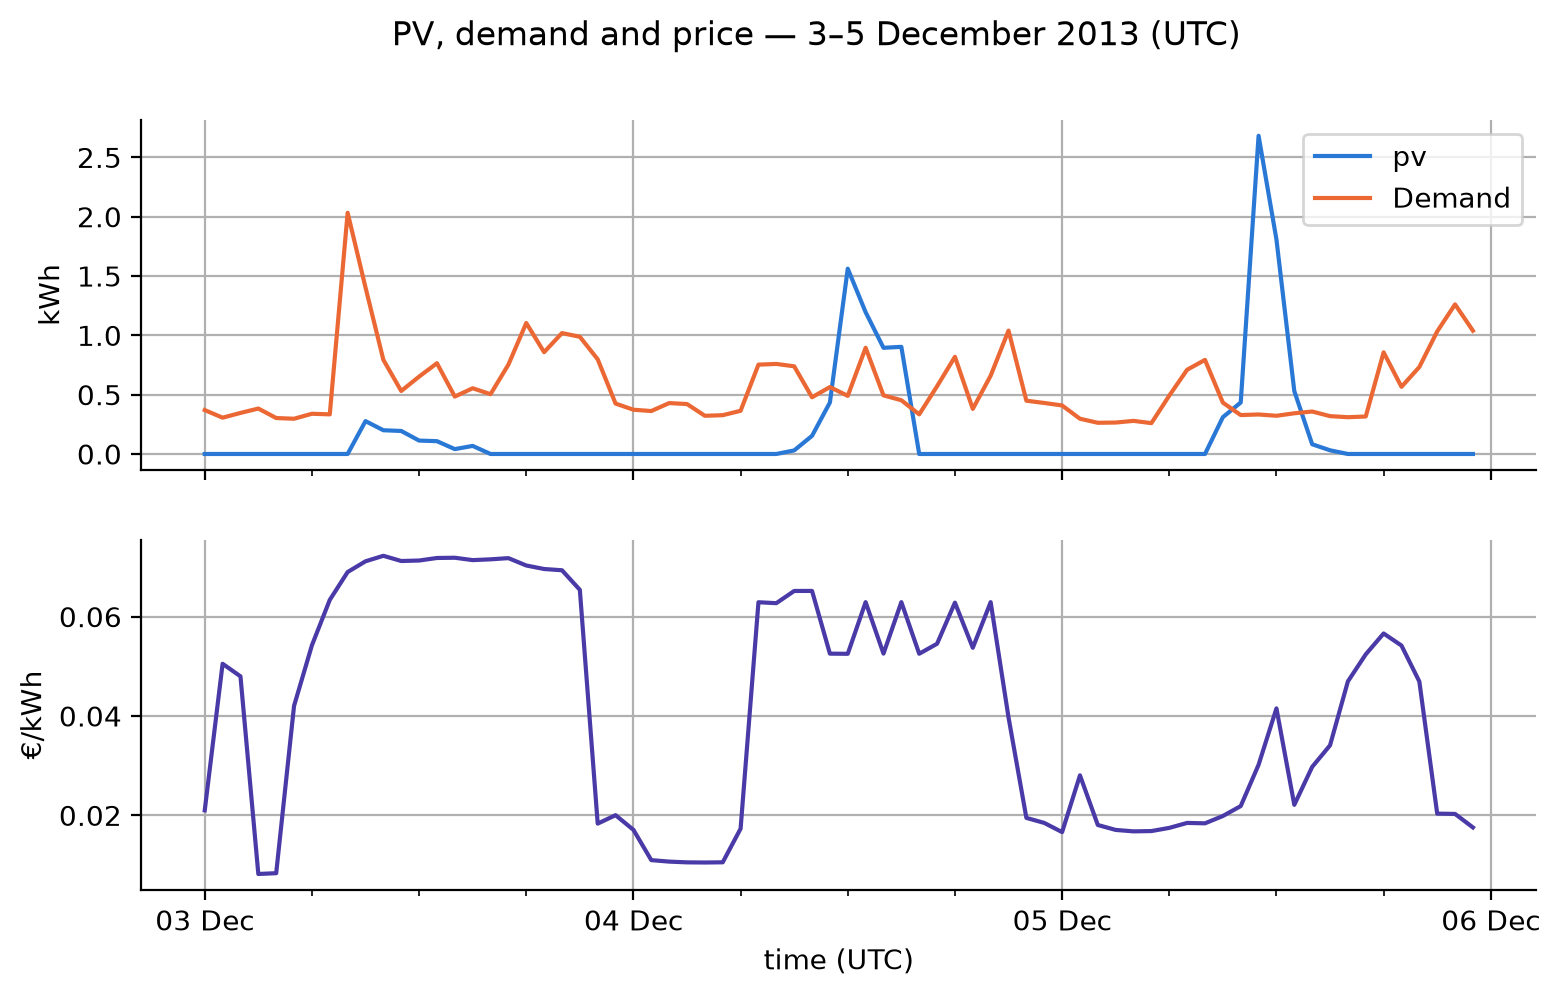

In [5]:
project.plot_pv_demand_price(df)
show(project.FIGURE_NAME)

### Decomposition and demand profiles
Additive MSTL decomposition with daily and weekly periods, then the average day by weekday/weekend and by season.

Filled 1 missing timestamp(s) by interpolation: [Timestamp('2013-12-31 23:00:00+0000', tz='UTC')]
Periods (h): (24, 168)
Max |Yt - (Tt + St + Rt)|: 8.88e-16
Variance share of Yt:
Tt   0.051
St   0.365
Rt   0.502
Seasonal strength Fs: 0.461
Trend strength Ft:    0.121

Component summary (kWh):
             Yt        Tt        St        Rt
count 8,760.000 8,760.000 8,760.000 8,760.000
mean      0.531     0.531     0.000    -0.000
std       0.375     0.085     0.226     0.266
min       0.000     0.275    -0.478    -0.868
25%       0.283     0.489    -0.181    -0.128
50%       0.376     0.540    -0.019    -0.019
75%       0.656     0.578     0.140     0.059
max       4.402     0.719     1.176     2.986

Saved components to ./data/processed/266083_demand_decomposition.csv


Saved figure to ./outputs/figures/demand_decomposition.png
Saved figure to ./outputs/figures/demand_decomposition_2014-01-13_26.png


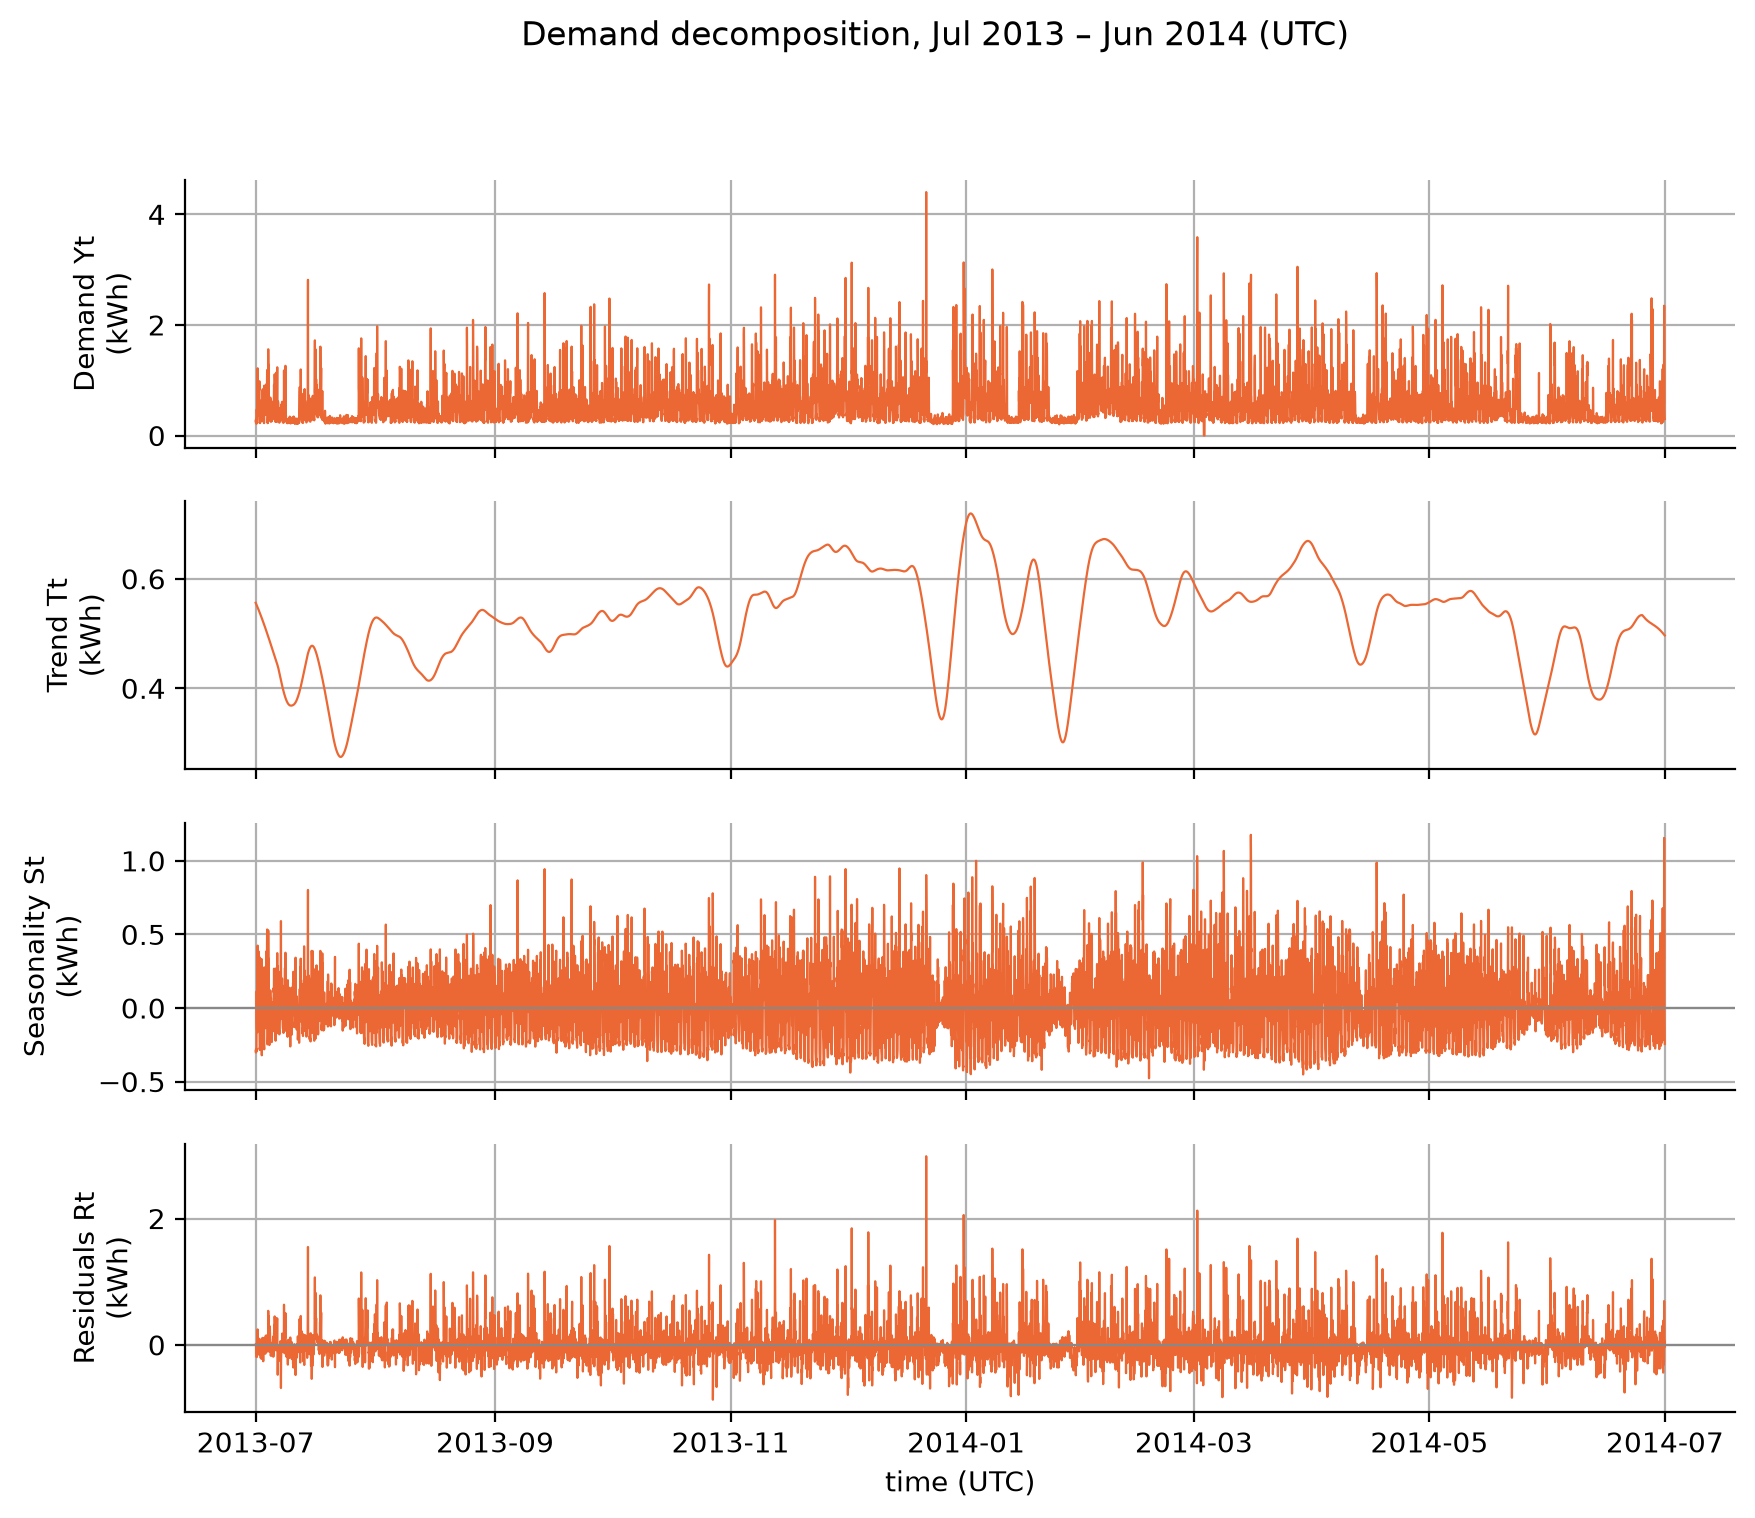

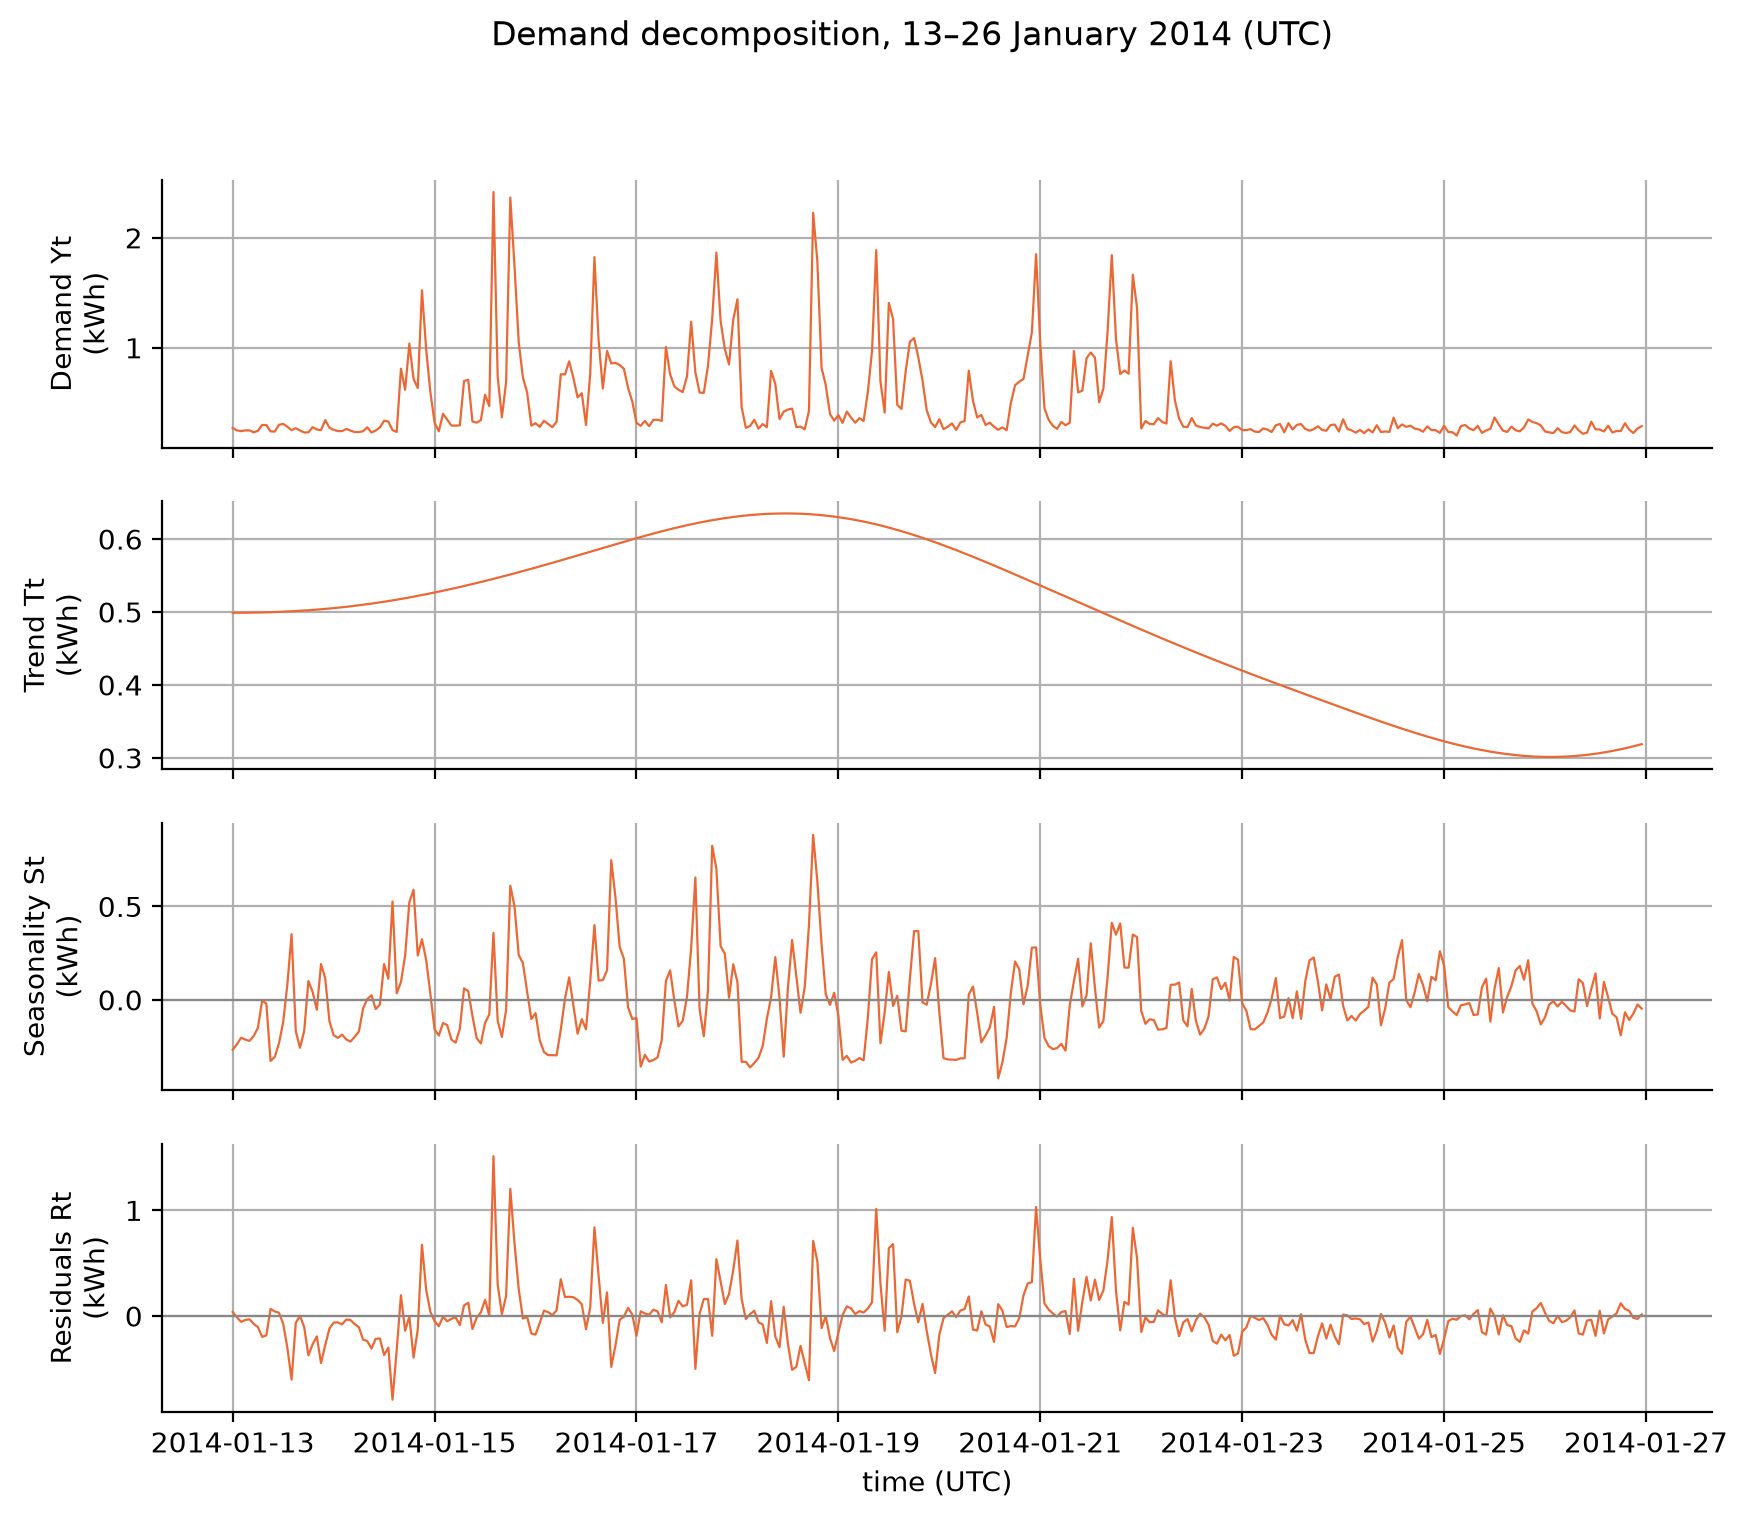

In [6]:
components = project.decompose_demand(df)
show(project.DECOMPOSITION_FIGURE, project.DECOMPOSITION_ZOOM_FIGURE)

Mean demand by hour of day (kWh, hours in UTC):
group  All days  Weekday  Weekend  Winter  Spring  Summer  Autumn
hour                                                             
0         0.347    0.348    0.345   0.425   0.326   0.303   0.335
1         0.300    0.299    0.300   0.324   0.294   0.278   0.303
2         0.291    0.292    0.288   0.310   0.285   0.270   0.300
3         0.284    0.287    0.276   0.307   0.275   0.268   0.286
4         0.282    0.282    0.283   0.286   0.283   0.272   0.289
5         0.307    0.310    0.300   0.294   0.313   0.297   0.325
6         0.397    0.423    0.330   0.332   0.380   0.420   0.452
7         0.578    0.613    0.489   0.502   0.630   0.563   0.615
8         0.675    0.682    0.658   0.698   0.715   0.612   0.676
9         0.659    0.621    0.753   0.668   0.786   0.572   0.607
10        0.643    0.629    0.678   0.639   0.771   0.505   0.657
11        0.570    0.573    0.563   0.619   0.552   0.489   0.623
12        0.593    0.608    

Saved figure to ./outputs/figures/demand_profiles.png


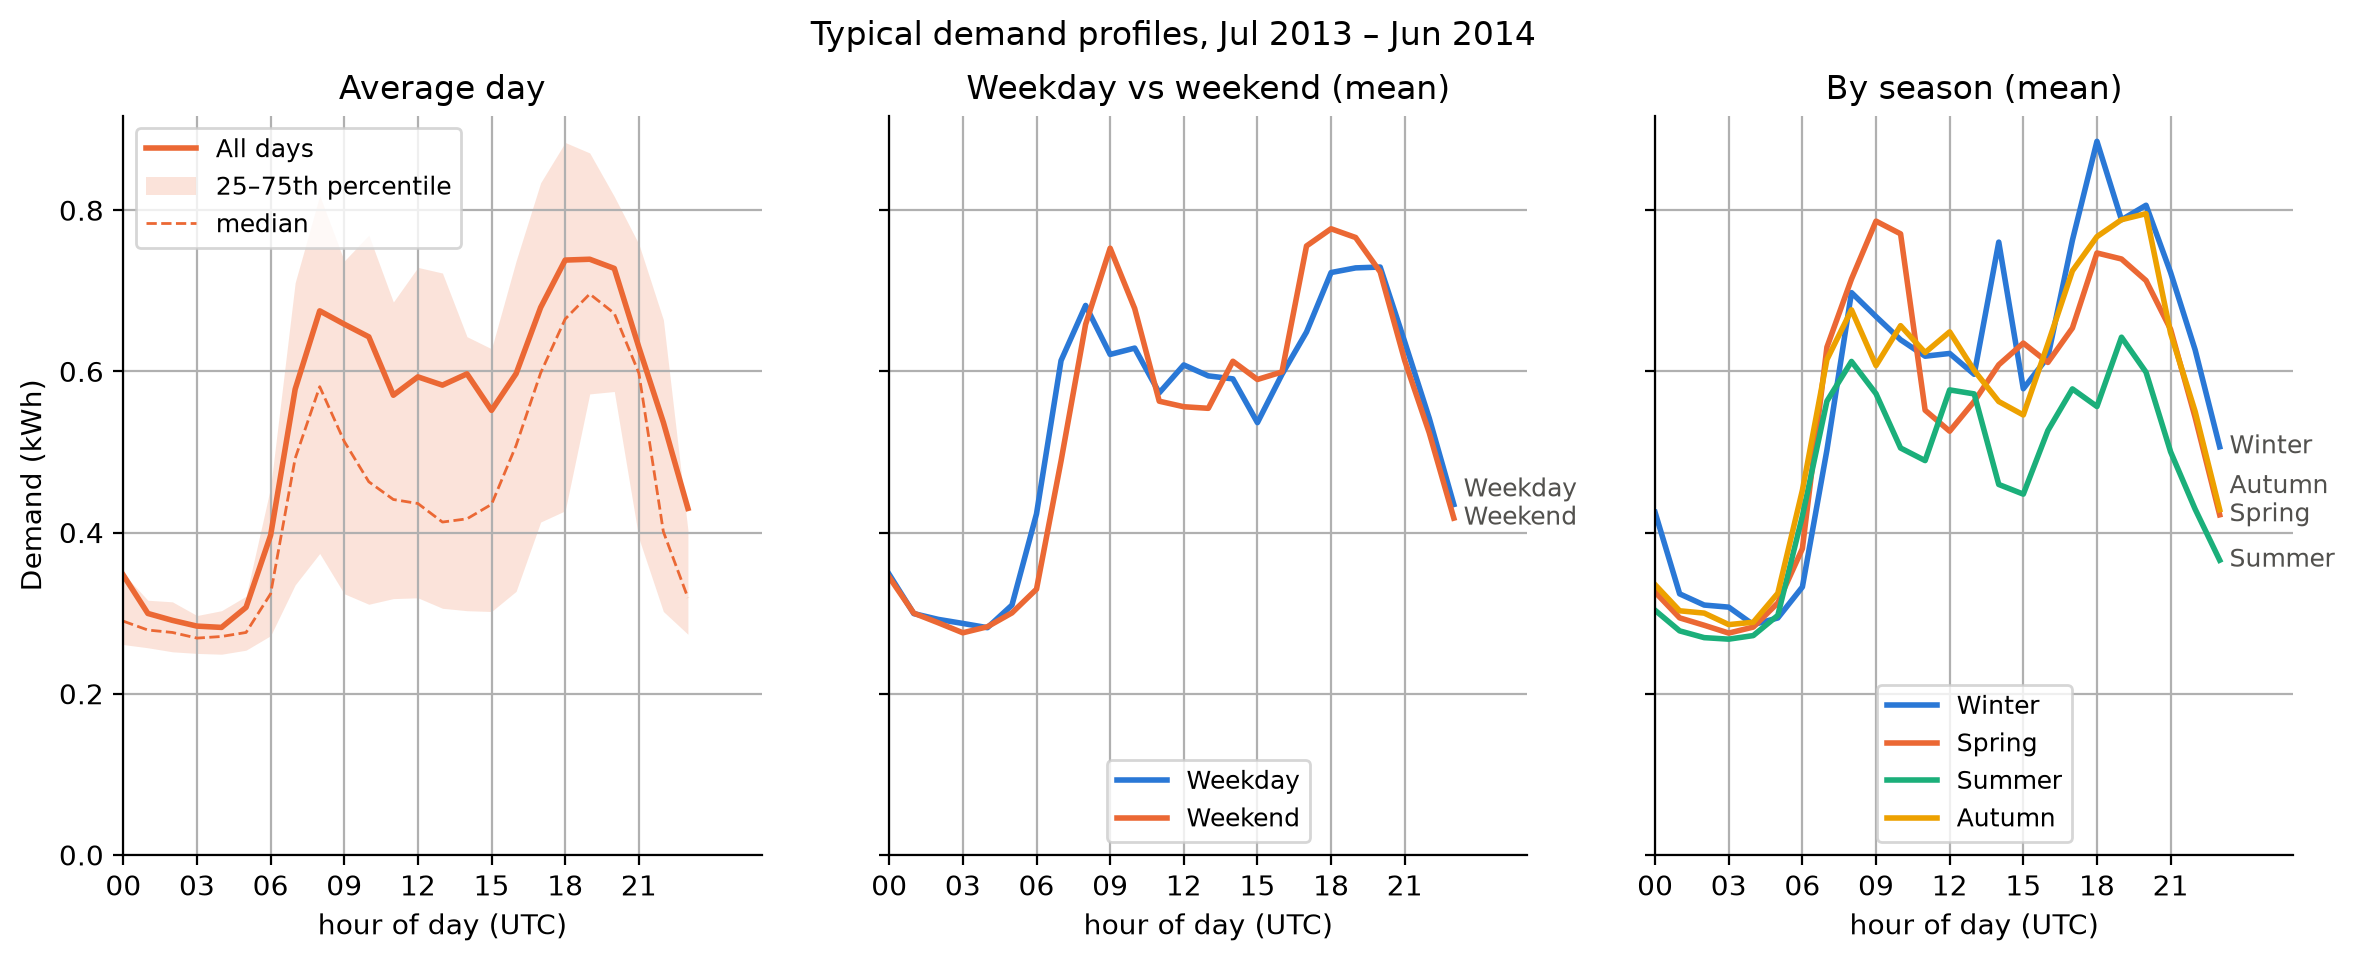

In [7]:
profiles = project.demand_profiles(df)
show(project.PROFILES_FIGURE)

### Demand, PV and price over the year

Summary statistics (Demand and pv in kWh, Price in €/kWh):
variable     Demand        pv   pv_mod1   pv_mod2   pv_mod3     Price
n         8,759.000 8,759.000 8,322.000 8,268.000 8,249.000 8,759.000
n_missing     0.000     0.000   437.000   491.000   510.000     0.000
mean          0.531     0.660     0.660     0.519     0.588     0.046
std           0.375     1.107     1.110     0.927     1.045     0.025
min           0.000     0.000     0.000     0.000     0.000     0.000
p1            0.224     0.000     0.000     0.000     0.000     0.001
p25           0.283     0.000     0.000     0.000     0.000     0.028
median        0.376     0.000     0.000     0.000     0.000     0.045
p75           0.656     0.817     0.812     0.604     0.661     0.060
p99           1.985     4.193     4.197     3.706     4.140     0.110
max           4.402     4.888     4.888     4.491     4.888     0.255
skew          2.488     1.782     1.786     2.011     1.967     1.200
kurtosis      8.899     2.120  

Saved figure to ./outputs/figures/timeseries_demand_pv_price.png


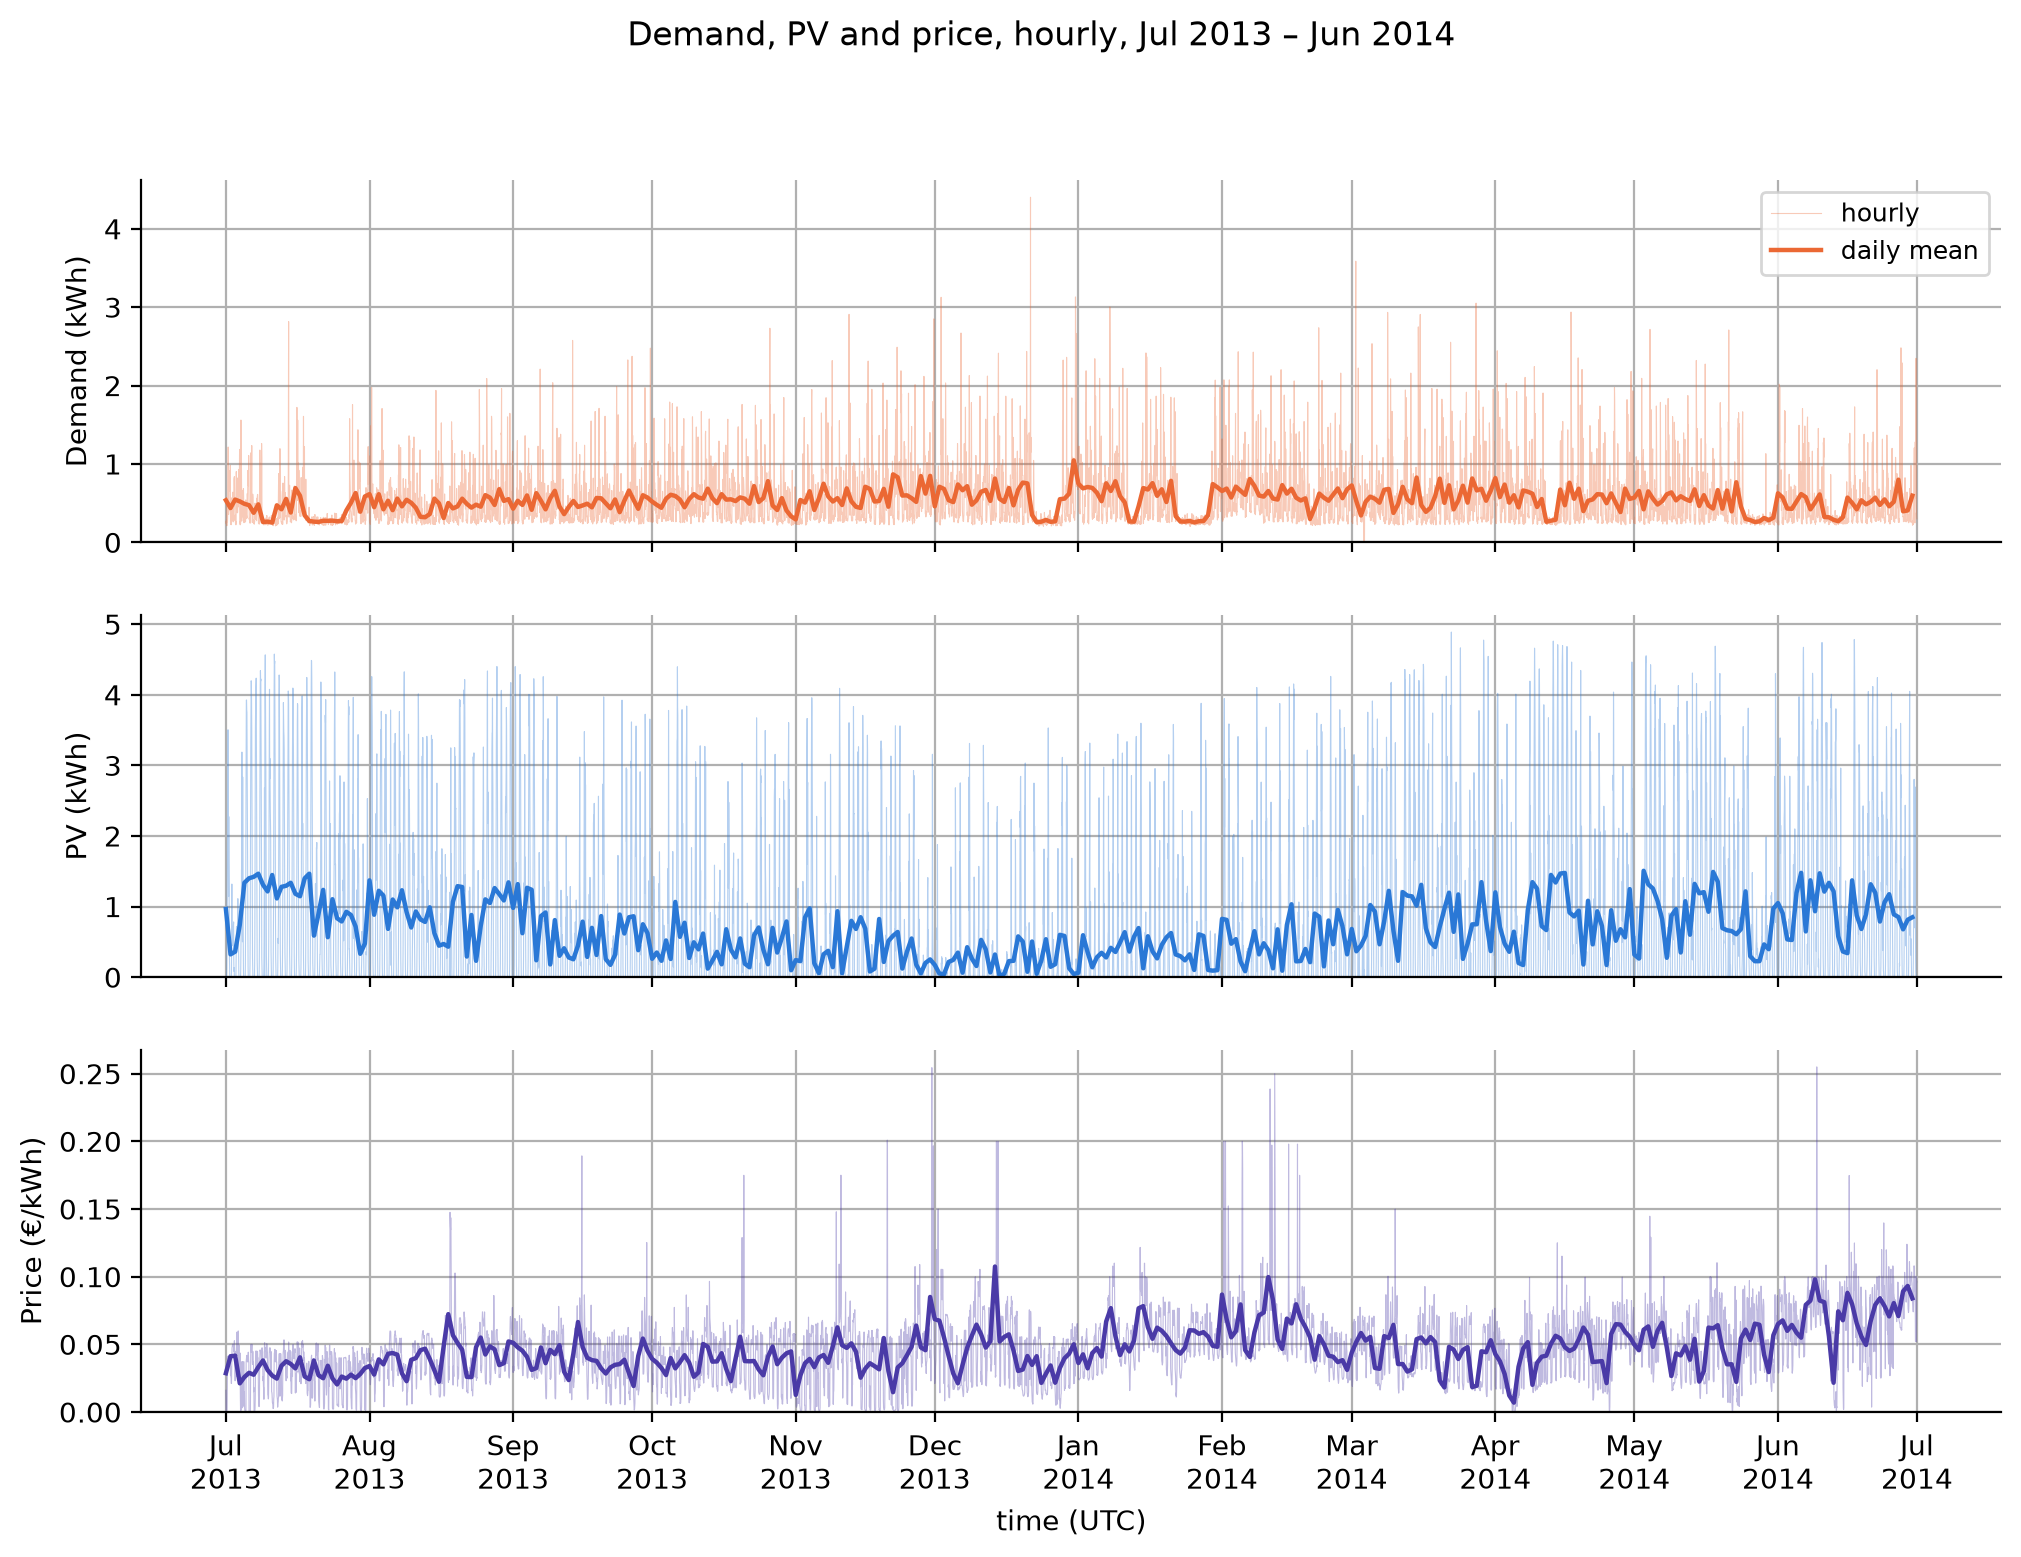

In [8]:
summary = project.summarize_demand_pv_price(df)
show(project.TIMESERIES_FIGURE)

Demand (kWh) [all hours]: n=8,759  p5=0.239  median=0.376  p95=1.267  skew=2.49  above 1.5xIQR fence (1.216): 5.8%
PV (kWh) [hours with pv > 0 only (53% of hours are 0)]: n=4,125  p5=0.067  median=0.929  p95=3.868  skew=0.80  above 1.5xIQR fence (5.271): 0.0%
Price (€/kWh) [all hours]: n=8,759  p5=0.009  median=0.045  p95=0.086  skew=1.20  above 1.5xIQR fence (0.109): 1.1%
Saved figure to ./outputs/figures/distributions_demand_pv_price.png
Days with PV > demand (daily totals): 207 of 365
Share of days with PV > demand, by month:
timestamp
2013-07    87%
2013-08    87%
2013-09    60%
2013-10    26%
2013-11    27%
2013-12    13%
2014-01    29%
2014-02    36%
2014-03    68%
2014-04    73%
2014-05    77%
2014-06    97%


Saved figure to ./outputs/figures/demand_vs_pv_with_price.png
Monthly PV production vs demand (kWh):
             pv  Demand      net
month                           
2013-07 757.300 306.900  450.400
2013-08 684.900 363.400  321.500
2013-09 451.100 365.500   85.600
2013-10 319.000 404.400  -85.400
2013-11 300.200 427.800 -127.600
2013-12 191.600 420.600 -229.000
2014-01 272.000 400.500 -128.500
2014-02 337.900 409.300  -71.400
2014-03 582.400 432.500  149.800
2014-04 591.900 397.000  194.900
2014-05 606.700 368.400  238.300
2014-06 686.200 351.300  334.900
Months where PV falls short: 2013-10, 2013-11, 2013-12, 2014-01, 2014-02
Saved ./outputs/tables/266083_monthly_pv_vs_demand.csv
Saved figure to ./outputs/figures/monthly_pv_vs_demand.png


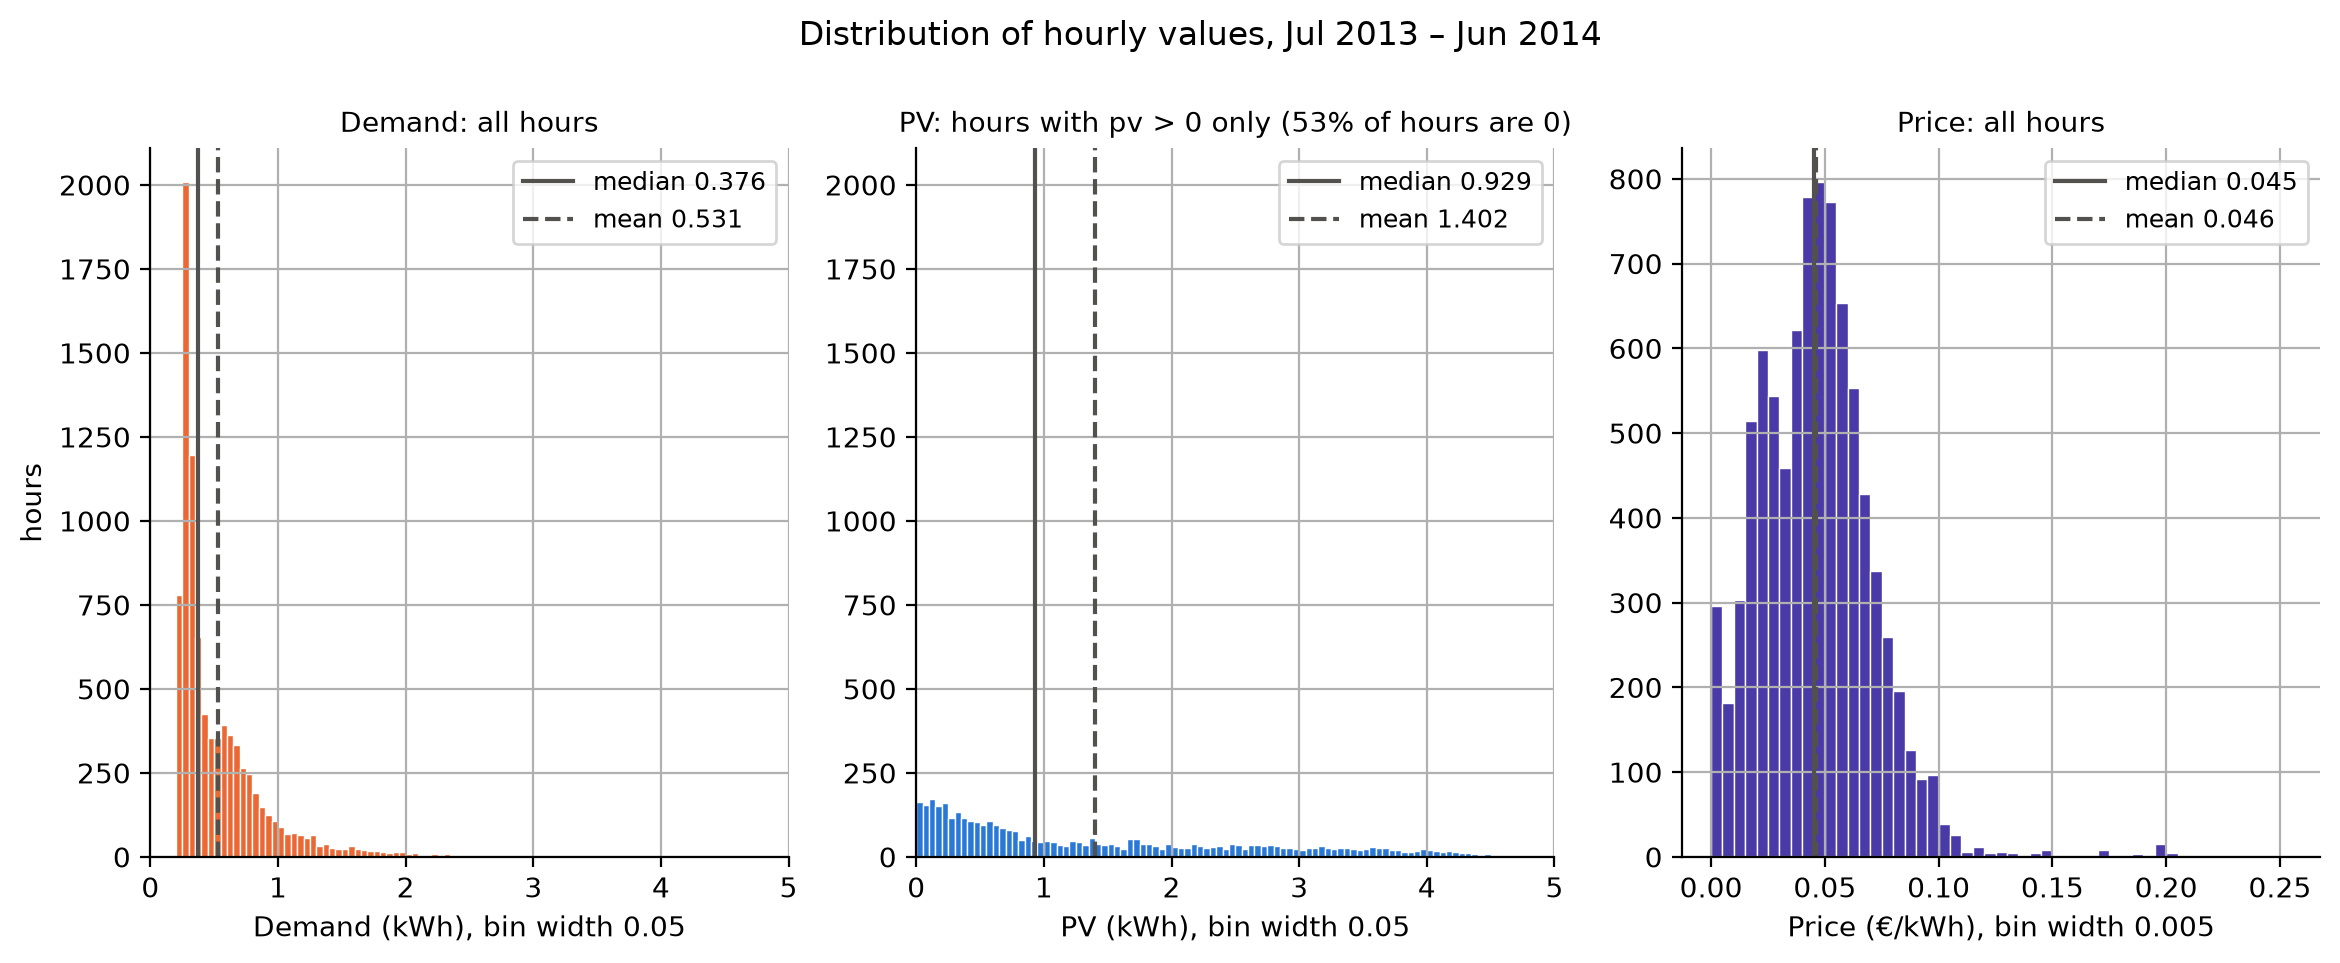

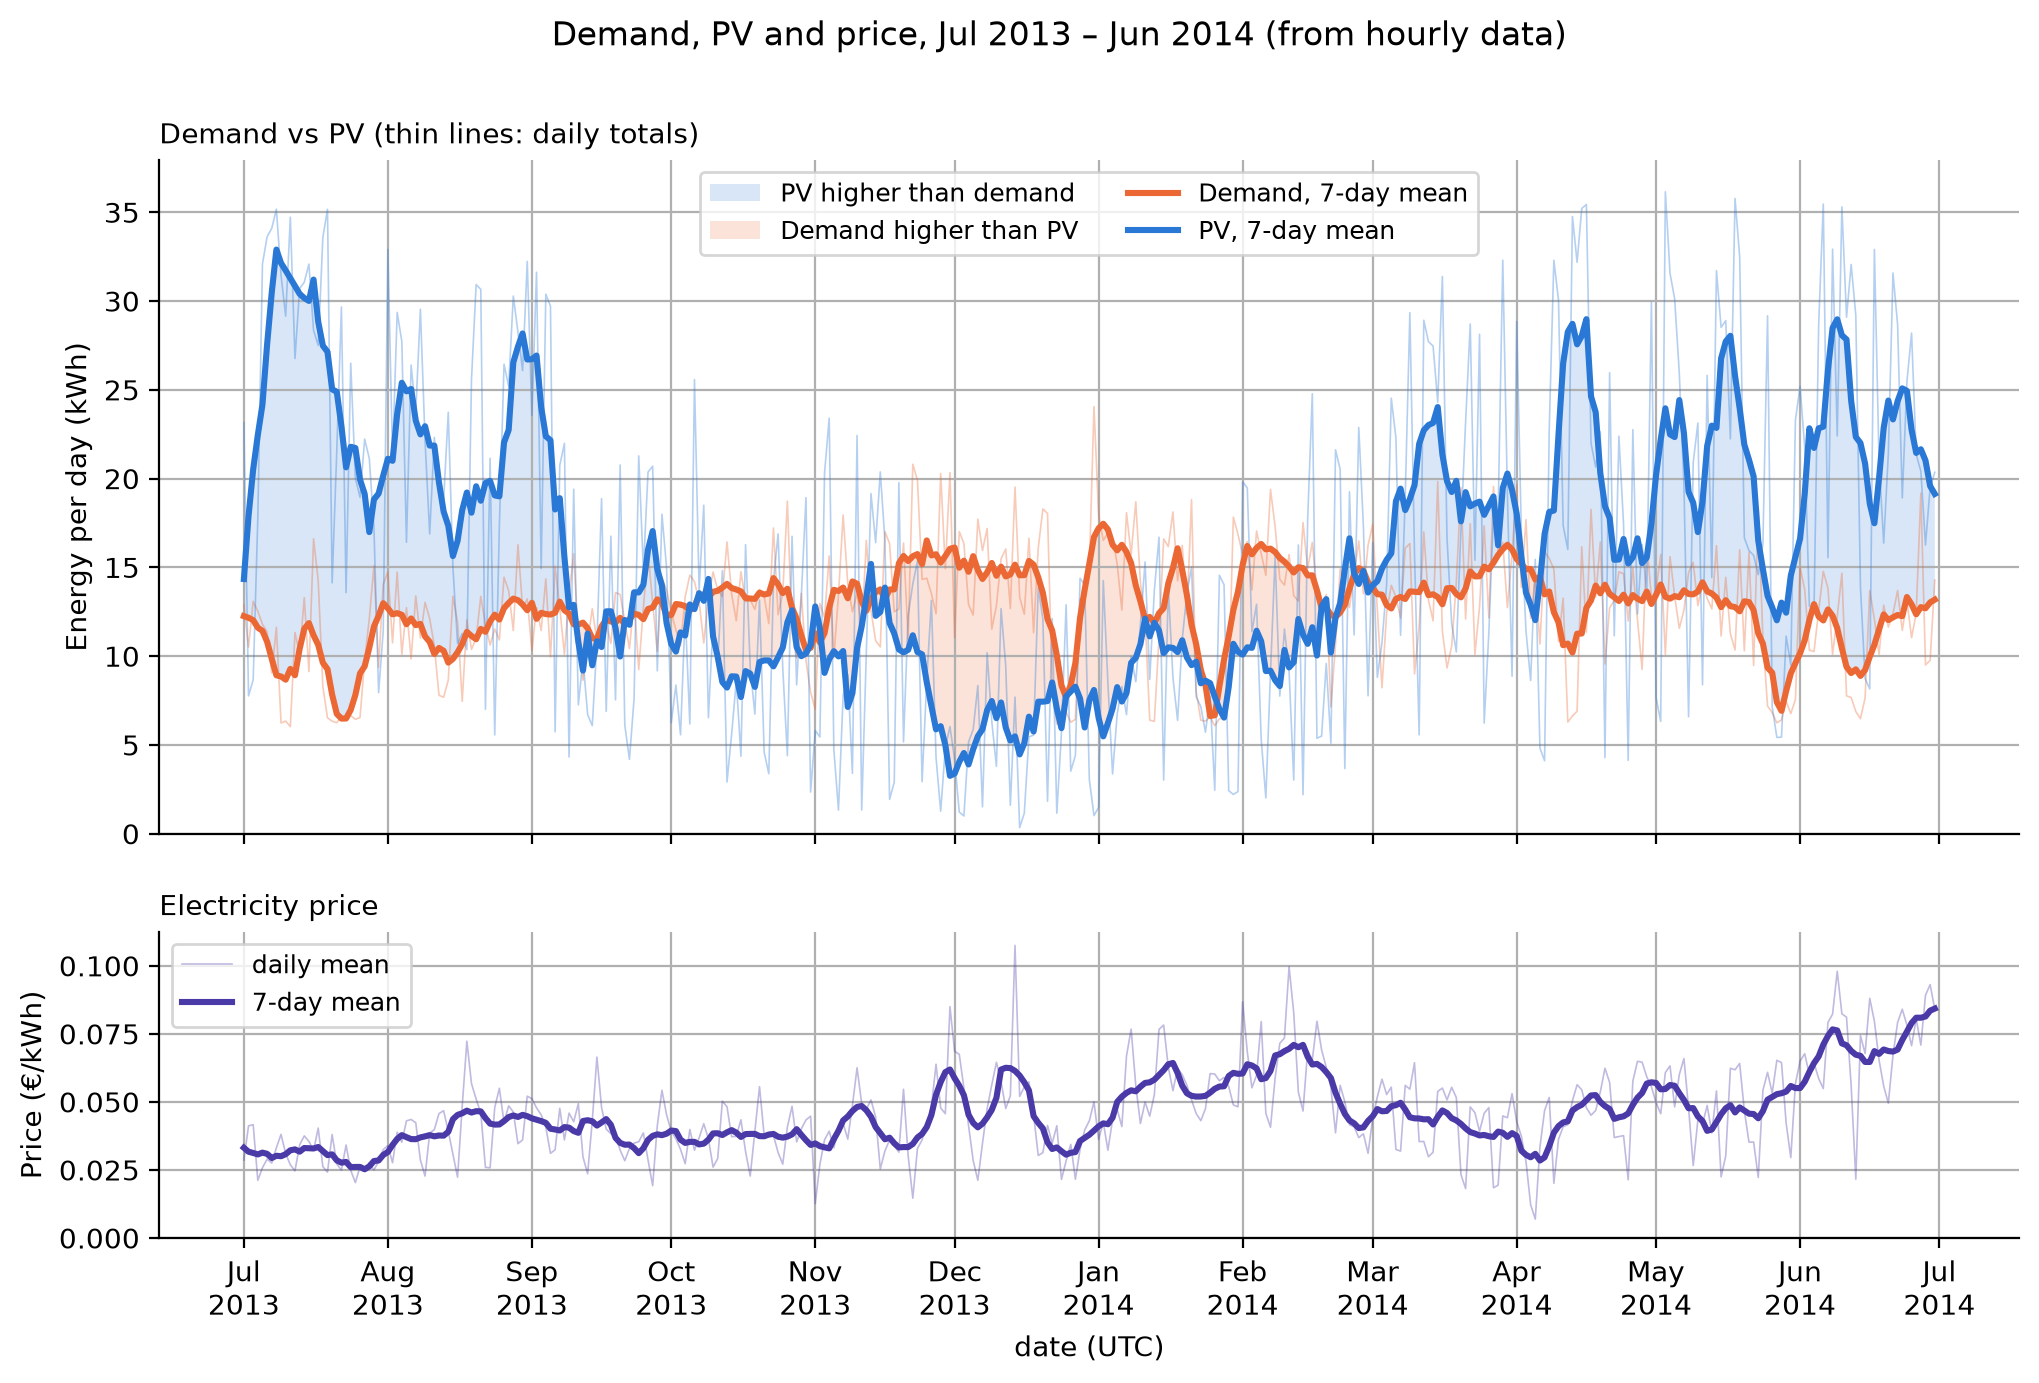

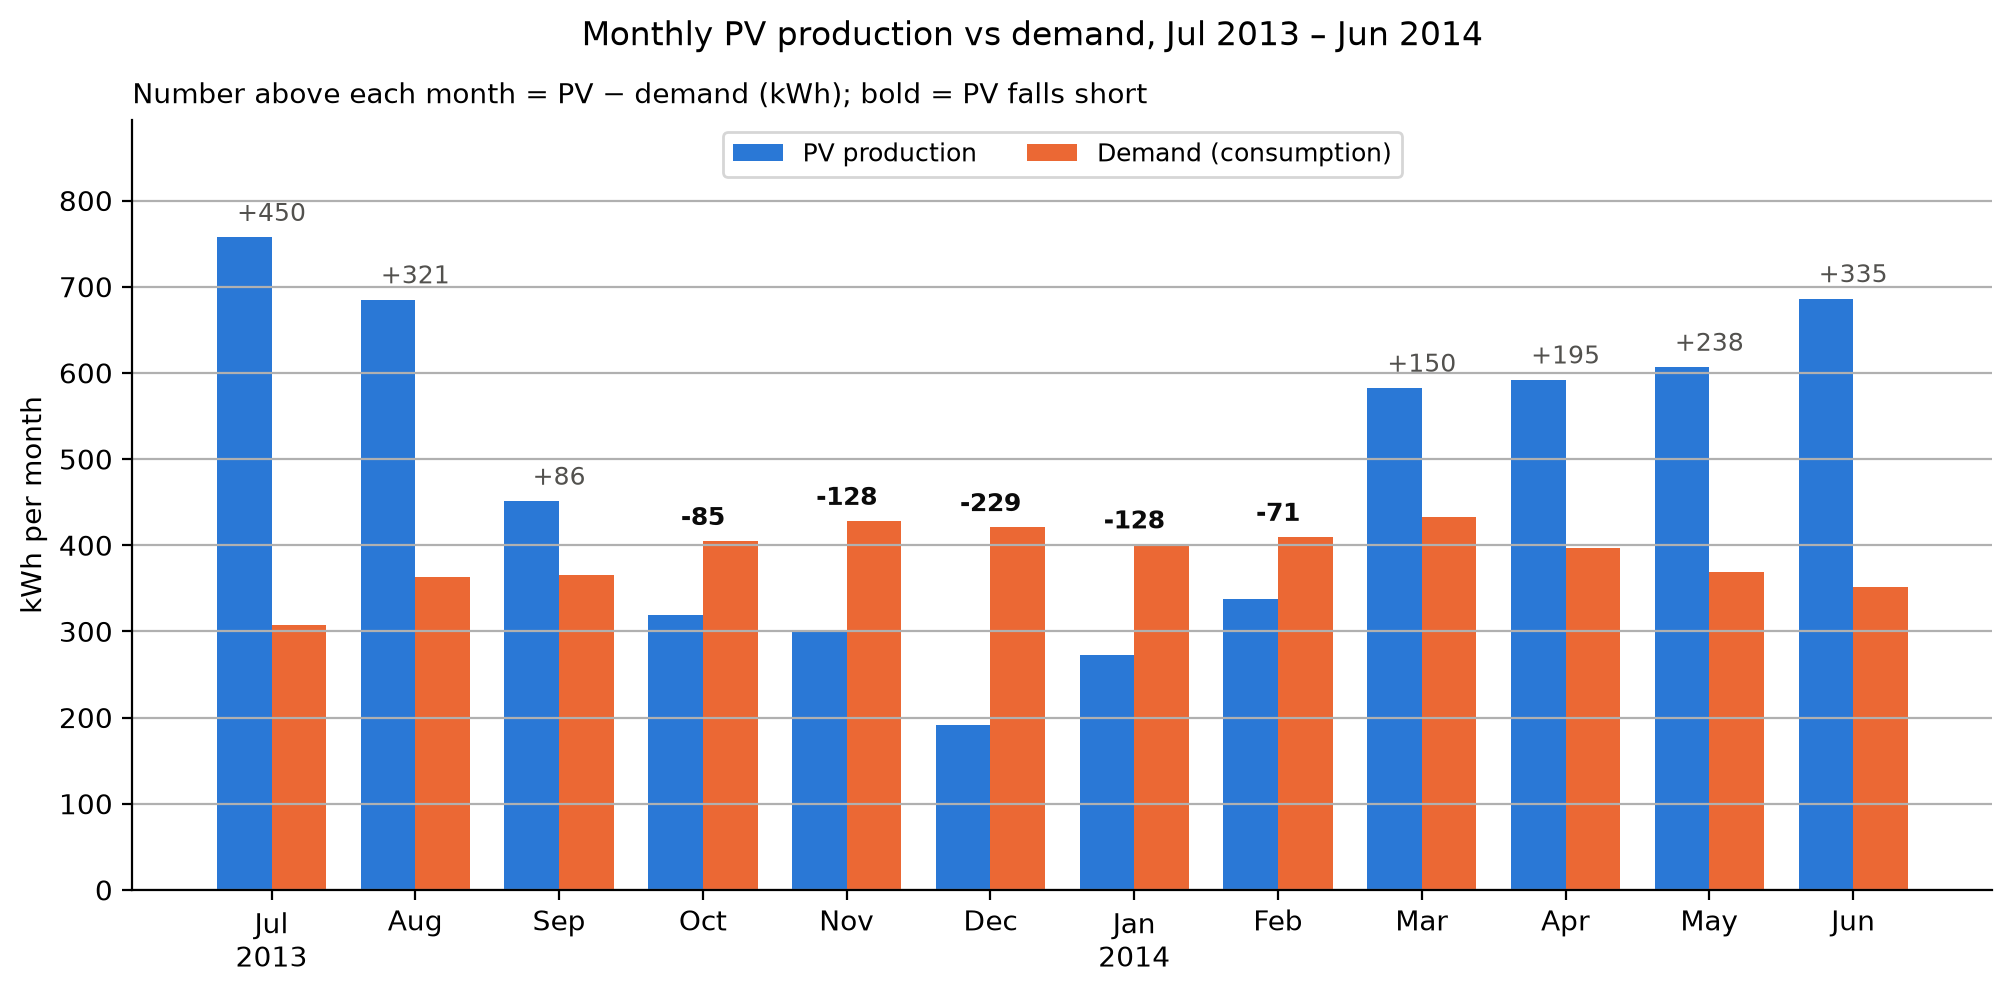

In [9]:
project.describe_distributions(df)
project.plot_distributions(df)
project.plot_demand_vs_pv(df)
project.plot_monthly_pv_vs_demand(df)
show(project.HISTOGRAM_FIGURE, project.BALANCE_FIGURE, project.MONTHLY_BALANCE_FIGURE)

# Part 2 — Missing values in `pv_mod1`

`pv_mod1`, `pv_mod2` and `pv_mod3` are exact copies of the complete `pv` column wherever they are present, so `pv` gives
the true value behind every gap. The mechanisms differ: `pv_mod1` gaps are **MCAR**, `pv_mod2` gaps are **MNAR**
(high output goes missing), `pv_mod3` gaps are **MAR** (missing exactly when temperature > 20 °C).

For `pv_mod1` we compare **listwise deletion**, two **univariate** methods (mean, linear interpolation) and two
**multivariate** methods (KNN, MICE with Extra Trees), scored against the true values. `pv` is never an input.

pv_mod1: 437 missing of 8,759 hours; scored on those hours against pv
                            family     n  mean   std     total   MAE  RMSE   bias     R2
method                                                                                  
Listwise deletion         Deletion  8322 0.660 1.110 5,495.792   NaN   NaN    NaN    NaN
Mean imputation         Univariate  8759 0.660 1.082 5,784.384 0.817 1.049  0.007 -0.000
Linear interpolation    Univariate  8759 0.659 1.104 5,770.860 0.191 0.387 -0.024  0.864
KNN imputation (k=5)  Multivariate  8759 0.657 1.098 5,752.757 0.305 0.599 -0.065  0.674
MICE (Extra Trees)    Multivariate  8759 0.657 1.099 5,758.298 0.287 0.562 -0.052  0.713
True values (pv)         Reference  8759 0.660 1.107 5,781.208   NaN   NaN    NaN    NaN

Numerical summary of each imputed data set vs the true PV series:
                         n  mean  variance   std   min   p25  median   p75   max  skew  kurtosis  n_zeros     total
method                             

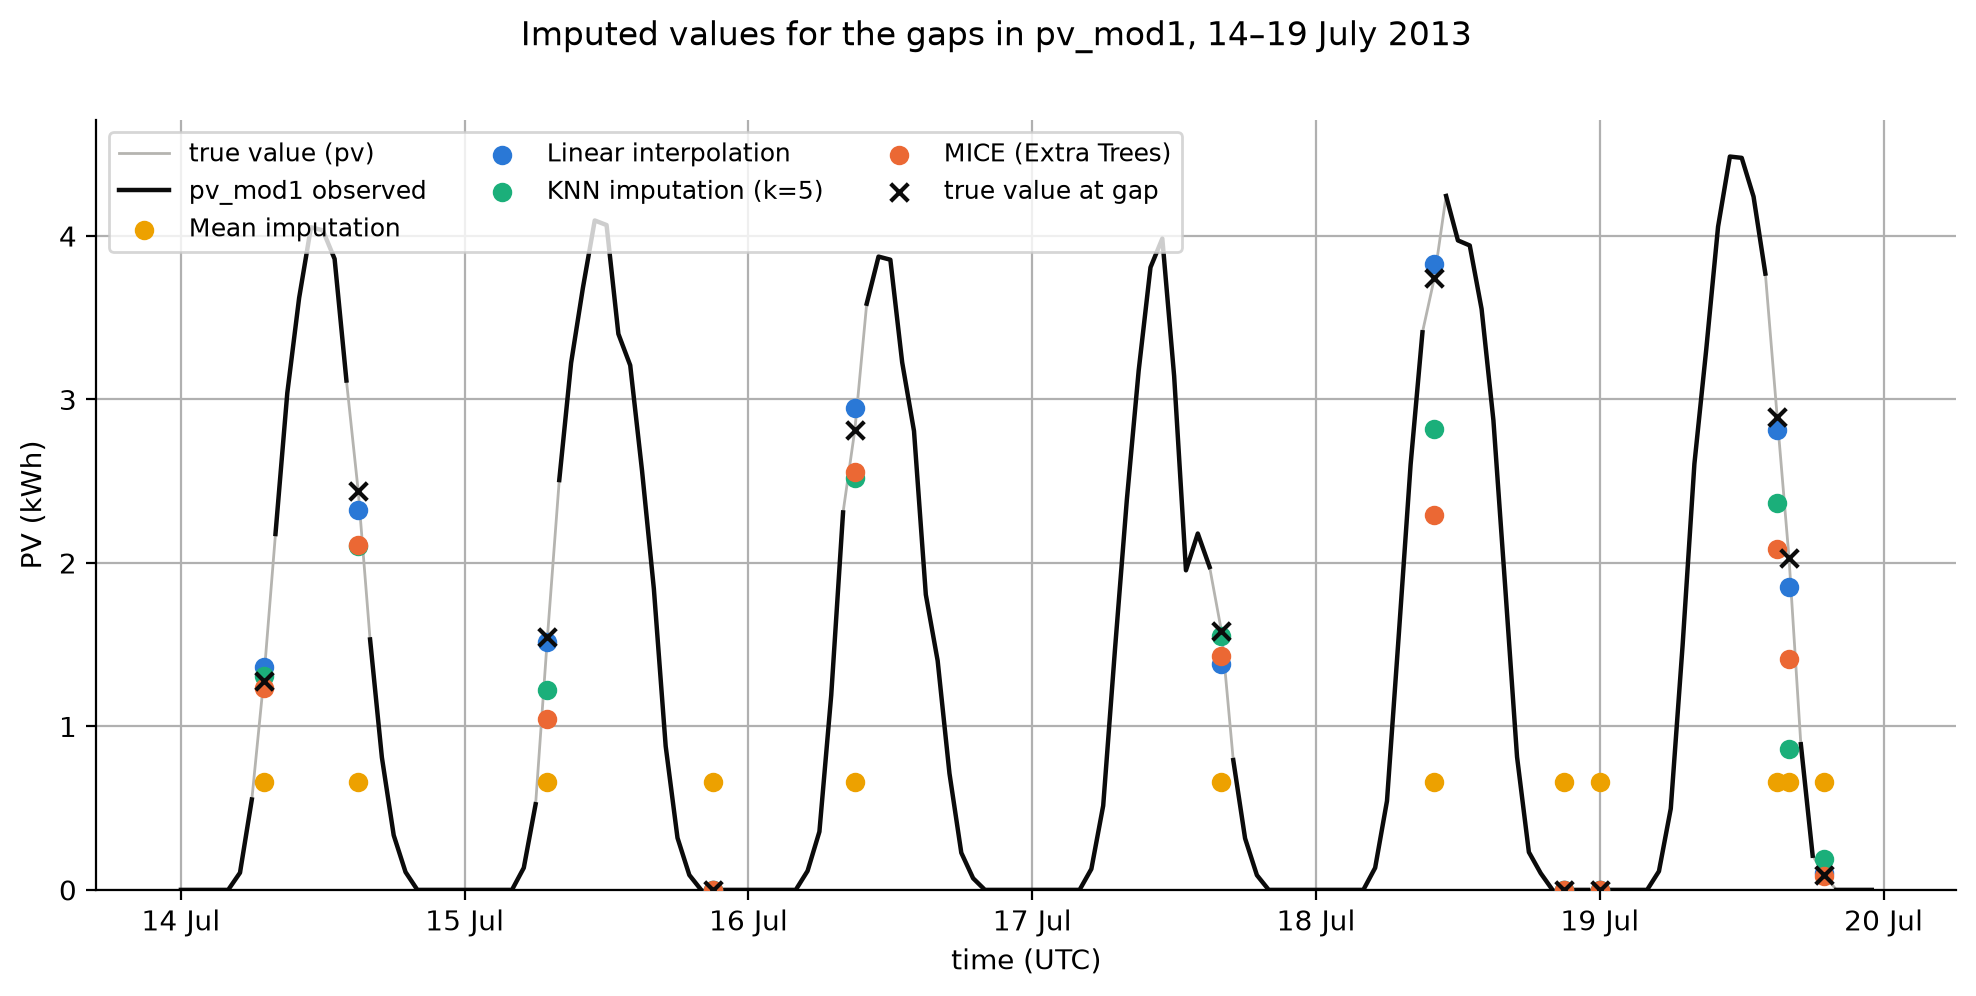

In [10]:
project.impute_pv_mod1(df)
show(project.IMPUTATION_FIGURE)

### Representative gaps, before and after linear interpolation
Night, sunrise edge, clear day, overcast day, the longest (3 h) gap and a variable-cloud worst case.

Saved figure to ./outputs/figures/pv_mod1_interpolation_before_after.png


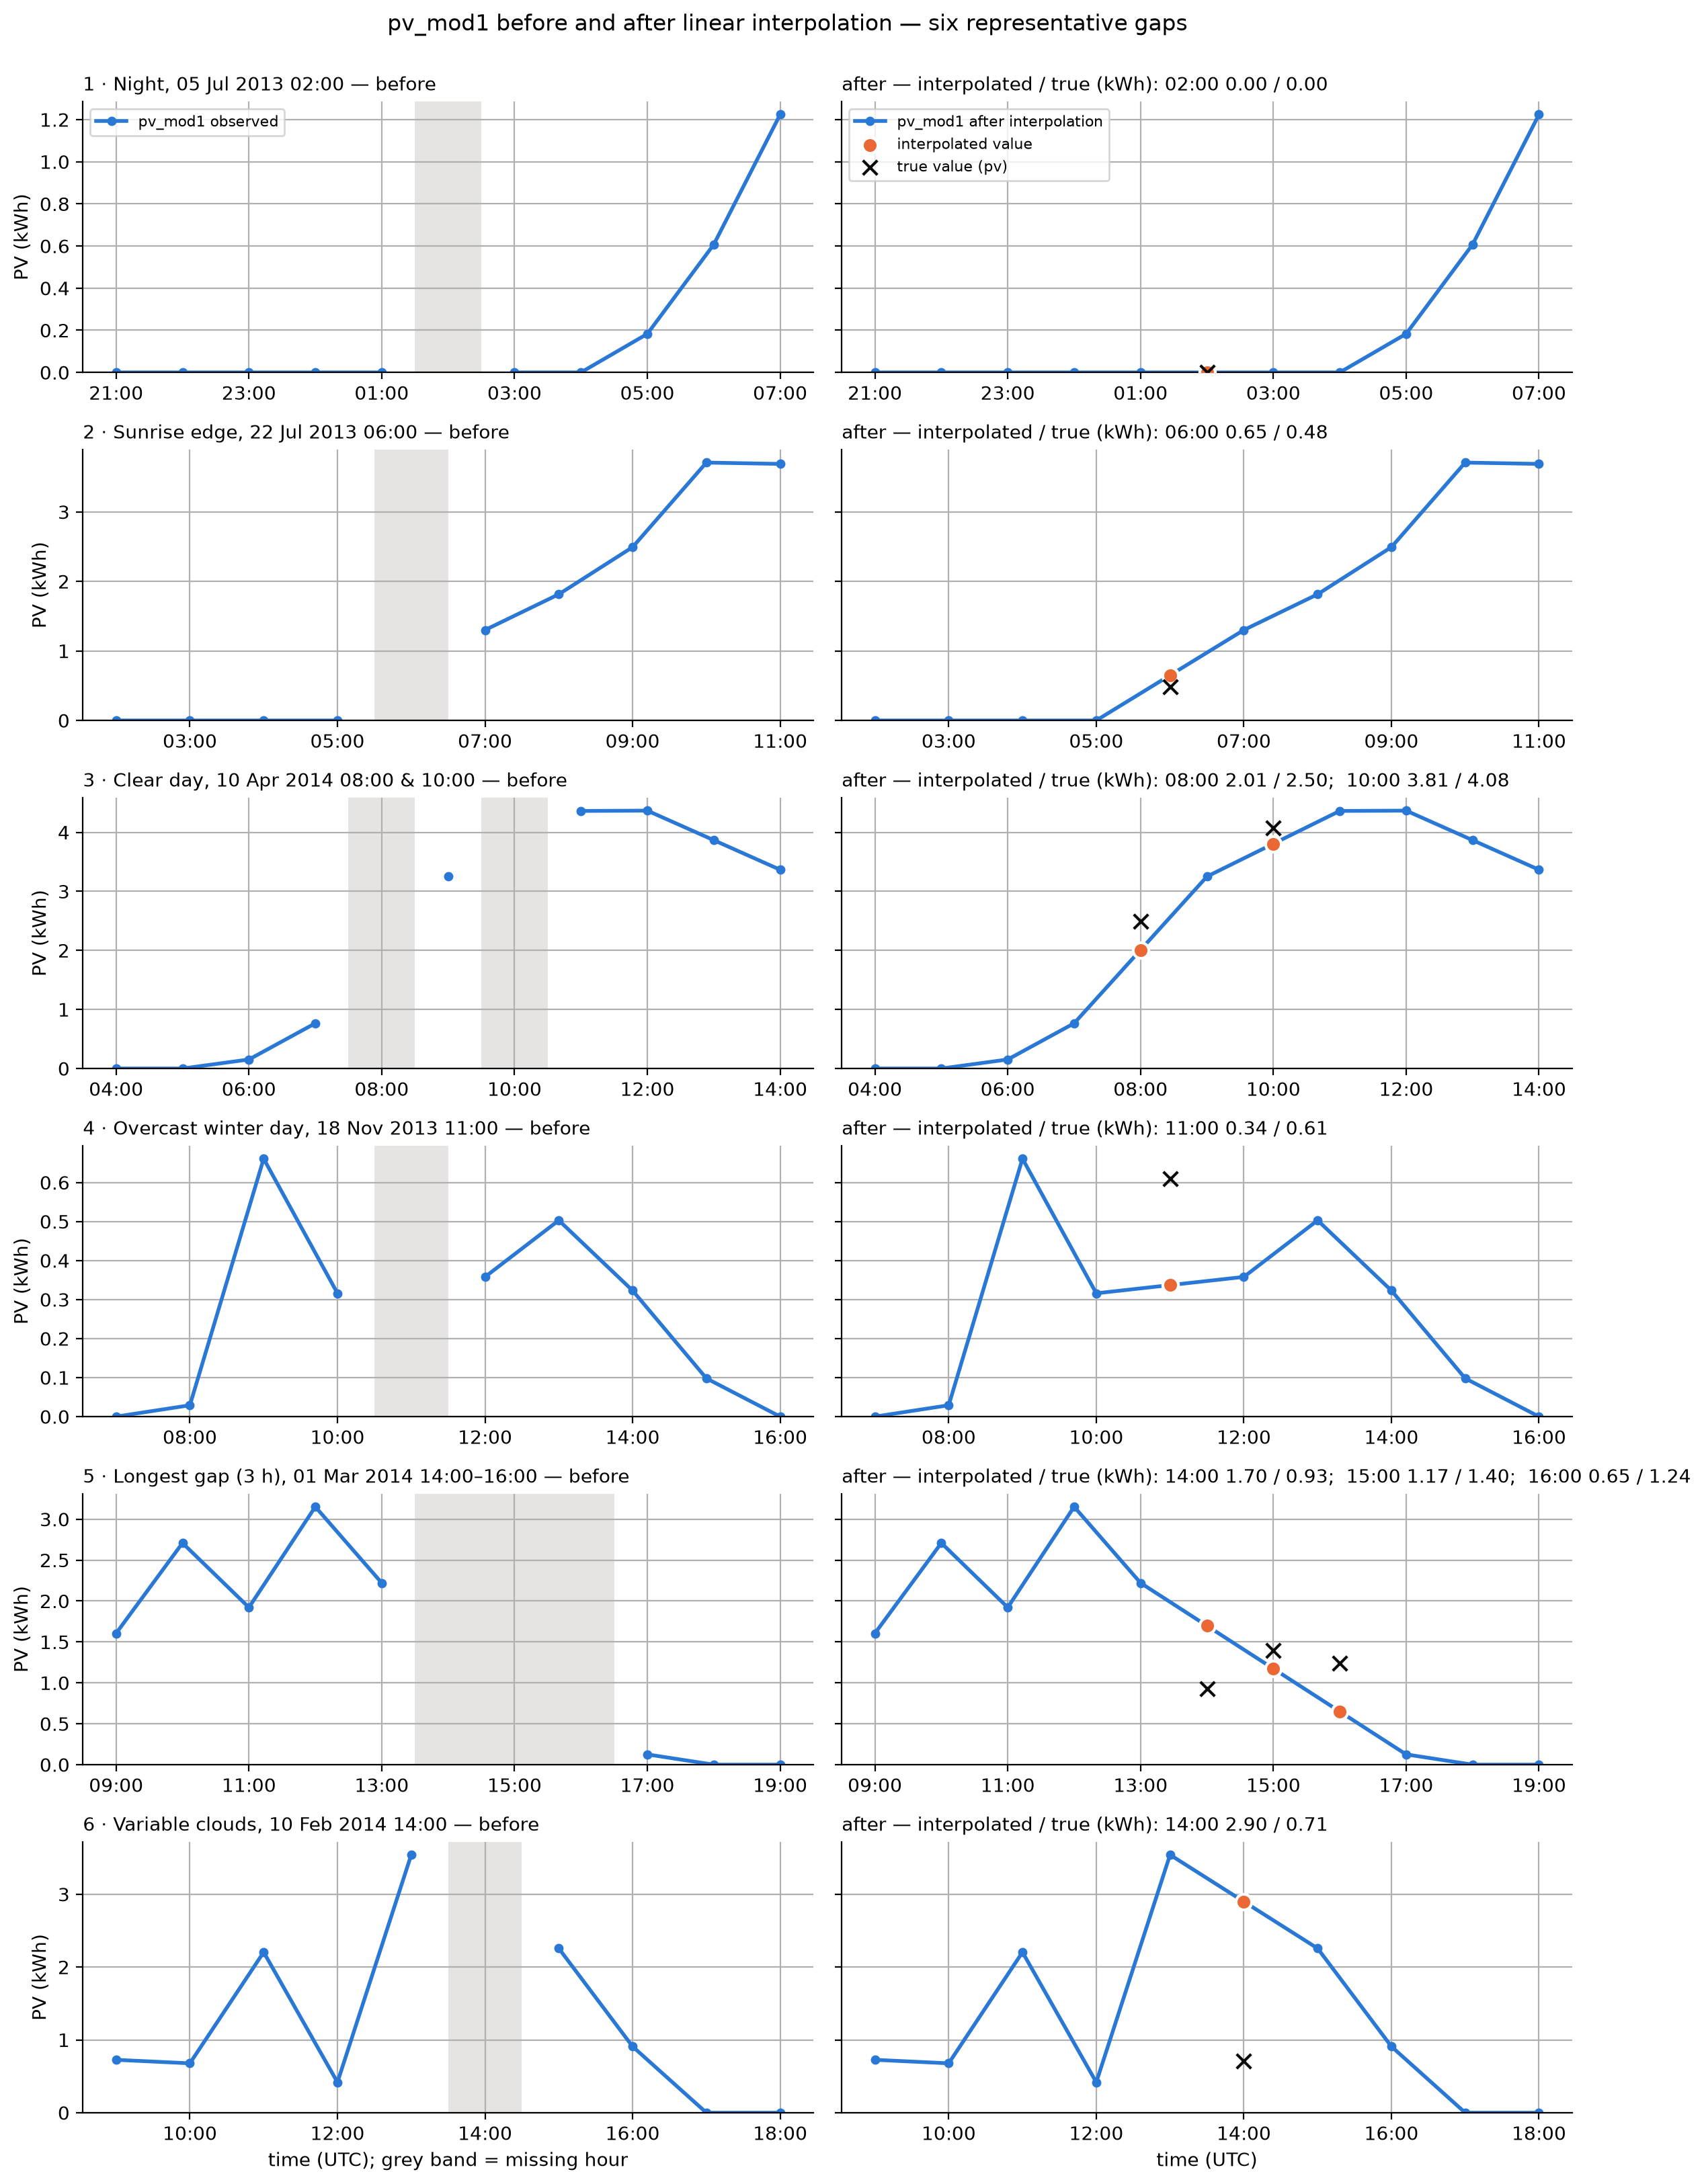

In [11]:
project.plot_interpolation_cases(df)
show(project.INTERPOLATION_FIGURE)

### Physically impossible values and live (causal) imputation
PV cannot be negative, above capacity, or above zero while the sun is down. Then: which methods could run in a live
system that only knows the past, and how well do causal alternatives do?

                      n_negative  n_above_capacity  n_sun_down_gaps  n_pv_while_sun_down  max_pv_while_sun_down           worst_timestamp
method                                                                                                                                   
Mean imputation                0                 0              194                  194                  0.660 2013-07-05 02:00:00+00:00
Linear interpolation           0                 0              194                   12                  0.515 2013-11-13 07:00:00+00:00
KNN imputation (k=5)           0                 0              194                   15                  0.440 2013-11-13 07:00:00+00:00
MICE (Extra Trees)             0                 0              194                    3                  0.042 2013-11-01 07:00:00+00:00
Saved ./outputs/tables/266083_pv_mod1_impossible_values.csv
Saved figure to ./outputs/figures/pv_mod1_impossible_values.png


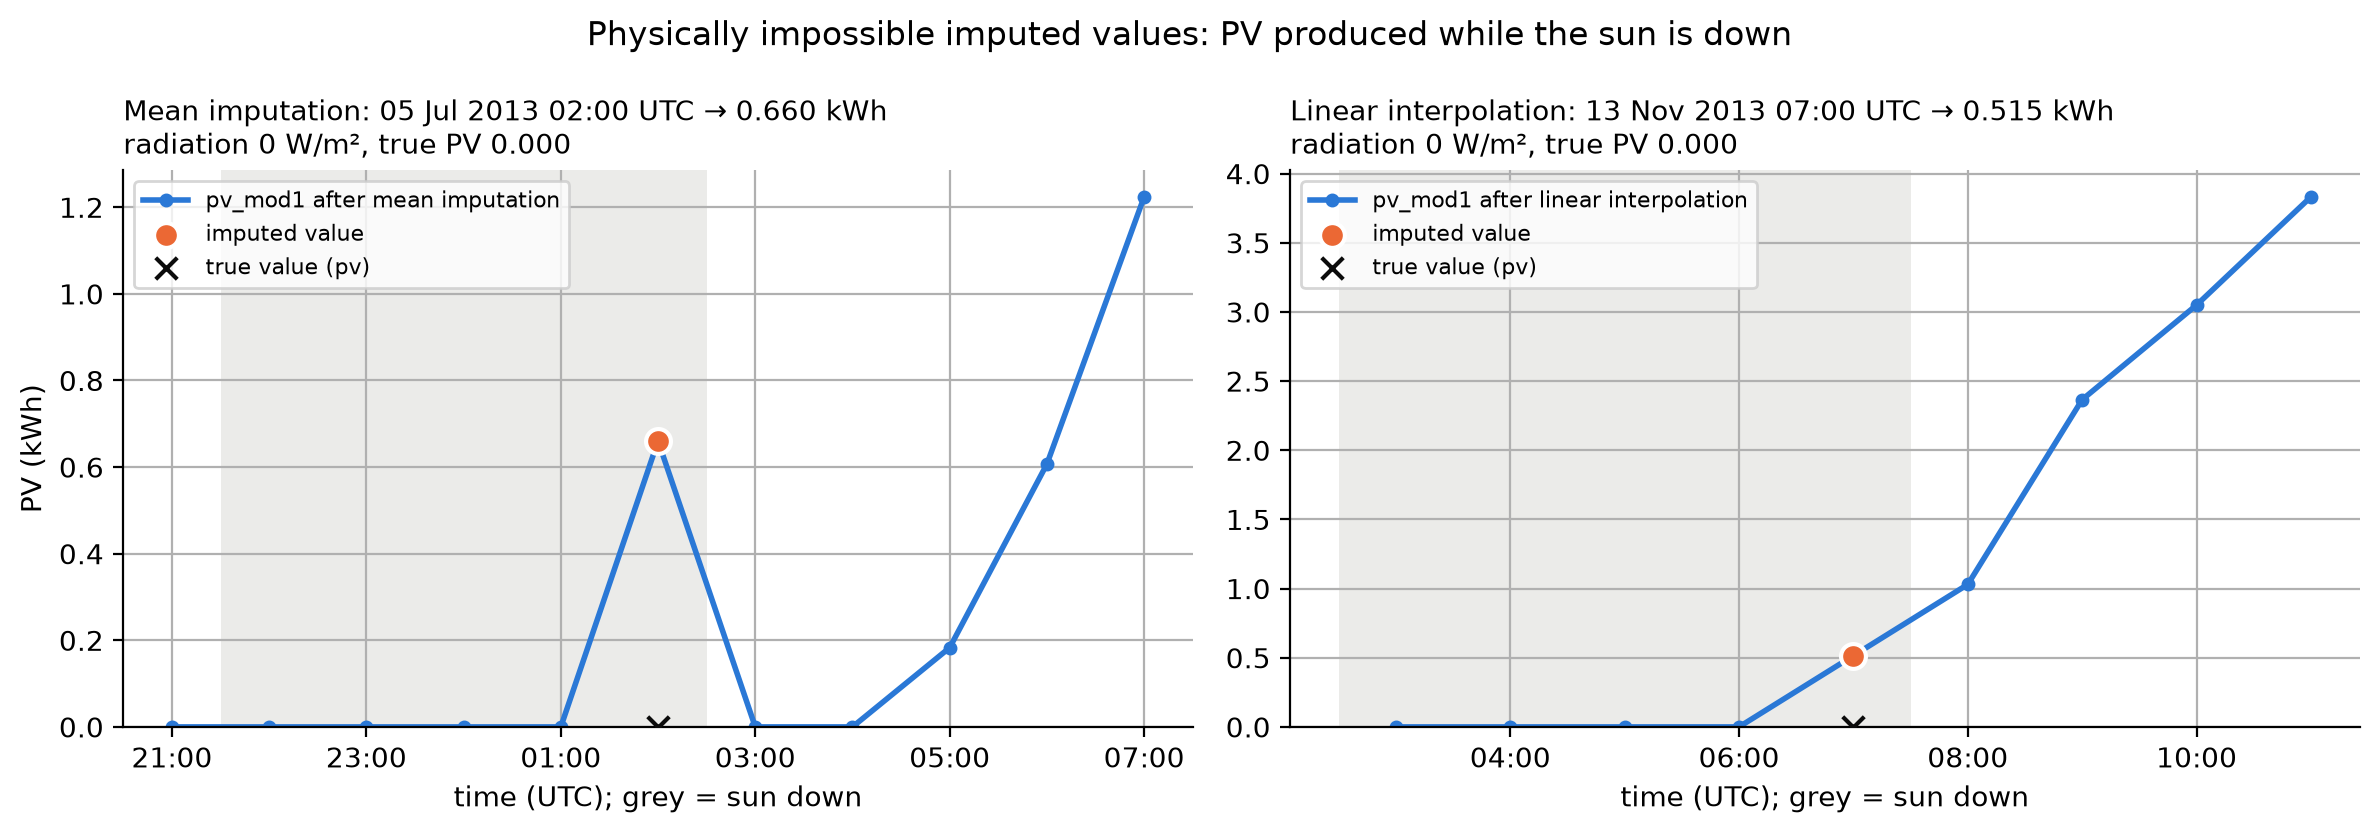

In [12]:
project.check_impossible_values(df)
show(project.IMPOSSIBLE_FIGURE)

In [13]:
project.live_imputation(df)

Live (causal) methods, scored on the missing hours against pv;
offline linear interpolation is shown for reference only:
                                                family  n_filled   MAE  RMSE   bias    total
method                                                                                      
Forward fill                                Univariate       437 0.304 0.588 -0.029 5768.521
Same hour, last observed day                Univariate       436 0.345 0.745 -0.033 5765.977
Past mean at this hour                      Univariate       436 0.369 0.677  0.011 5785.534
Weather model, past data only             Multivariate       436 0.328 0.658 -0.058 5755.211
Linear interpolation (offline reference)     Reference       437 0.191 0.387 -0.024 5770.860
Saved ./outputs/tables/266083_pv_mod1_live_imputation.csv
Saved ./data/processed/266083_pv_mod1_live_imputed.csv


,family,n_filled,MAE,RMSE,bias,total
method,,,,,,
Forward fill,Univariate,437,0.304,0.588,-0.029,"5,768.521"
"Same hour, last observed day",Univariate,436,0.345,0.745,-0.033,"5,765.977"
Past mean at this hour,Univariate,436,0.369,0.677,0.011,"5,785.534"
"Weather model, past data only",Multivariate,436,0.328,0.658,-0.058,"5,755.211"
Linear interpolation (offline reference),Reference,437,0.191,0.387,-0.024,"5,770.860"


# Part 3 — Demand and weather

Summary statistics, a simple Spearman ranking of weather drivers (hourly and daily), and three figures: the demand
histogram, the month × hour heat map and demand by temperature band.

Summary statistics:
                                    n  pct_missing    mean    std    min     p25  median     p75     max  skew
variable                                                                                                      
Demand (kWh)                     8759         0.00    0.53   0.37   0.00    0.28    0.38    0.66    4.40  2.49
Temperature (°C)                 8759         0.00    7.52   8.31 -18.30    2.00    6.80   14.00   28.90 -0.21
Pressure (hPa)                   8759         0.00 1012.78  10.20 971.70 1006.30 1013.30 1019.25 1041.00 -0.38
Cloud cover (%)                  8759         0.00   68.70  36.27   0.00   39.00   88.00  100.00  100.00 -0.78
Cloud cover low (%)              8759         0.00   43.83  39.97   0.00    3.00   33.00   90.00  100.00  0.27
Cloud cover mid (%)              8759         0.00   31.31  36.71   0.00    0.00   14.00   61.00  100.00  0.82
Cloud cover high (%)             8759         0.00   38.09  41.85   0.00    0.00   15.00   8

Saved figure to ./outputs/figures/demand_heatmap_month_hour.png
Saved figure to ./outputs/figures/demand_by_temperature_band.png


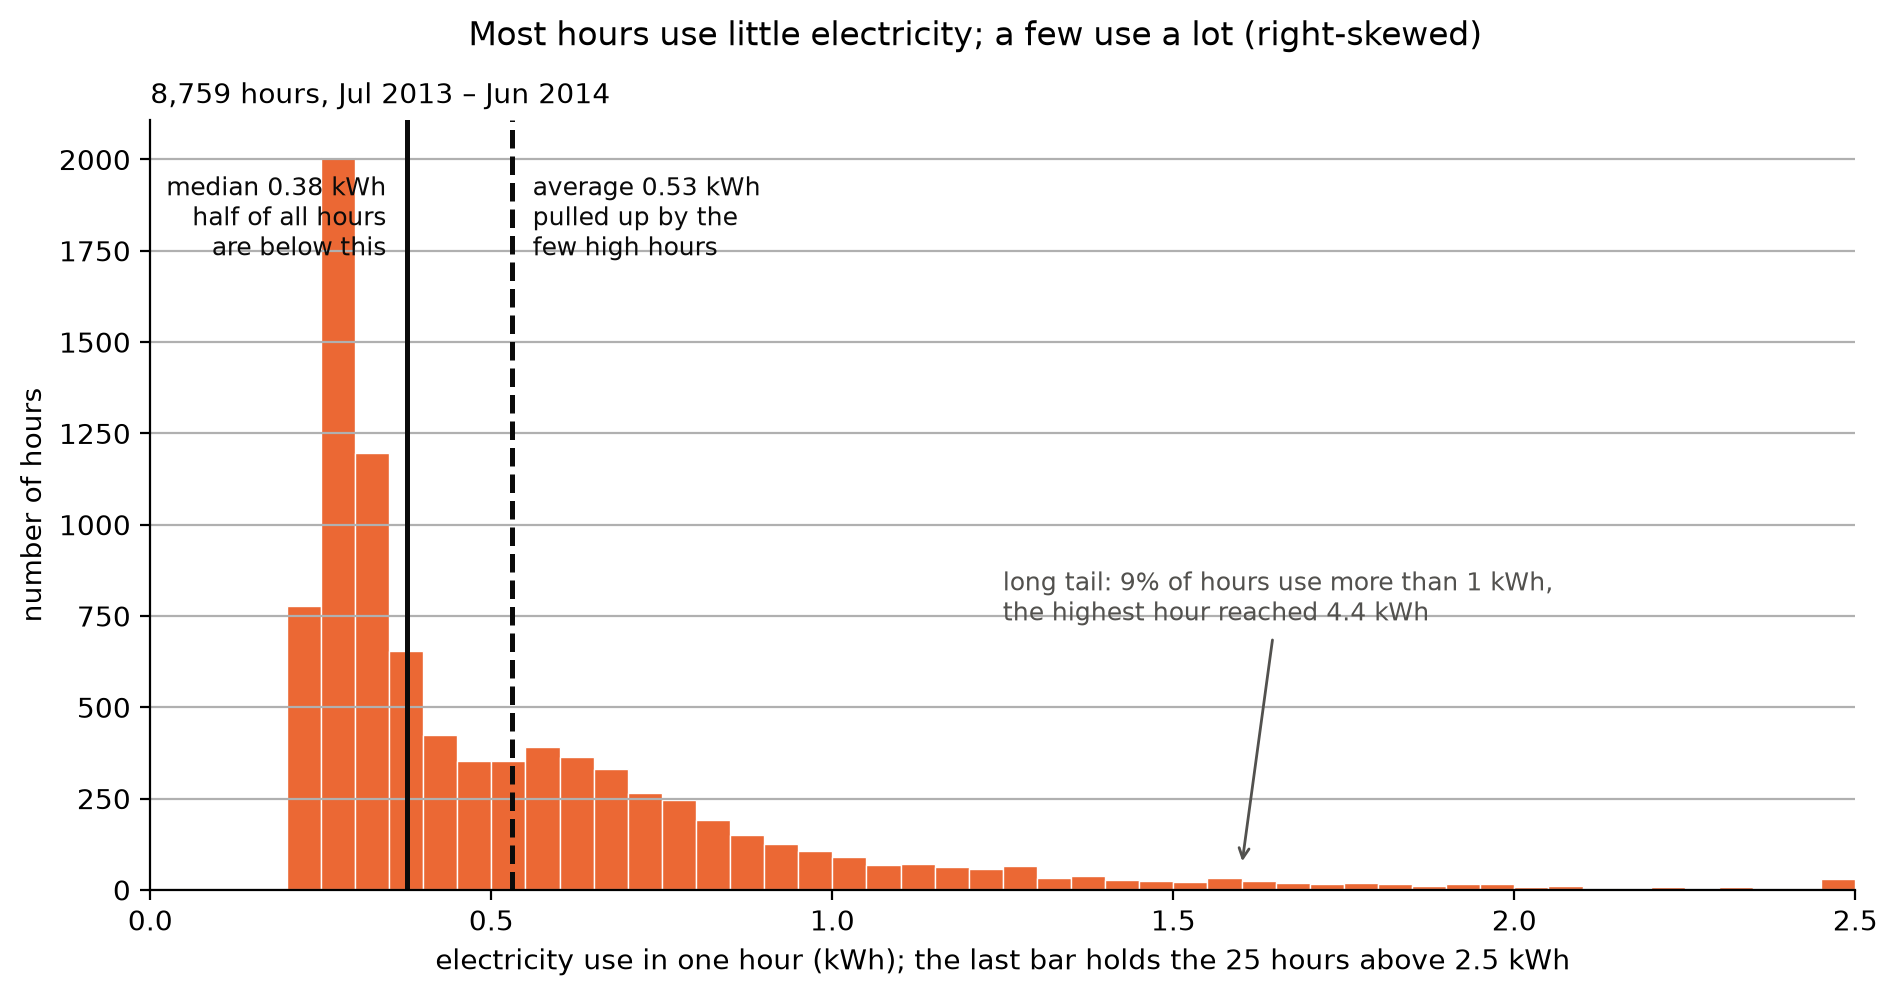

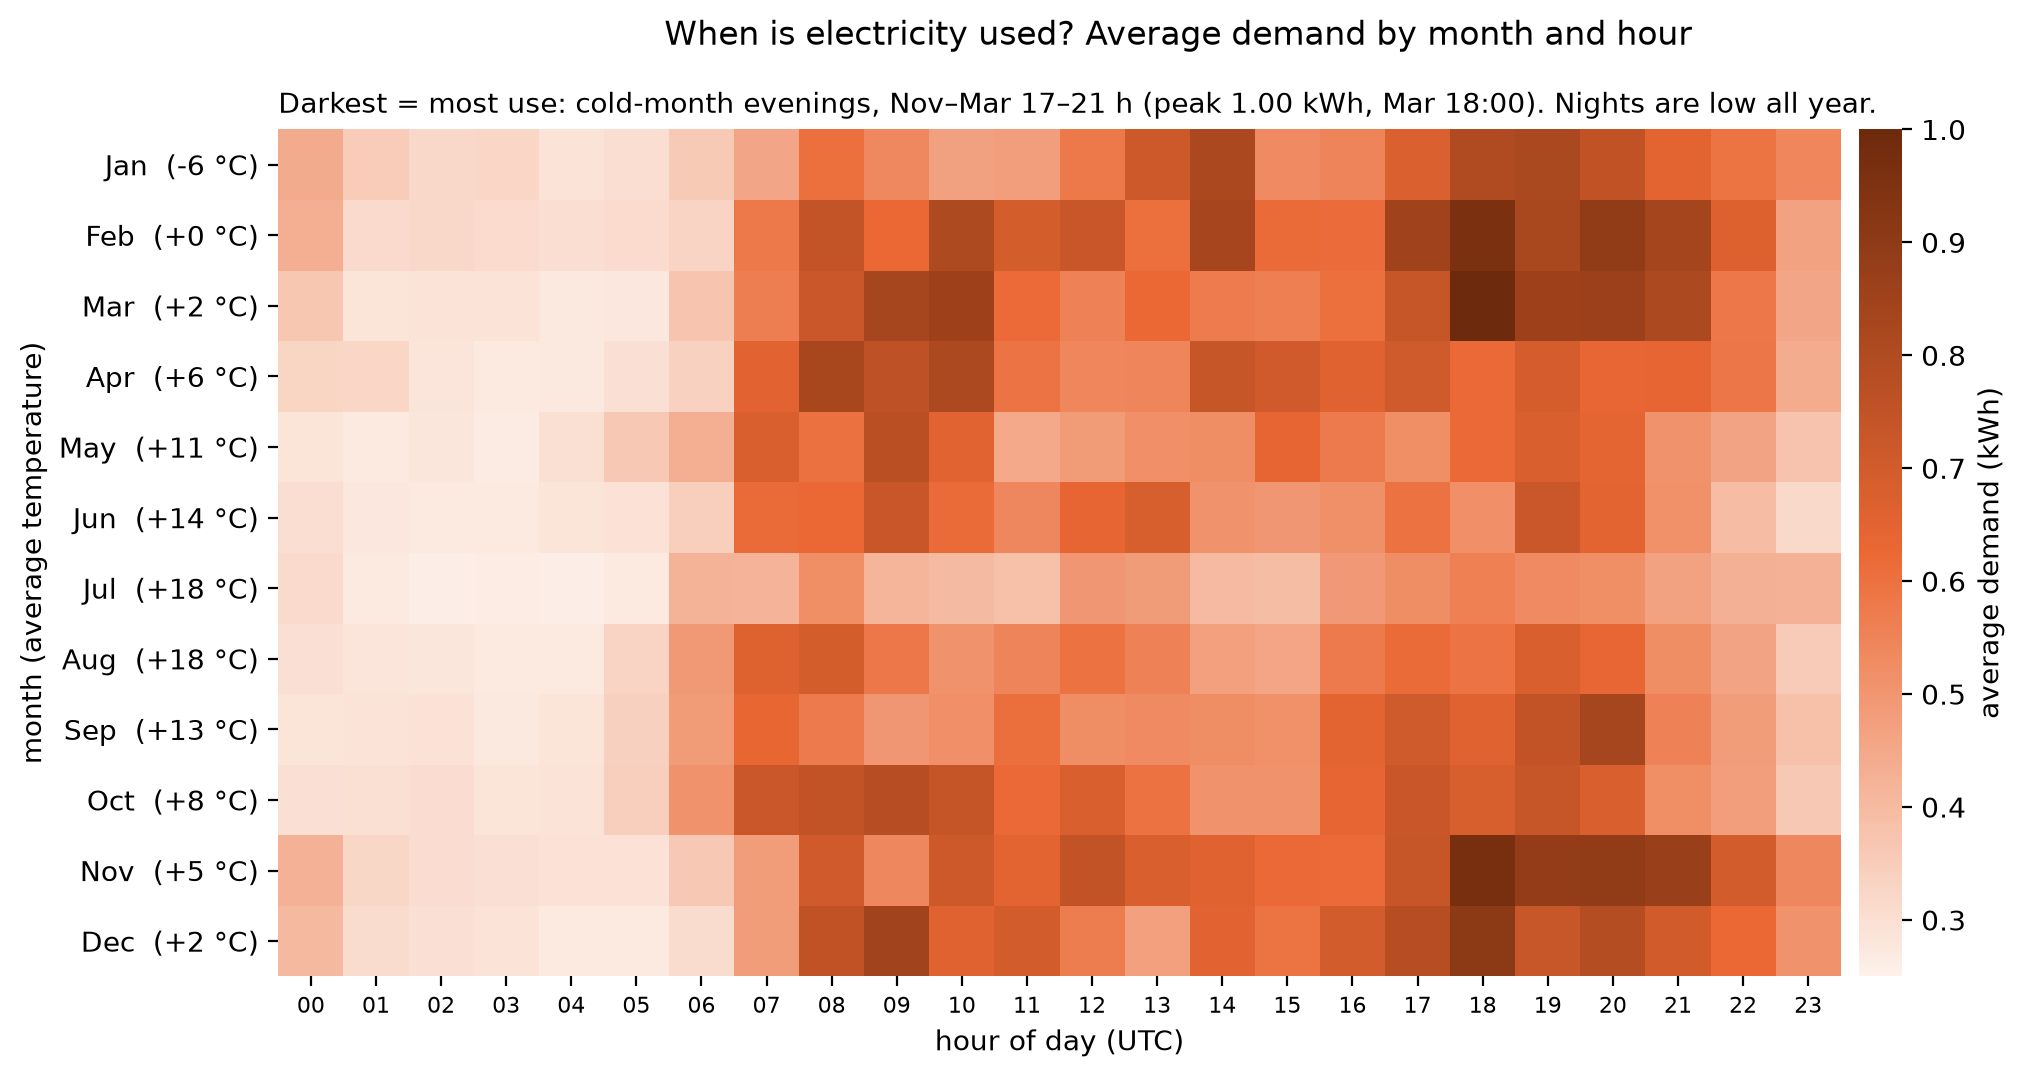

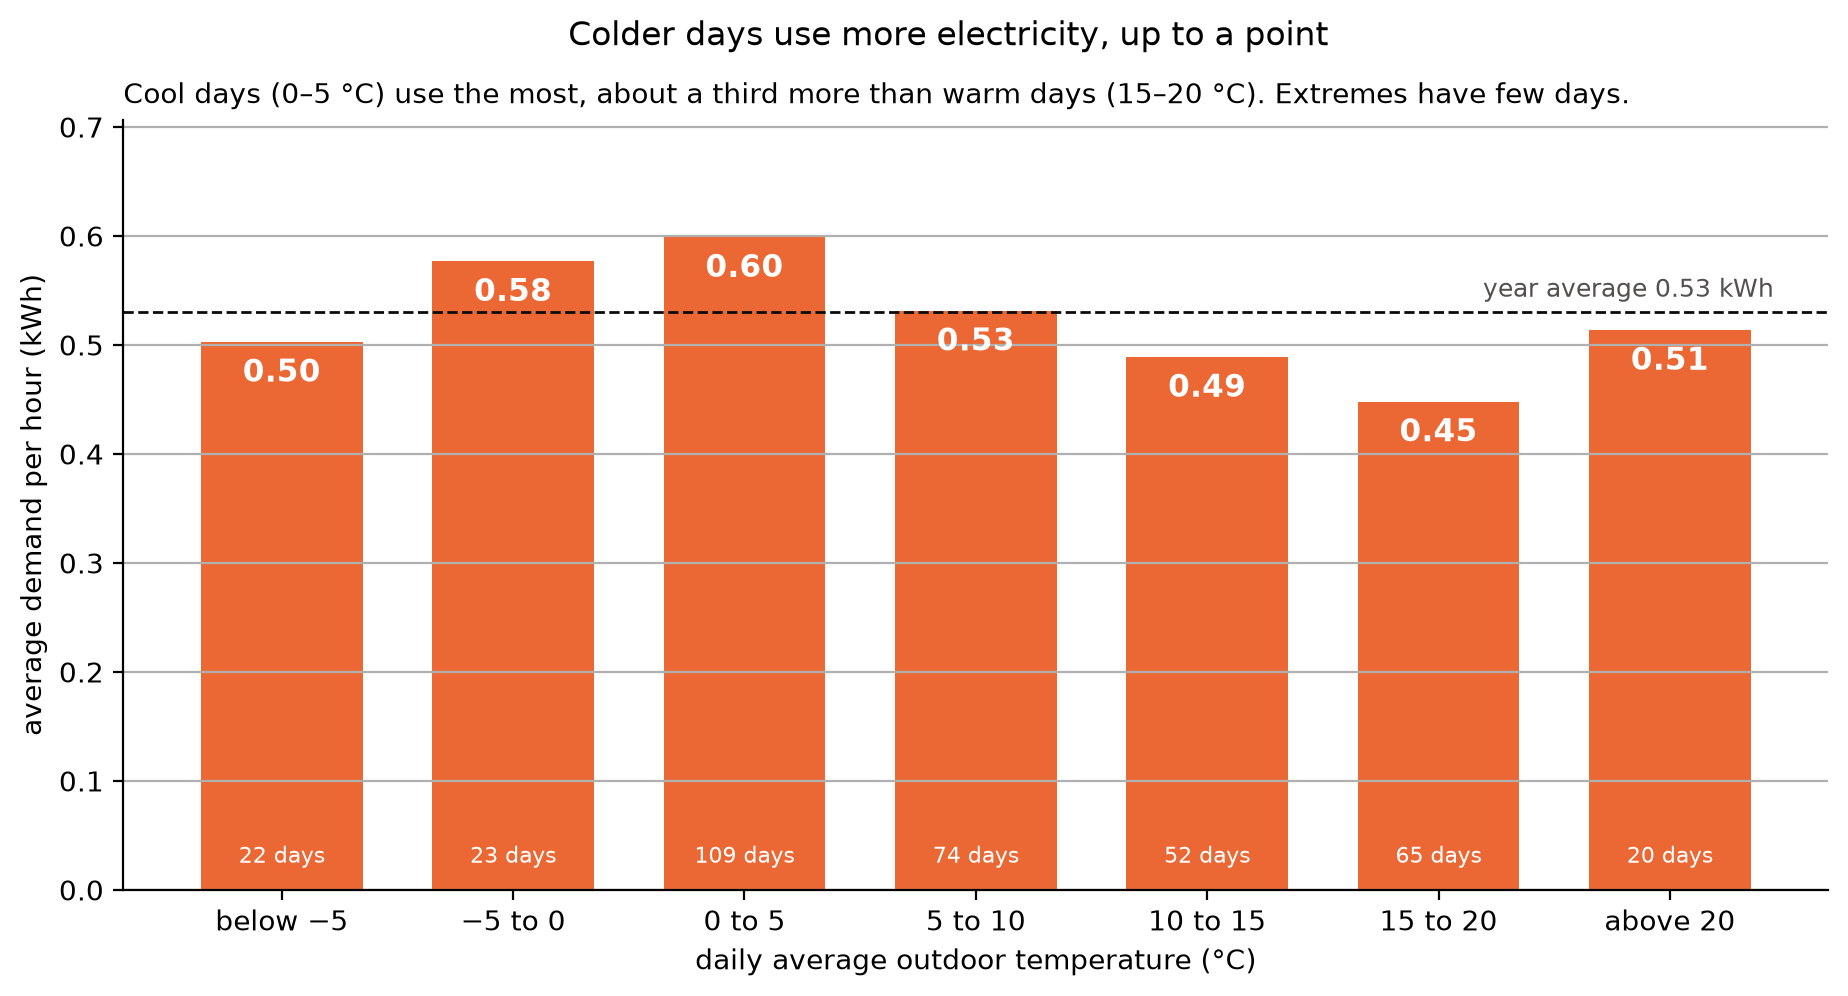

In [14]:
project.describe_demand_weather(df)
show(project.DEMAND_HISTOGRAM_FIGURE, project.DEMAND_HEATMAP_FIGURE, project.DEMAND_TEMPERATURE_BARS_FIGURE)

### Distributions and transformations
Shape (skewness, kurtosis) decides normality, because with ~8,760 values every formal test rejects. Partial
transformations are applied: log demand, √wind speed, √radiation plus a day/night flag.

Normality (n = hours; tests reject at p < 0.05):
                                    n    skew  excess_kurtosis  pct_zeros  dagostino_p  shapiro_p  close_to_normal
variable                                                                                                          
Demand (kWh)                     8759    2.49              8.9     0.0571            0   9.87e-67            False
Temperature (°C)                 8759  -0.209          -0.0232      0.365     2.57e-14   2.31e-22             True
Pressure (hPa)                   8759  -0.375            0.795          0     2.82e-69   8.91e-16             True
Cloud cover (%)                  8759  -0.778           -0.955       5.33            0   3.94e-62            False
Cloud cover low (%)              8759   0.273             -1.6       19.4            0   1.15e-58            False
Cloud cover mid (%)              8759   0.816           -0.911       34.6            0   8.03e-63            False
Cloud cover high (%)           

Saved figure to ./outputs/figures/distributions_vs_normal.png


Saved figure to ./outputs/figures/demand_transformation_qq.png
Saved figure to ./outputs/figures/weather_transformations.png


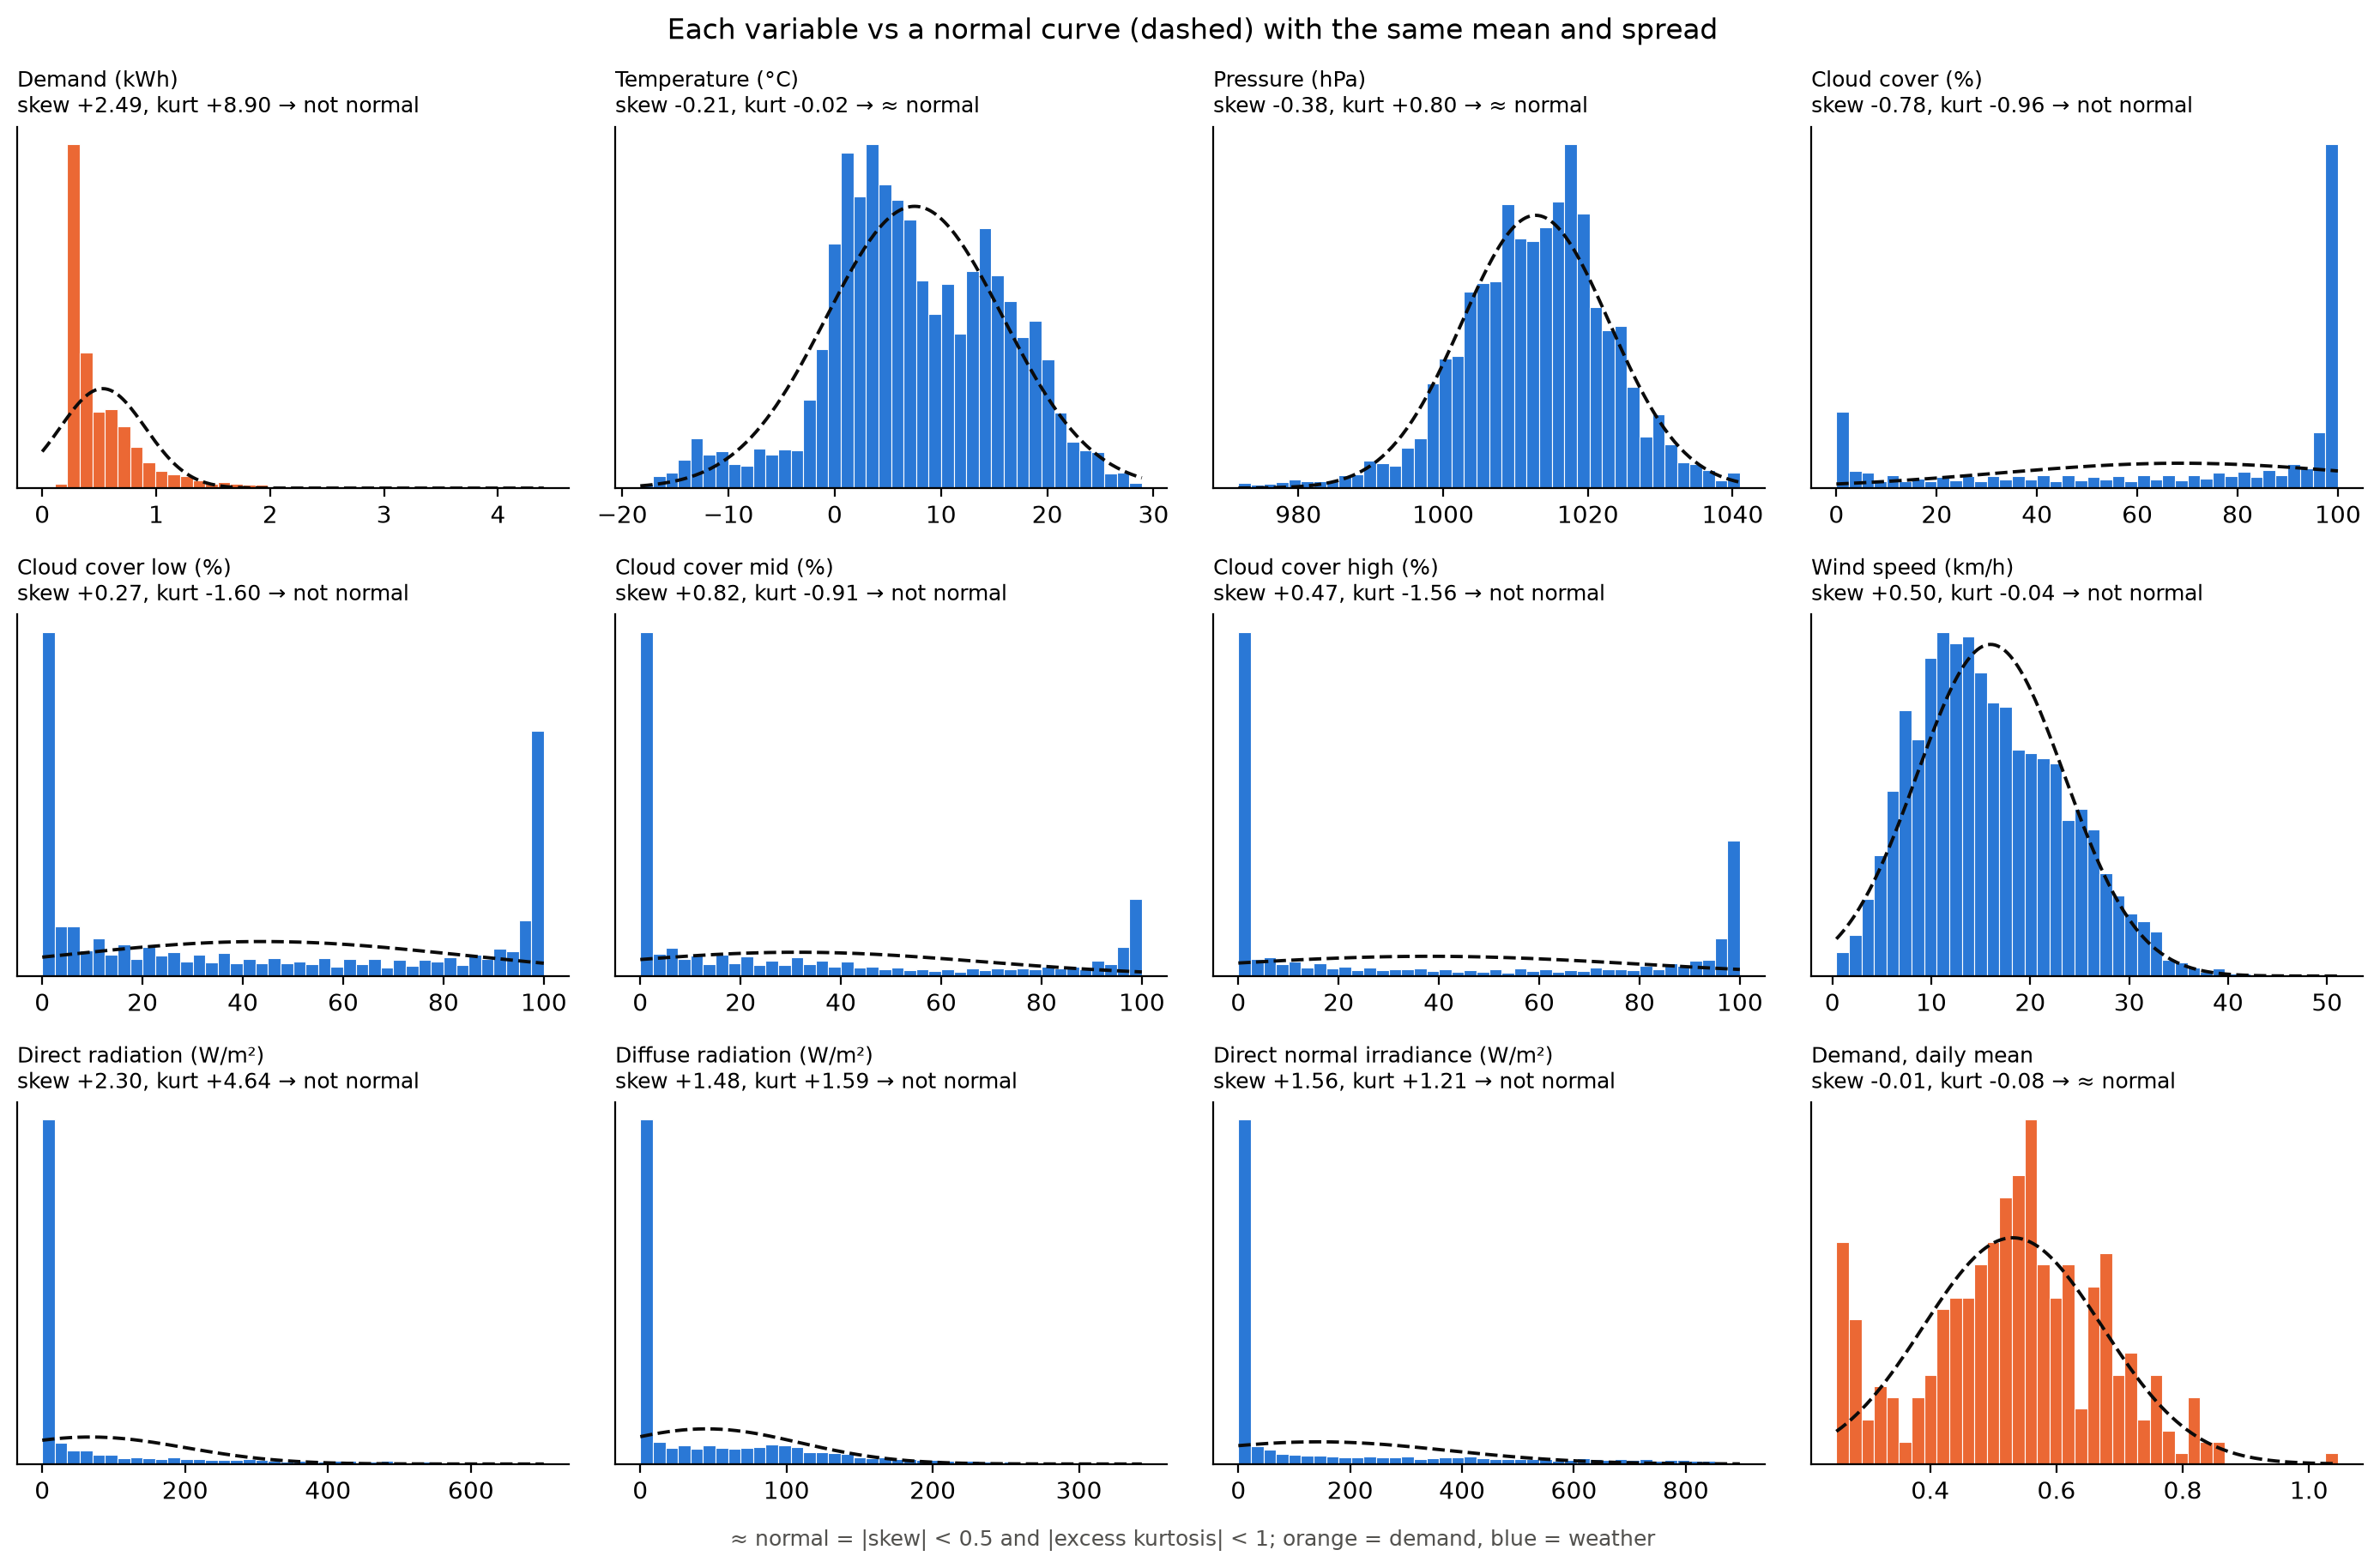

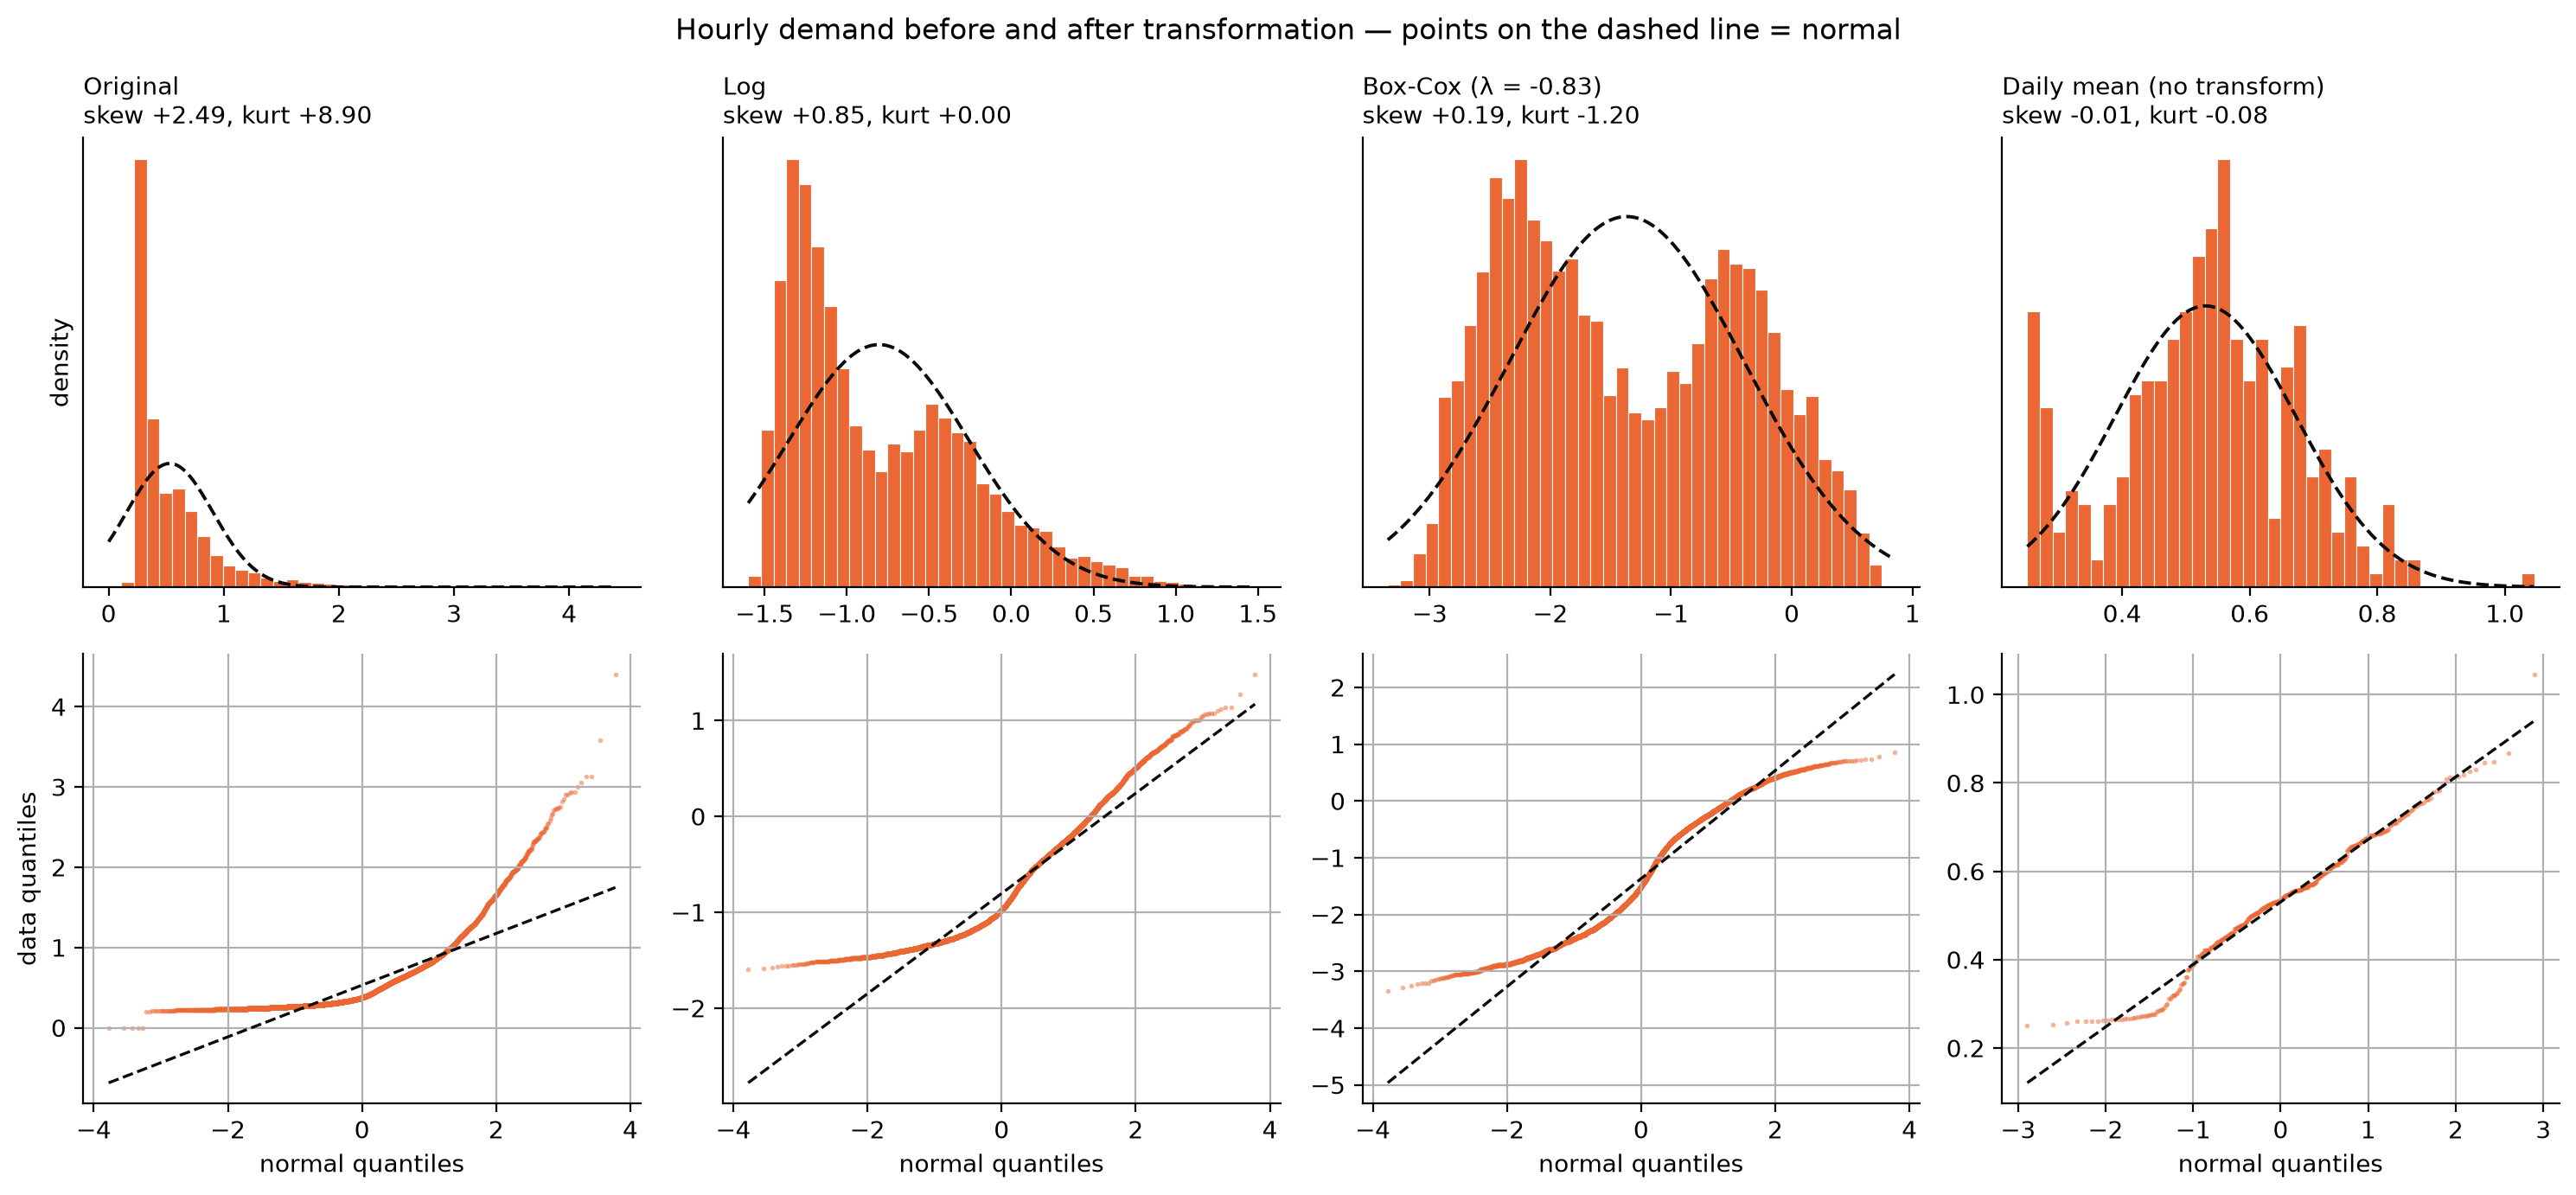

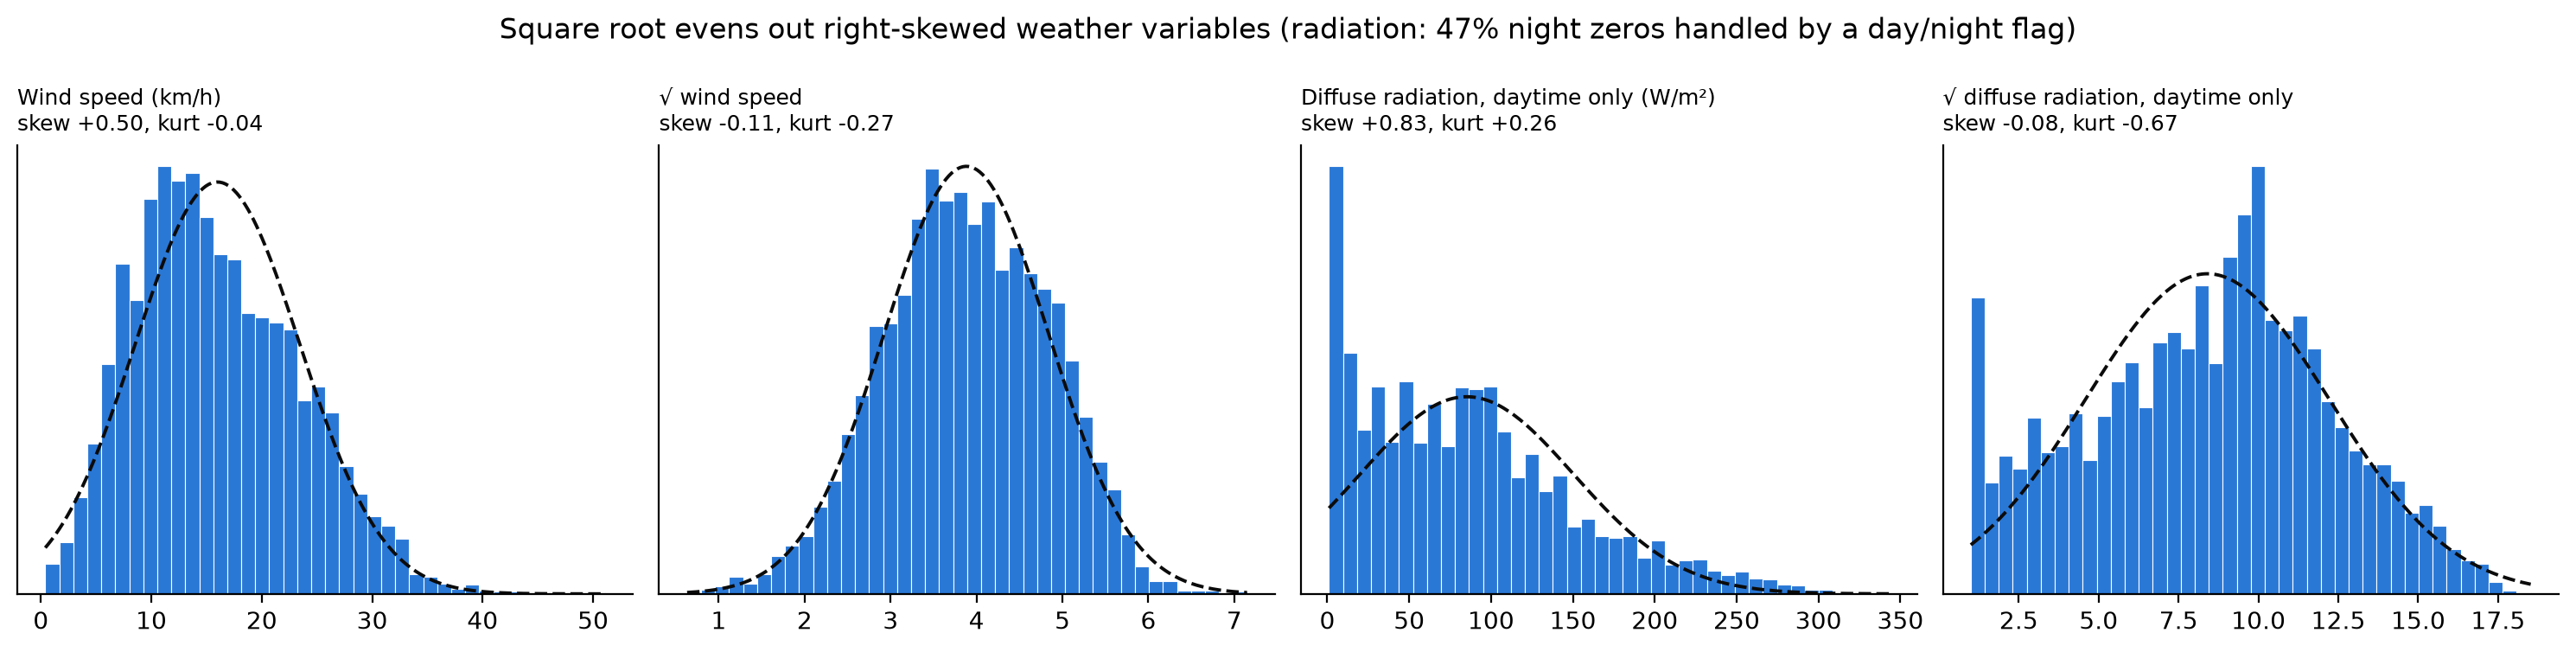

In [15]:
project.analyse_distributions(df)
show(project.NORMALITY_FIGURE, project.DEMAND_TRANSFORM_FIGURE, project.WEATHER_TRANSFORM_FIGURE)

# Part 4 — Features

The forecast is **day-ahead**: issued at 00:00 on day D with demand known up to 23:00 on day D-1. One lag feature
(`demand_lag_24h`, justified by the autocorrelation), one calendar feature (`hour`) and one weather feature
(heating degree-hours). Each feature's availability at prediction time is checked; the same-day heating feature has
0 h lead time and is replaced by its 24 h-lagged version.

Spearman autocorrelation of demand at selected lags (hours):
1     0.712
2     0.523
23    0.481
24    0.517
25    0.474
48    0.463
72    0.408
168   0.327
336   0.364
Strongest lag usable day-ahead (>= 24 h): 24 h, rho = 0.517

When each feature becomes known (prediction time = 00:00 on day D):
                                                                                 known_at  lead_time_h  available
feature                                                                                                          
demand_lag_24h                                  t − 23 h (end of the same hour yesterday)       23.000       True
hour                                                  always (calendar, fixed in advance)          inf       True
heating_degree_hours          t + 1 h (needs the measured temperature of the target hour)        0.000      False
heating_degree_hours_lag_24h                                                     t − 23 h       23.000       True
Removed from the m

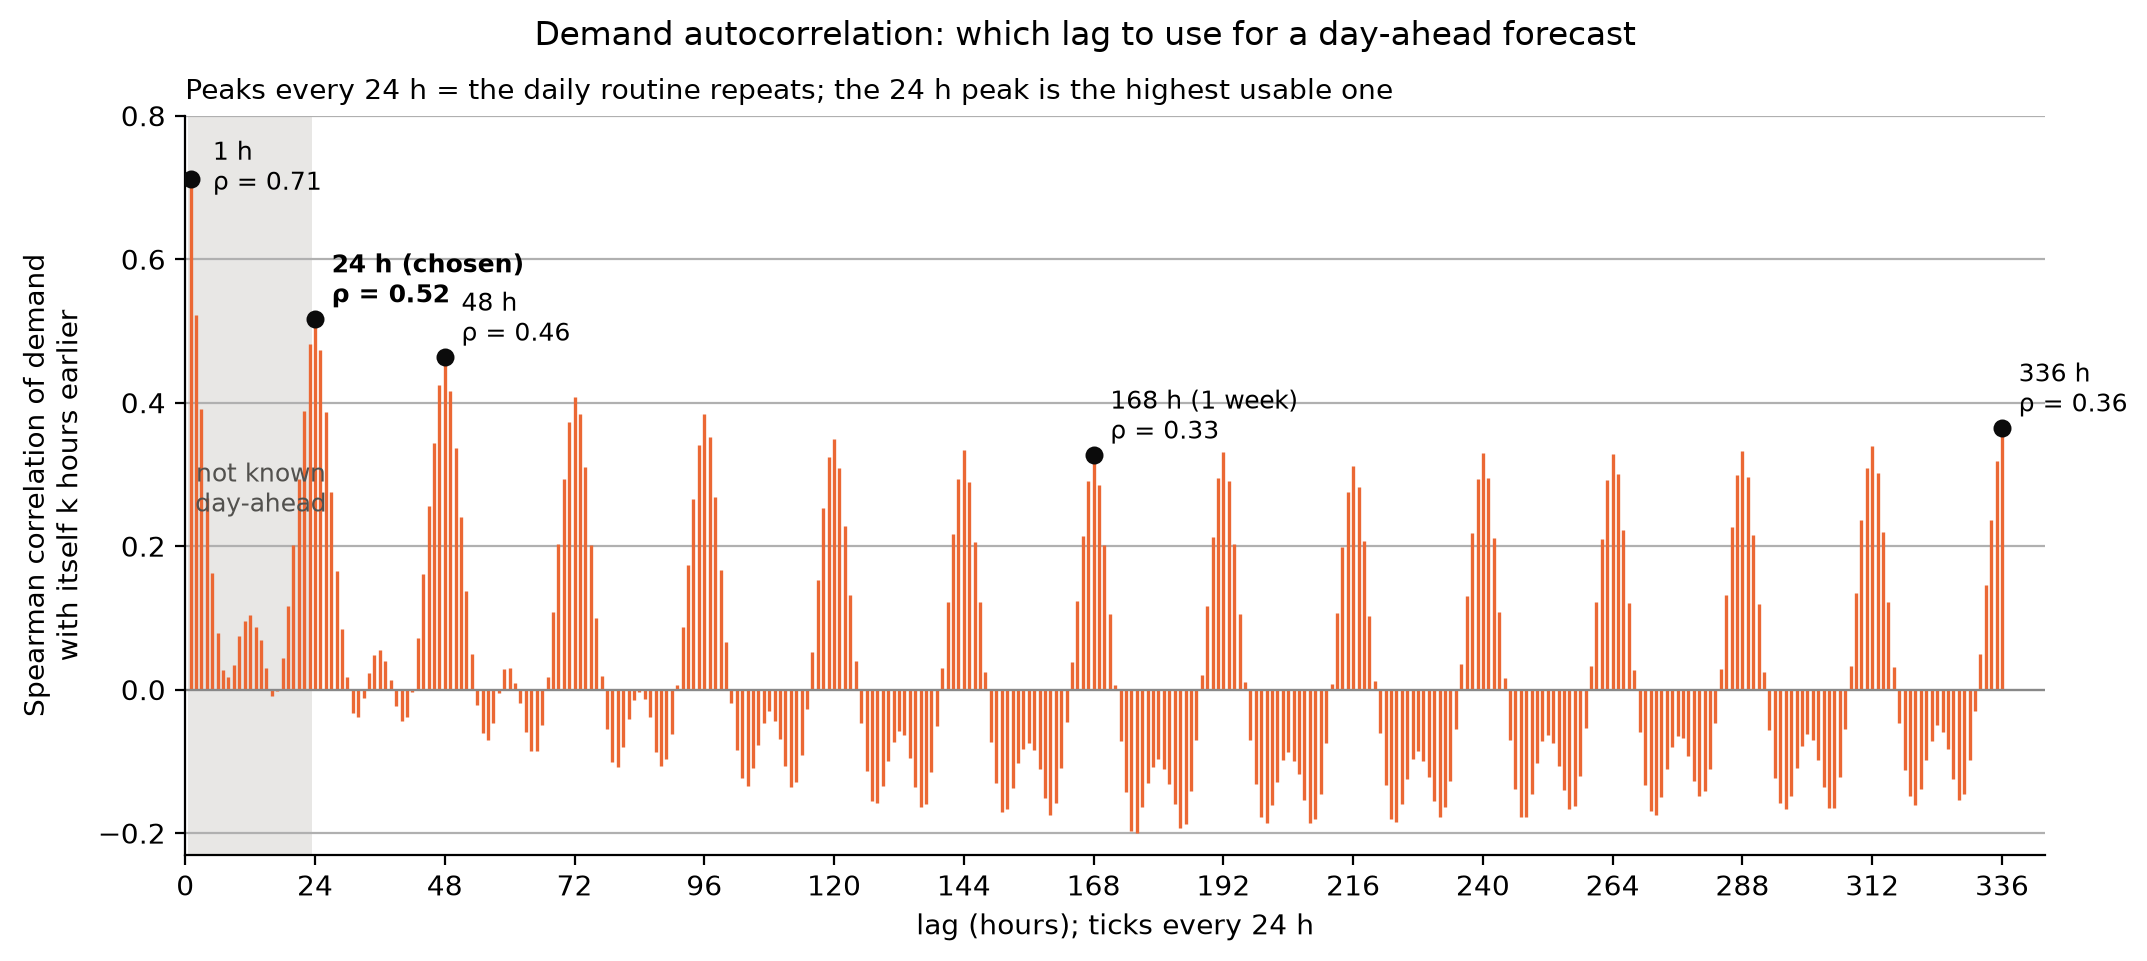

In [16]:
features = project.engineer_features(df)
show(project.ACF_FIGURE)

Feature ranking (higher = more relevant; final rank = mean of three ranks):
                              spearman_abs_rho  mutual_information  permutation_mae_increase  mean_rank  final_rank
hour                                    0.4065              0.2447                    0.0457     1.3333           1
demand_lag_24h                          0.5160              0.1875                    0.0069     1.6667           2
heating_degree_hours_lag_24h            0.1171              0.0513                    0.0019     3.0000           3
Saved ./outputs/tables/266083_feature_ranking.csv
Saved figure to ./outputs/figures/feature_ranking.png


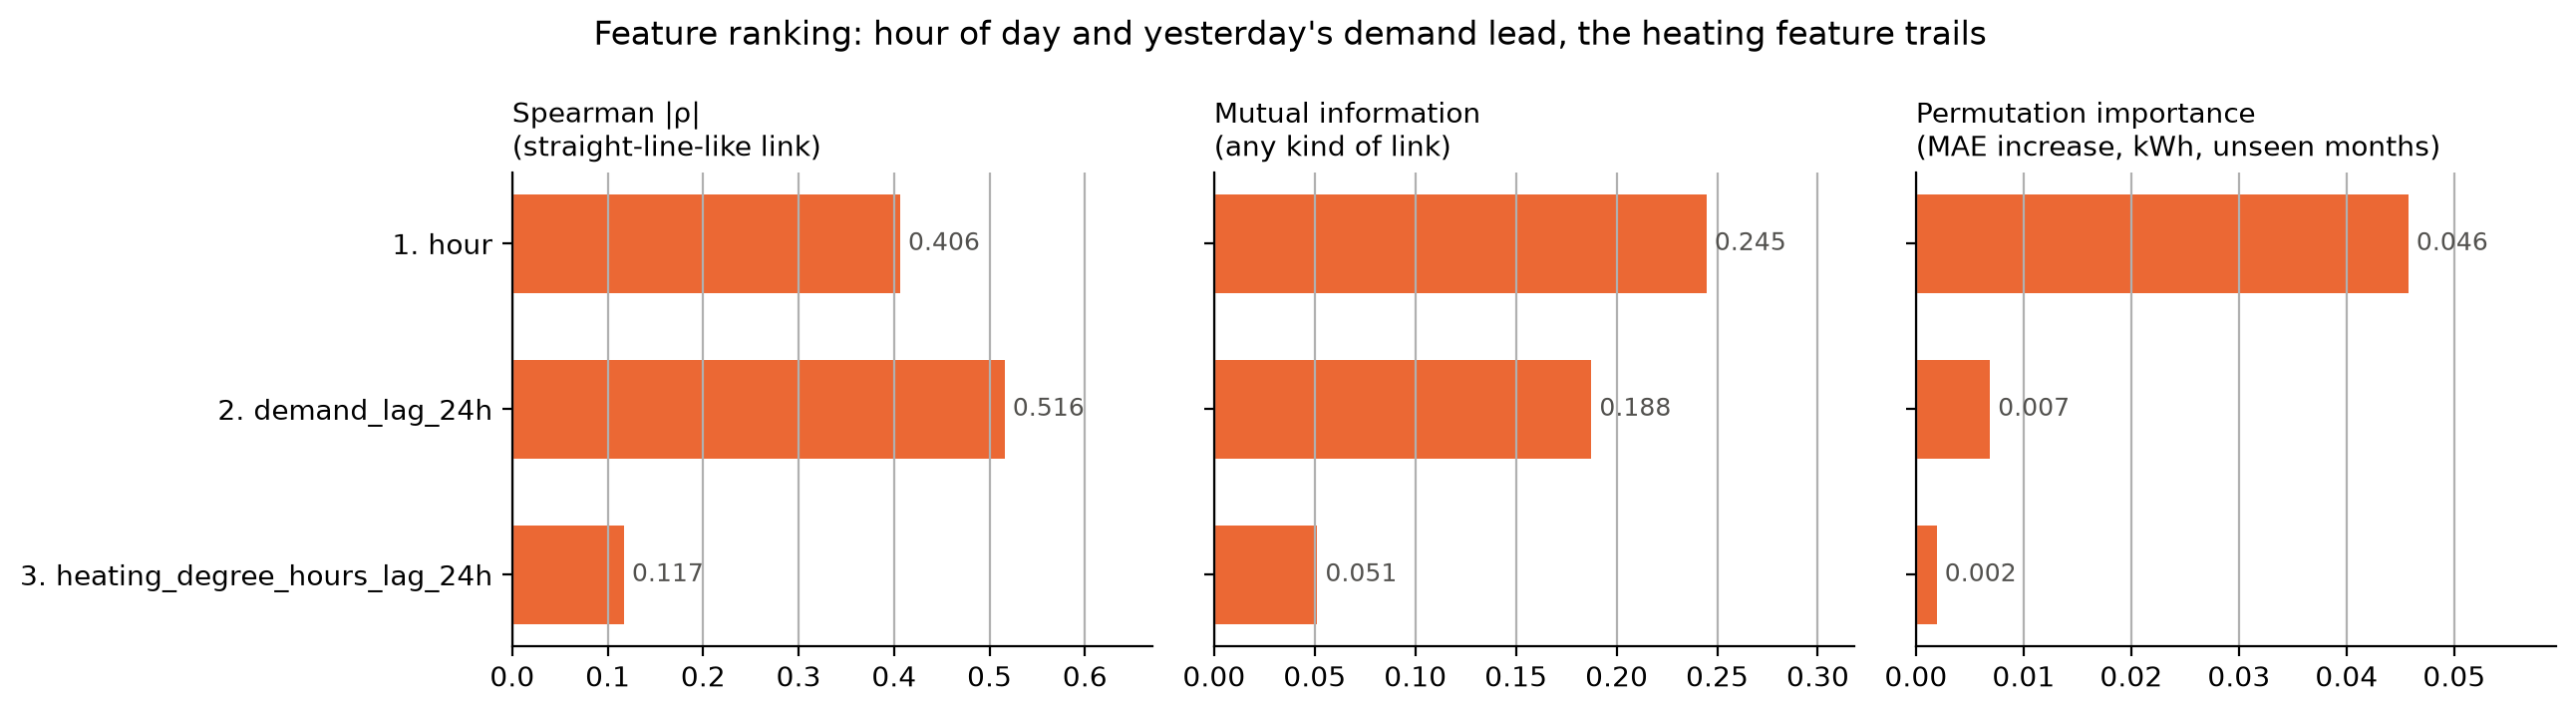

In [17]:
project.rank_modelling_features(features)
show(project.FEATURE_RANKING_FIGURE)

# Part 5 — Evaluation protocol and baselines

**Split by time, never at random**: train 1 Jul 2013 – 31 Mar 2014, validation 1 Apr – 31 May 2014, test June 2014,
scored in 7-day blocks. A **walk-forward** check covers the last week of the training file in daily folds.

**Metrics:** MAE (kWh) and nRMSE = RMSE / **mean demand of the training split (0.5374 kWh)**, the same fixed
normaliser everywhere. Before scoring, the nRMSE of the seasonal naive baseline is **predicted** from training data only;
then four baselines are scored (naive, seasonal naive 24 h and 168 h, moving average 24 h).

Train / validation / test split (time order, whole months):
                  first_hour         last_hour  hours  share_pct  days  full_week_blocks  outage_hours  absent_days  mean_temperature  mean_demand
set                                                                                                                                               
train       2013-07-01 00:00  2014-03-31 23:00   6575      75.07   273                 0             5           26              6.65         0.54
validation  2014-04-01 00:00  2014-05-31 23:00   1464      16.71    61                 8             0            8              8.45         0.52
test        2014-06-01 00:00  2014-06-30 23:00    720       8.22    30                 4             0            2             13.51         0.49
Hours not in any set: 0
Saved ./outputs/tables/266083_split_summary.csv
Saved ./data/processed/266083_split_labels.csv


Saved figure to ./outputs/figures/train_validation_test_split.png


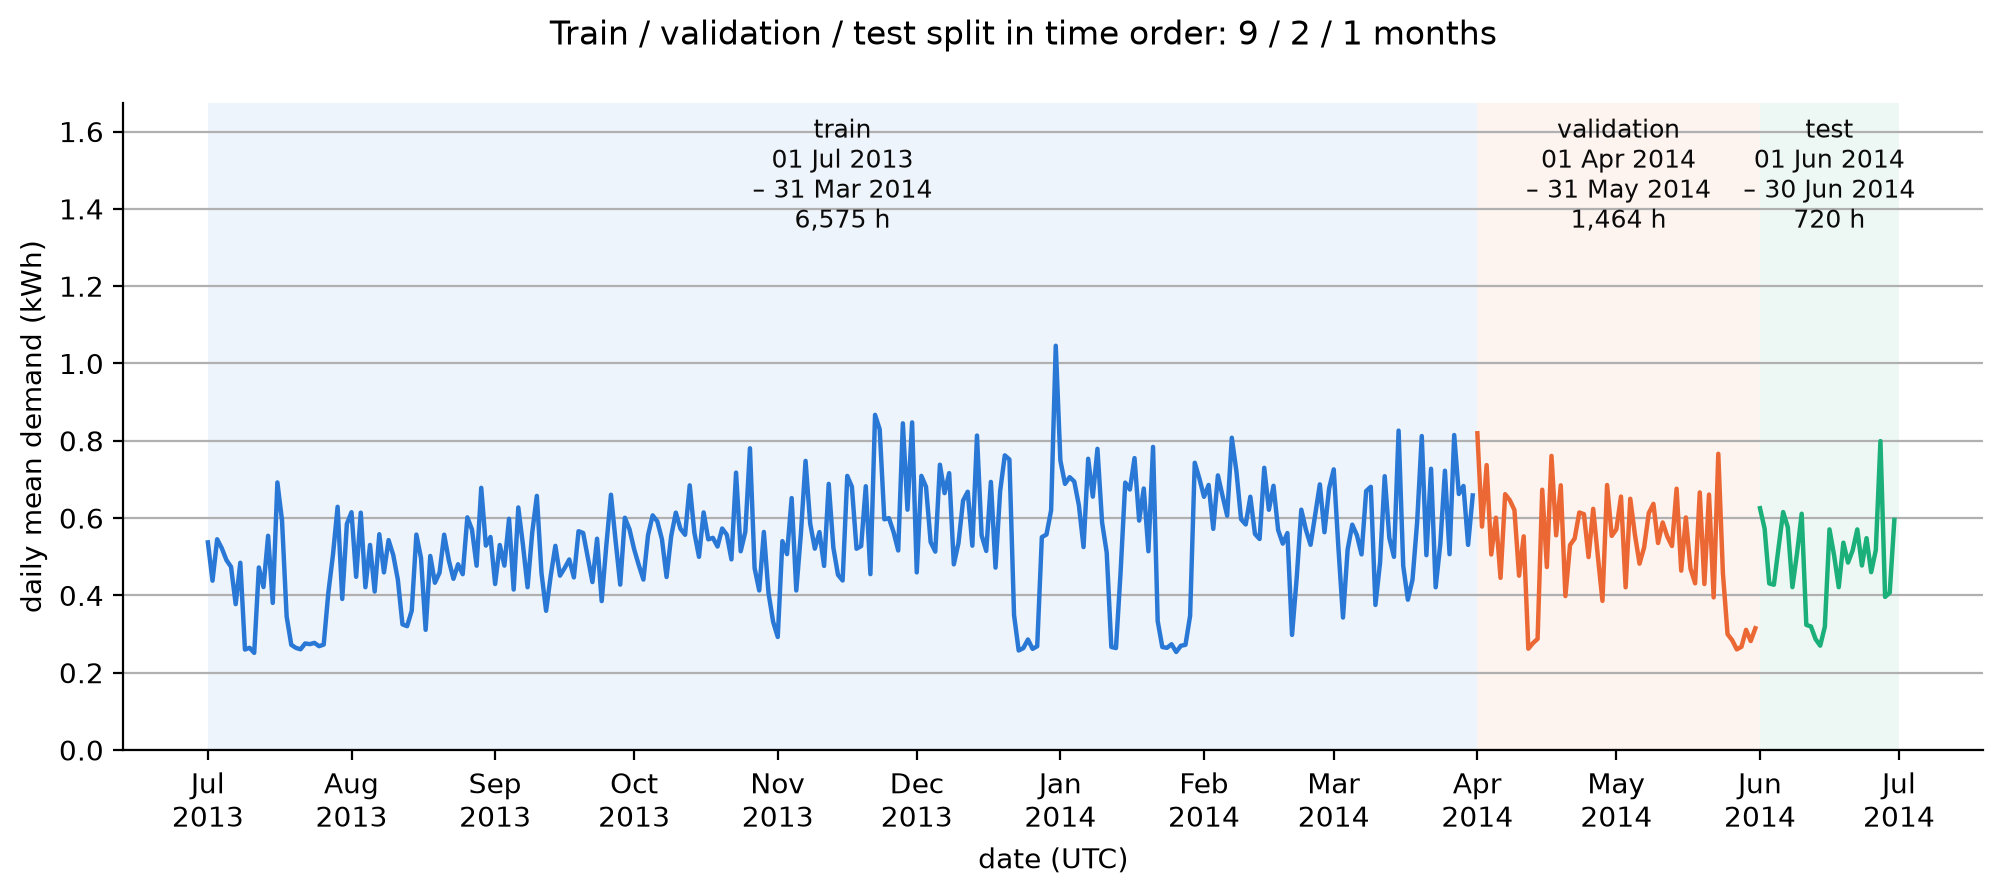

In [18]:
project.define_split(df)
show(project.SPLIT_FIGURE)

Walk-forward validation, last week, one fold per day (expanding window):
                   train_start                 train_end  train_hours           forecast_issued                test_start                  test_end  test_hours
fold                                                                                                                                                           
1    2013-07-01 00:00:00+00:00 2014-06-23 23:00:00+00:00         8591 2014-06-24 00:00:00+00:00 2014-06-24 00:00:00+00:00 2014-06-24 23:00:00+00:00          24
2    2013-07-01 00:00:00+00:00 2014-06-24 23:00:00+00:00         8615 2014-06-25 00:00:00+00:00 2014-06-25 00:00:00+00:00 2014-06-25 23:00:00+00:00          24
3    2013-07-01 00:00:00+00:00 2014-06-25 23:00:00+00:00         8639 2014-06-26 00:00:00+00:00 2014-06-26 00:00:00+00:00 2014-06-26 23:00:00+00:00          24
4    2013-07-01 00:00:00+00:00 2014-06-26 23:00:00+00:00         8663 2014-06-27 00:00:00+00:00 2014-06-27 00:00:00+00:00 2014-

Saved figure to ./outputs/figures/walk_forward_daily_folds.png


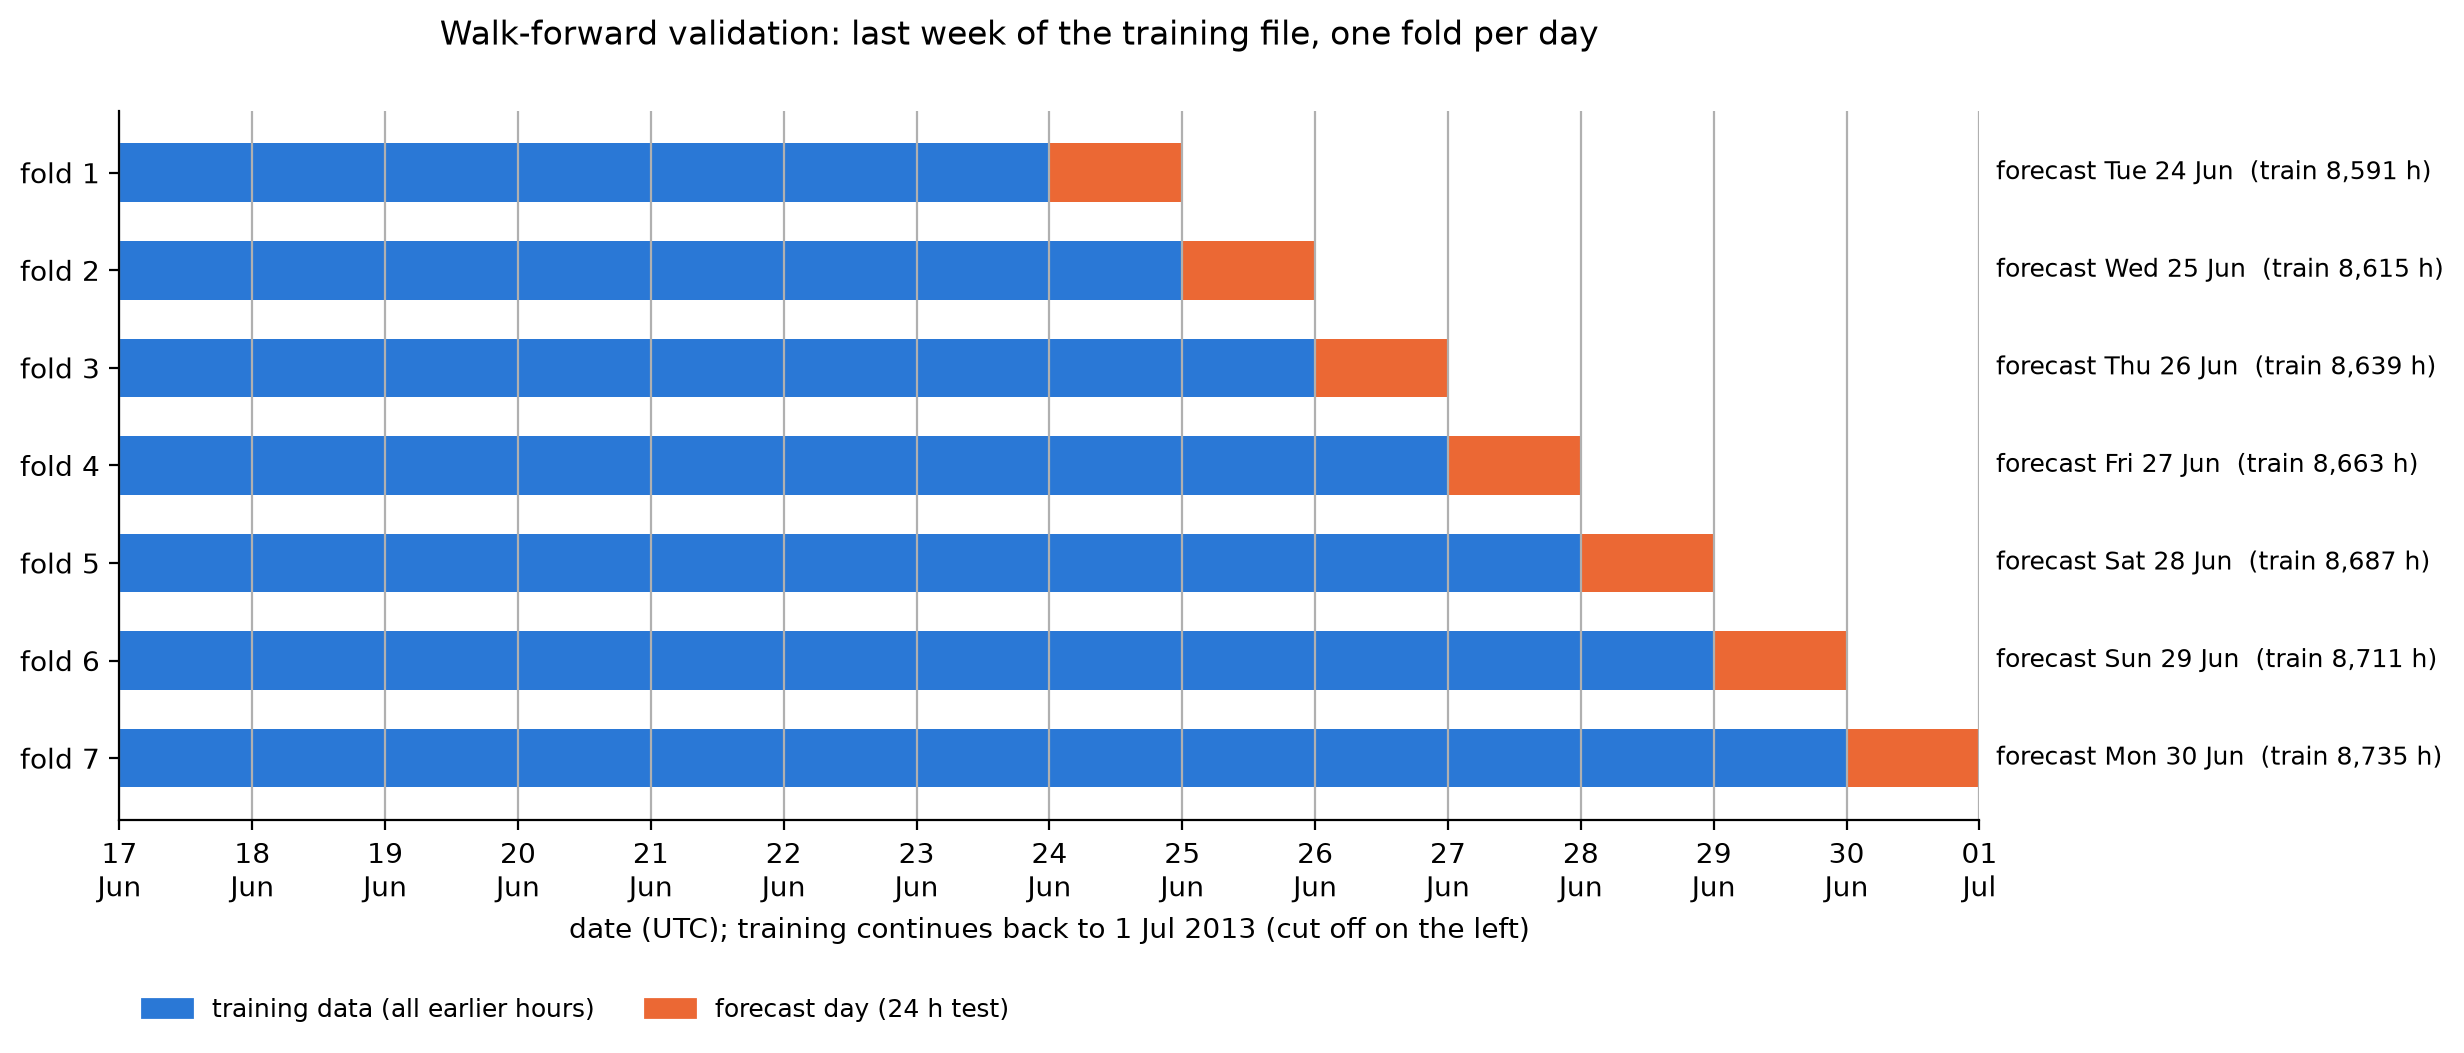

In [19]:
project.define_walk_forward(df)
show(project.WALK_FORWARD_FIGURE)

In [20]:
prediction = project.predict_baseline_nrmse(df)

Predicted nRMSE of the seasonal naive 24 h baseline (training set only):
  mean = 0.5374 kWh, σ = 0.3791 kWh, σ/mean = 0.705
  Pearson ρ at lag 24 h = 0.259, √(2(1−ρ)) = 1.217
  predicted nRMSE = 0.705 × 1.217 = 0.859
Saved ./outputs/tables/266083_seasonal_naive_nrmse_prediction.csv


nRMSE denominator = training-set mean demand = 0.5374 kWh (same value for every score)


Baselines, overall per evaluation set:
                              MAE_kWh                                                 nRMSE                                     
unit                 validation (all) test (all) walk-forward (all 7 days) validation (all) test (all) walk-forward (all 7 days)
baseline                                                                                                                        
Naive (last hour)               0.301      0.220                     0.261            0.907      0.702                     0.829
Seasonal naive 24 h             0.277      0.220                     0.258            0.899      0.733                     0.847
Seasonal naive 168 h            0.293      0.247                     0.240            0.904      0.775                     0.824
Moving average 24 h             0.266      0.227                     0.275            0.721      0.629                     0.743

Walk-forward MAE (kWh) per day:
baseline                 

Saved figure to ./outputs/figures/baselines_walk_forward_week.png
Seasonal naive 24 h: predicted vs actual nRMSE (error = predicted − actual):
              predicted_nRMSE  actual_nRMSE  error  relative_error_pct
group                                                                 
validation              0.859         0.899 -0.040              -4.476
test                    0.859         0.733  0.126              17.122
walk-forward            0.859         0.847  0.012               1.374
Saved ./outputs/tables/266083_seasonal_naive_nrmse_prediction_vs_actual.csv


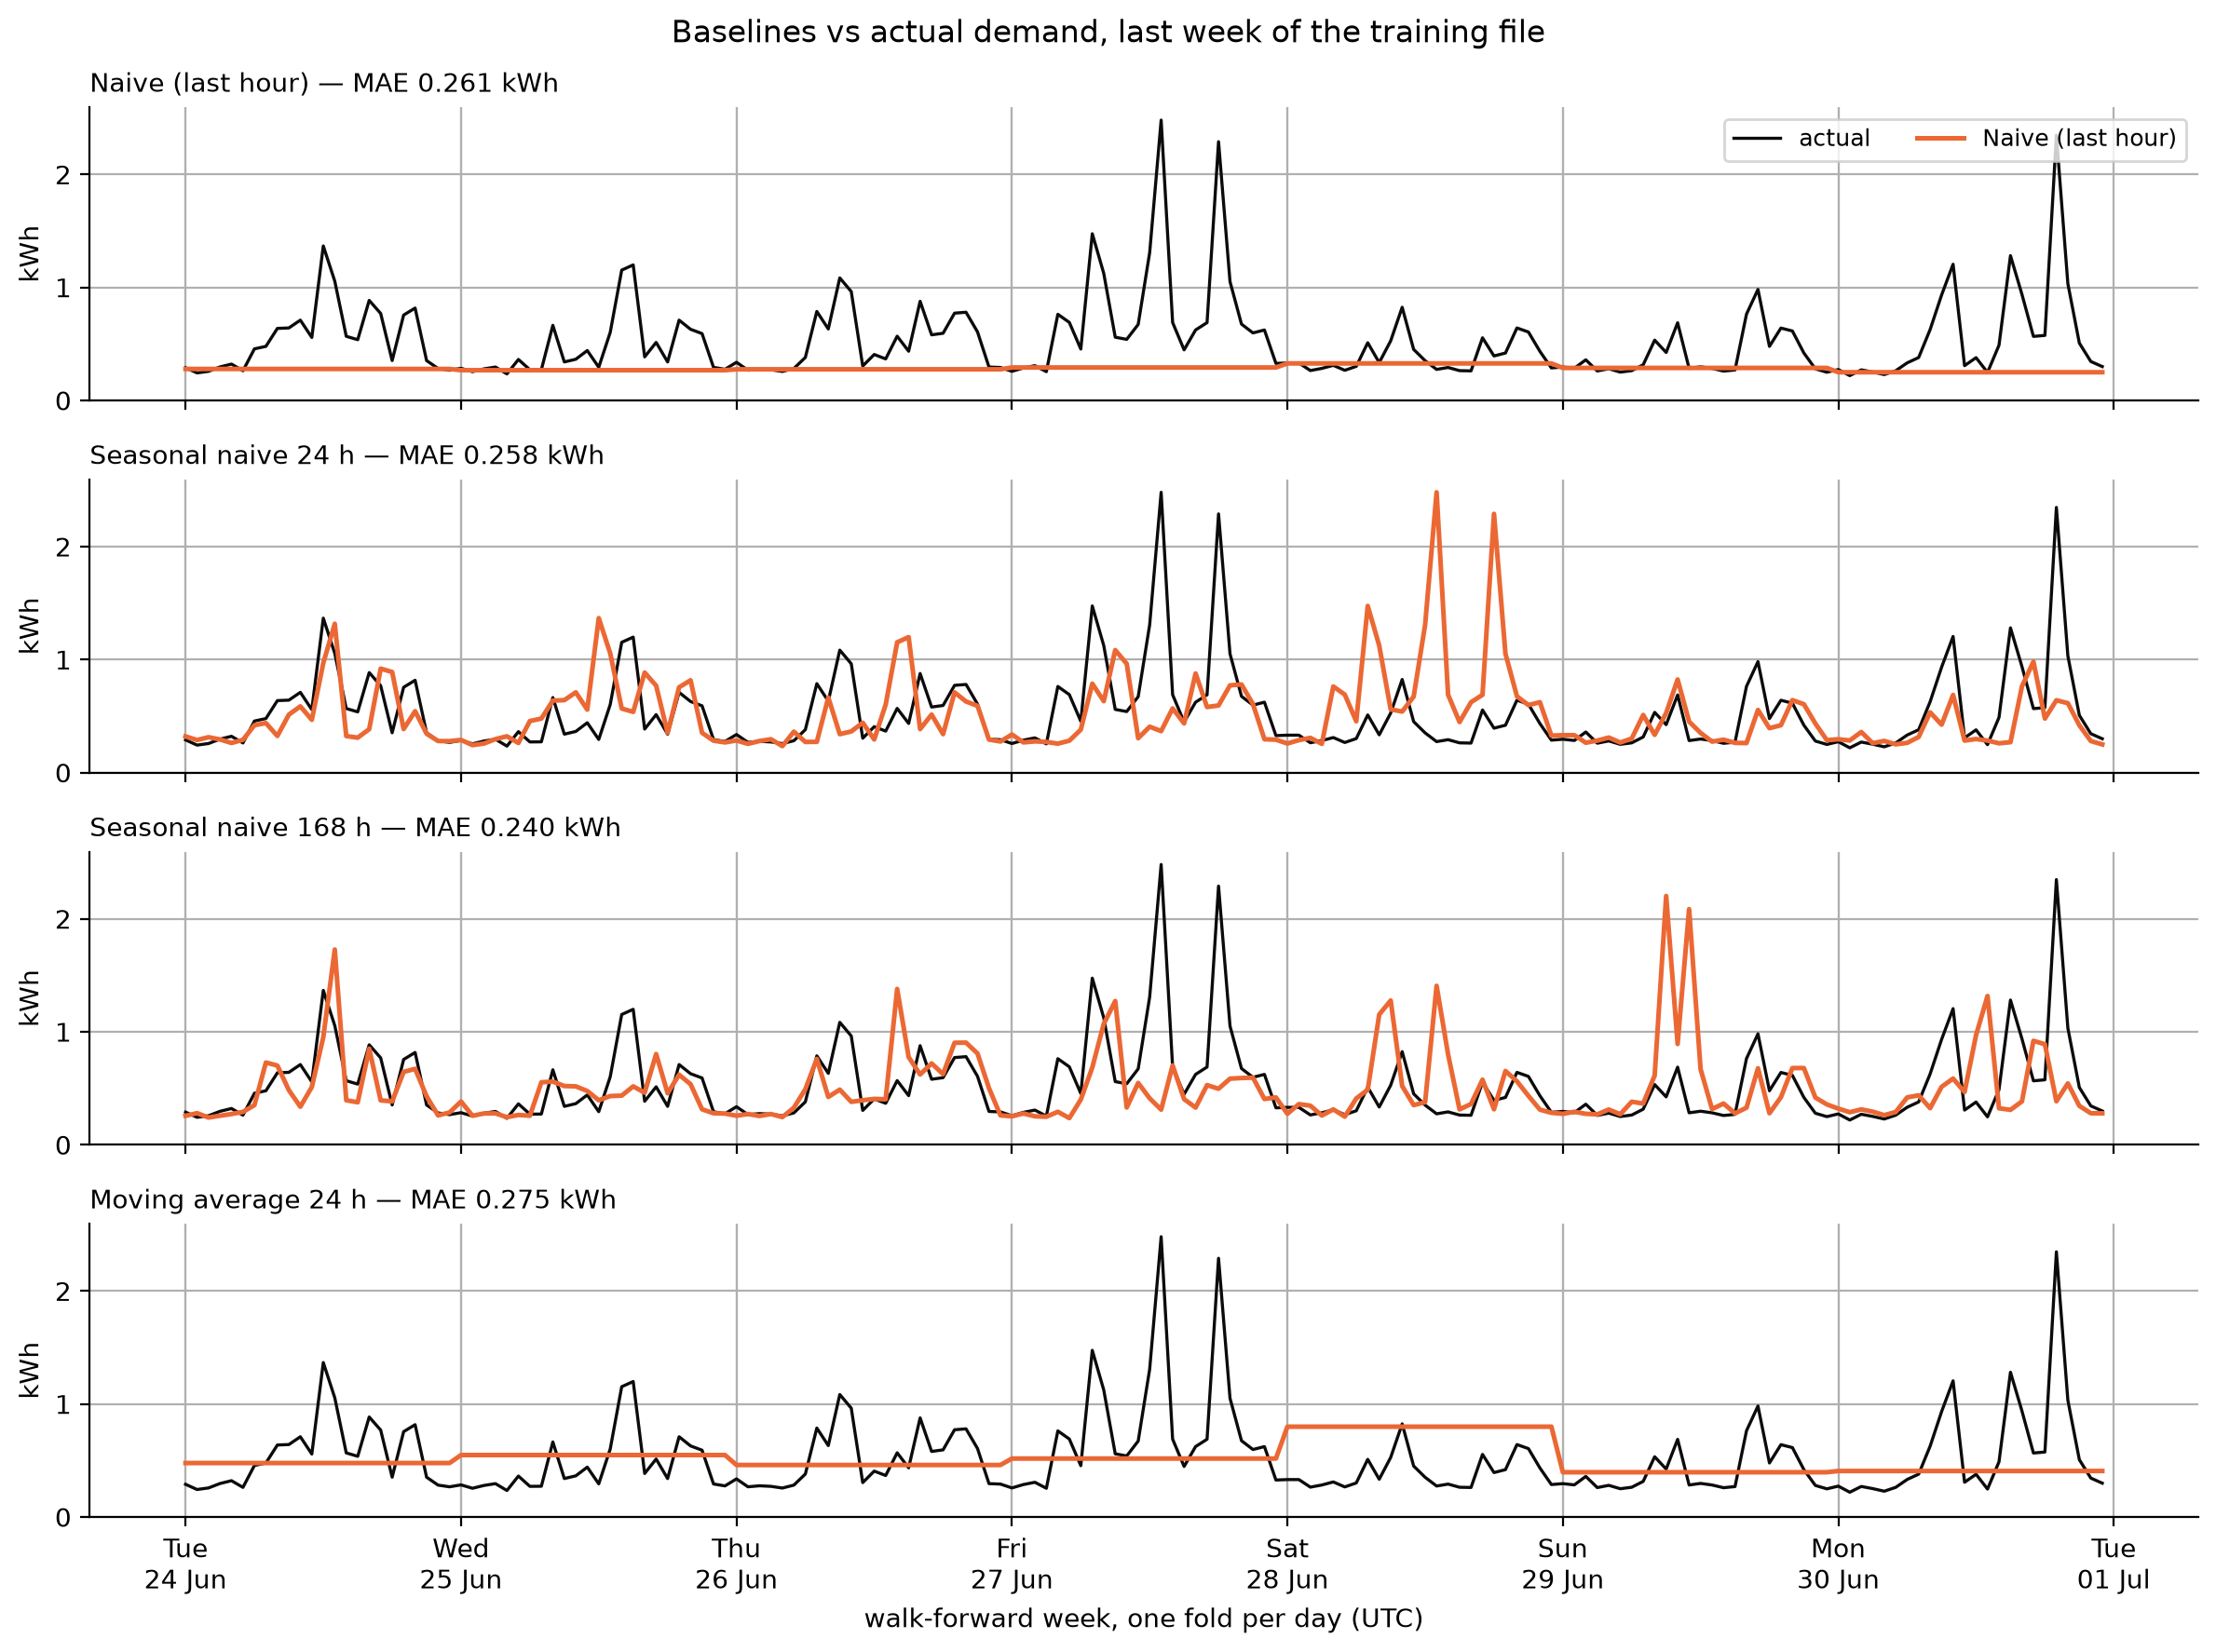

In [21]:
scores = project.baseline_scores(df)
project.compare_nrmse_prediction(prediction, scores)
show(project.BASELINES_FIGURE)

# Part 6 — ARMA-family models

ADF + KPSS on the training series lead to one first difference (d = 1, D = 0). The ACF of the differenced series cuts
off after lag 2 and the PACF tails off, which reads as **SARIMA(0,1,2)(1,0,0)24**; a second model comes from an AIC
search. Both are scored day-ahead under the protocol, compared in-sample vs walk-forward, and the strongest exogenous
feature, **hour of day**, is added to give a SARIMAX.

Training set only, 6,576 hours (outage and missing hour interpolated).
ADF: H0 unit root (p < 0.05 → stationary). KPSS: H0 stationary (p < 0.05 → not stationary). KPSS p-values are capped at 0.01–0.10.
                               ADF_stat  ADF_p  KPSS_stat  KPSS_p  both_agree_stationary  variance  acf_1  acf_24  acf_168
series                                                                                                                    
level (no differencing)          -9.833  0.000      2.737   0.010                  False     0.144  0.545   0.258    0.184
first difference (lag 1)        -33.352  0.000      0.027   0.100                   True     0.131 -0.221   0.033    0.031
seasonal difference (lag 24)    -22.491  0.000      0.004   0.100                   True     0.213  0.406  -0.488   -0.019
seasonal difference (lag 168)   -10.802  0.000      0.026   0.100                   True     0.233  0.456   0.068   -0.509
lag 24 + lag 1                  -24.486  0.000      0.021   

Saved figure to ./outputs/figures/stationarity_differencing.png


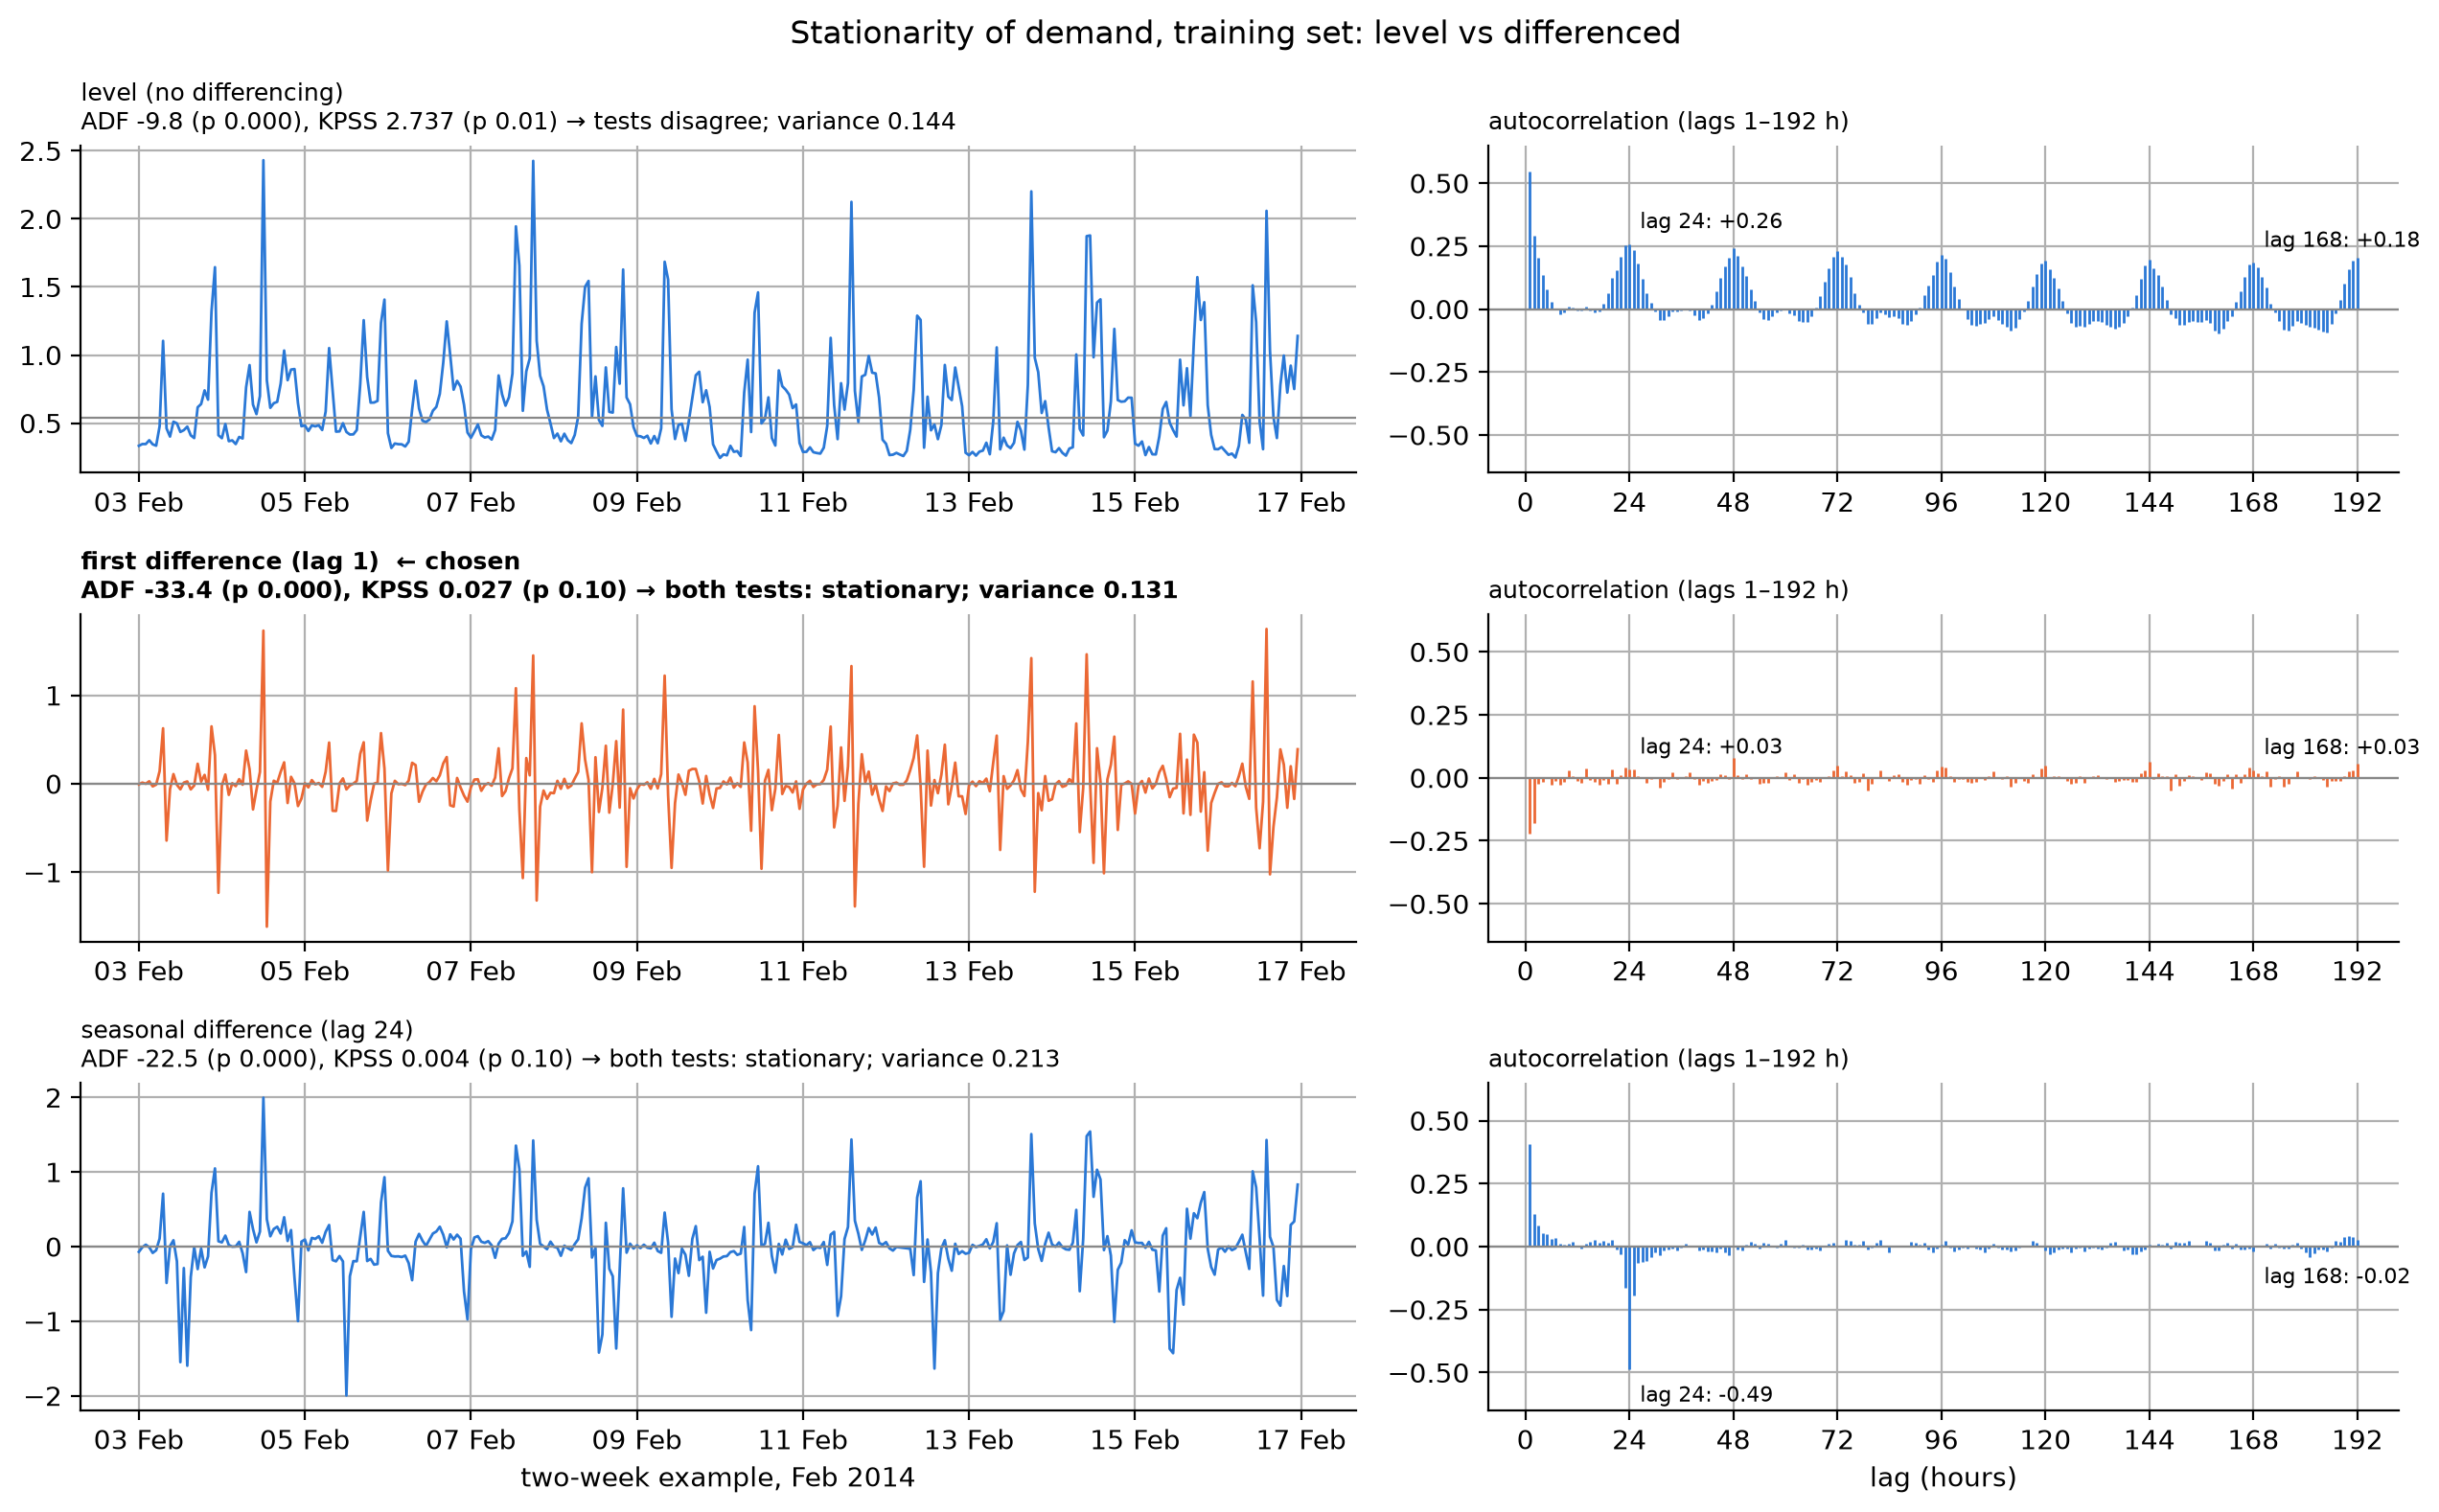

In [22]:
project.test_stationarity(df)
show(project.STATIONARITY_FIGURE)

First-differenced training demand, n = 6,575; 95 % bound ±1.96/√n = ±0.024
       acf   pacf
lag              
1   -0.221 -0.221
2   -0.180 -0.241
3   -0.024 -0.141
4   -0.015 -0.118
5   -0.002 -0.084
6   -0.026 -0.094
12  -0.011 -0.064
23  +0.040 -0.085
24  +0.033 -0.056
25  +0.032 -0.019
48  +0.078 -0.015
72  +0.048 -0.019
168 +0.031 -0.014
Saved ./outputs/tables/266083_acf_pacf_differenced.csv


Saved figure to ./outputs/figures/acf_pacf_differenced.png


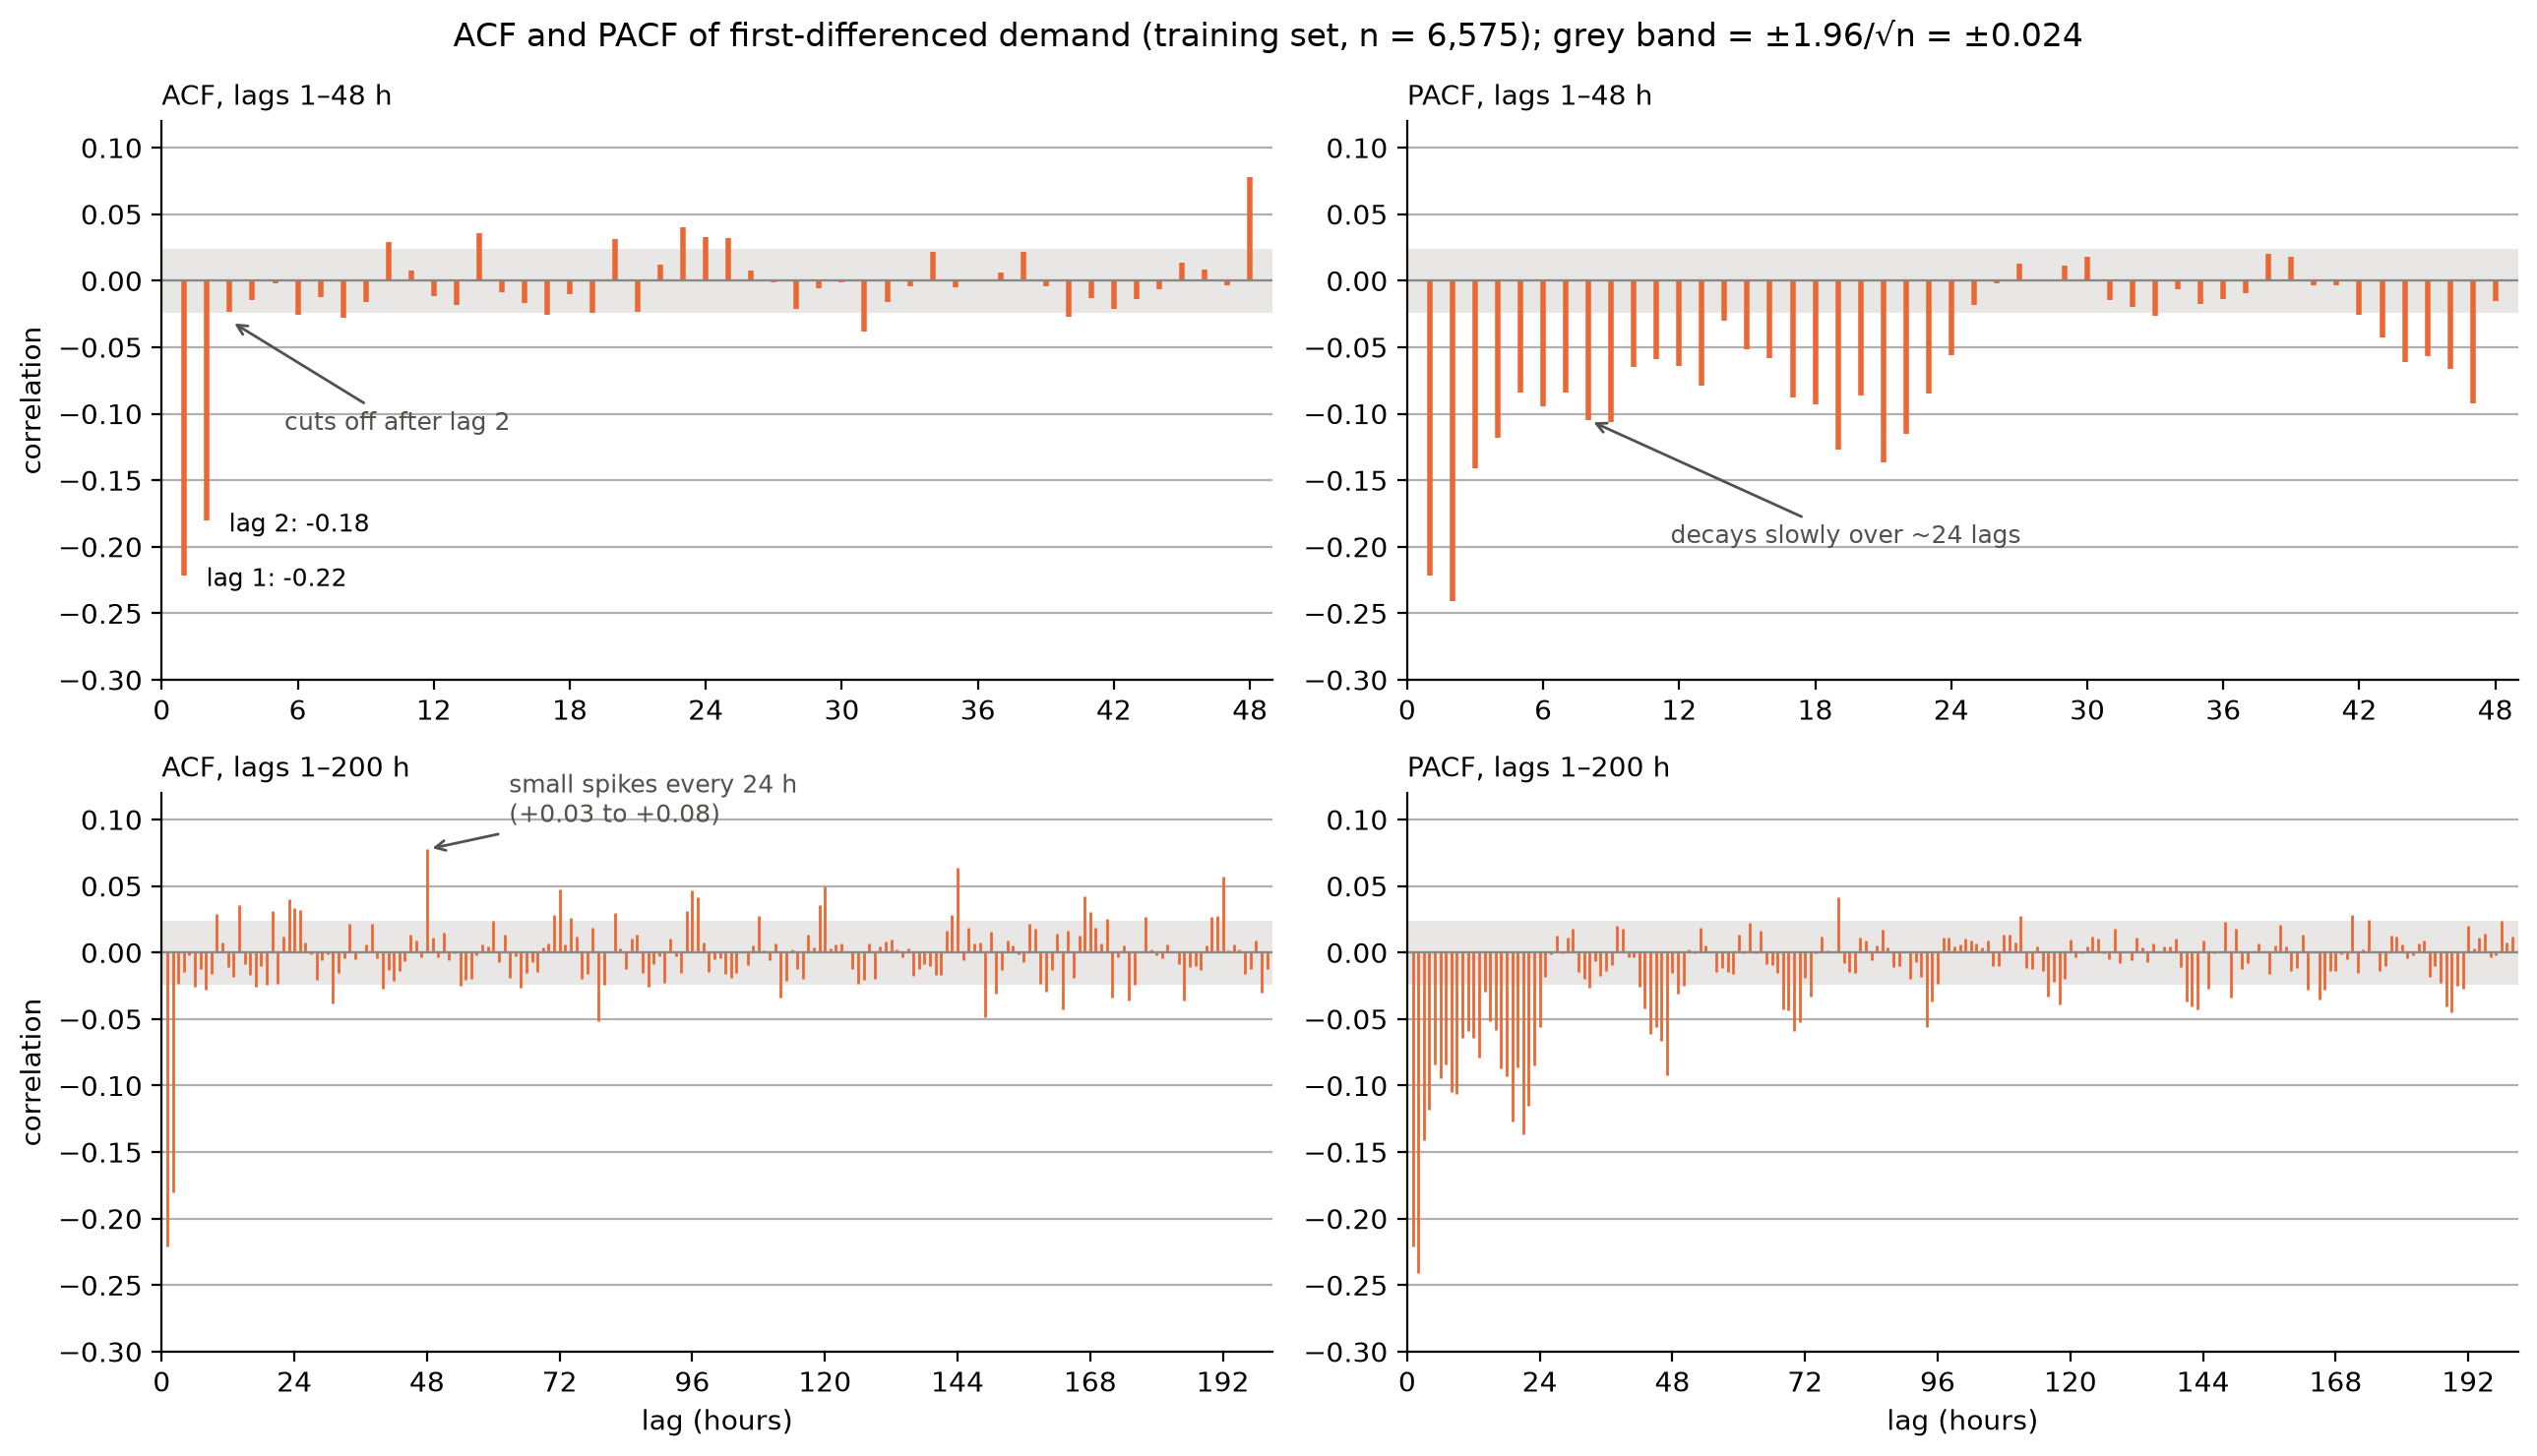

In [23]:
project.analyse_acf_pacf(df)
show(project.ACF_PACF_FIGURE)

AIC search over ARIMA(p,1,q), p,q = 0..3, training set only (best 5):
 p  d  q    AIC
 3  1  1 3538.4
 1  1  3 3540.9
 2  1  3 3541.1
 2  1  2 3546.9
 3  1  2 3551.4


Fitted SARIMA(0,1,2)(1,0,0)24 (ACF/PACF reading)


Fitted ARIMA(3,1,1) (AIC search)

Parameters fitted on the training set:
                                  source  AIC_train  ma.L1  ma.L2  ar.S.L24  sigma2  ar.L1  ar.L2  ar.L3
model                                                                                                   
SARIMA(0,1,2)(1,0,0)24  ACF/PACF reading   3741.659 -0.527 -0.436     0.131   0.103    NaN    NaN    NaN
ARIMA(3,1,1)                  AIC search   3538.449 -0.997    NaN       NaN   0.100  0.542 -0.047  0.058



Day-ahead scores (nRMSE = RMSE / 0.5374 kWh):
                                               MAE_kWh                         nRMSE                   
set                                         validation  test walk-forward validation  test walk-forward
model                      source                                                                      
SARIMA(0,1,2)(1,0,0)24     ACF/PACF reading      0.255 0.216        0.256      0.692 0.603        0.697
ARIMA(3,1,1)               AIC search            0.267 0.214        0.238      0.693 0.605        0.684
Best baseline (per metric) baseline              0.266 0.220        0.240      0.721 0.629        0.743
Saved ./outputs/tables/266083_arima_aic_search.csv
Saved ./outputs/tables/266083_arima_parameters.csv
Saved ./outputs/tables/266083_arima_scores.csv
Saved ./data/processed/266083_arima_forecasts.csv


Saved figure to ./outputs/figures/arima_walk_forward_week.png


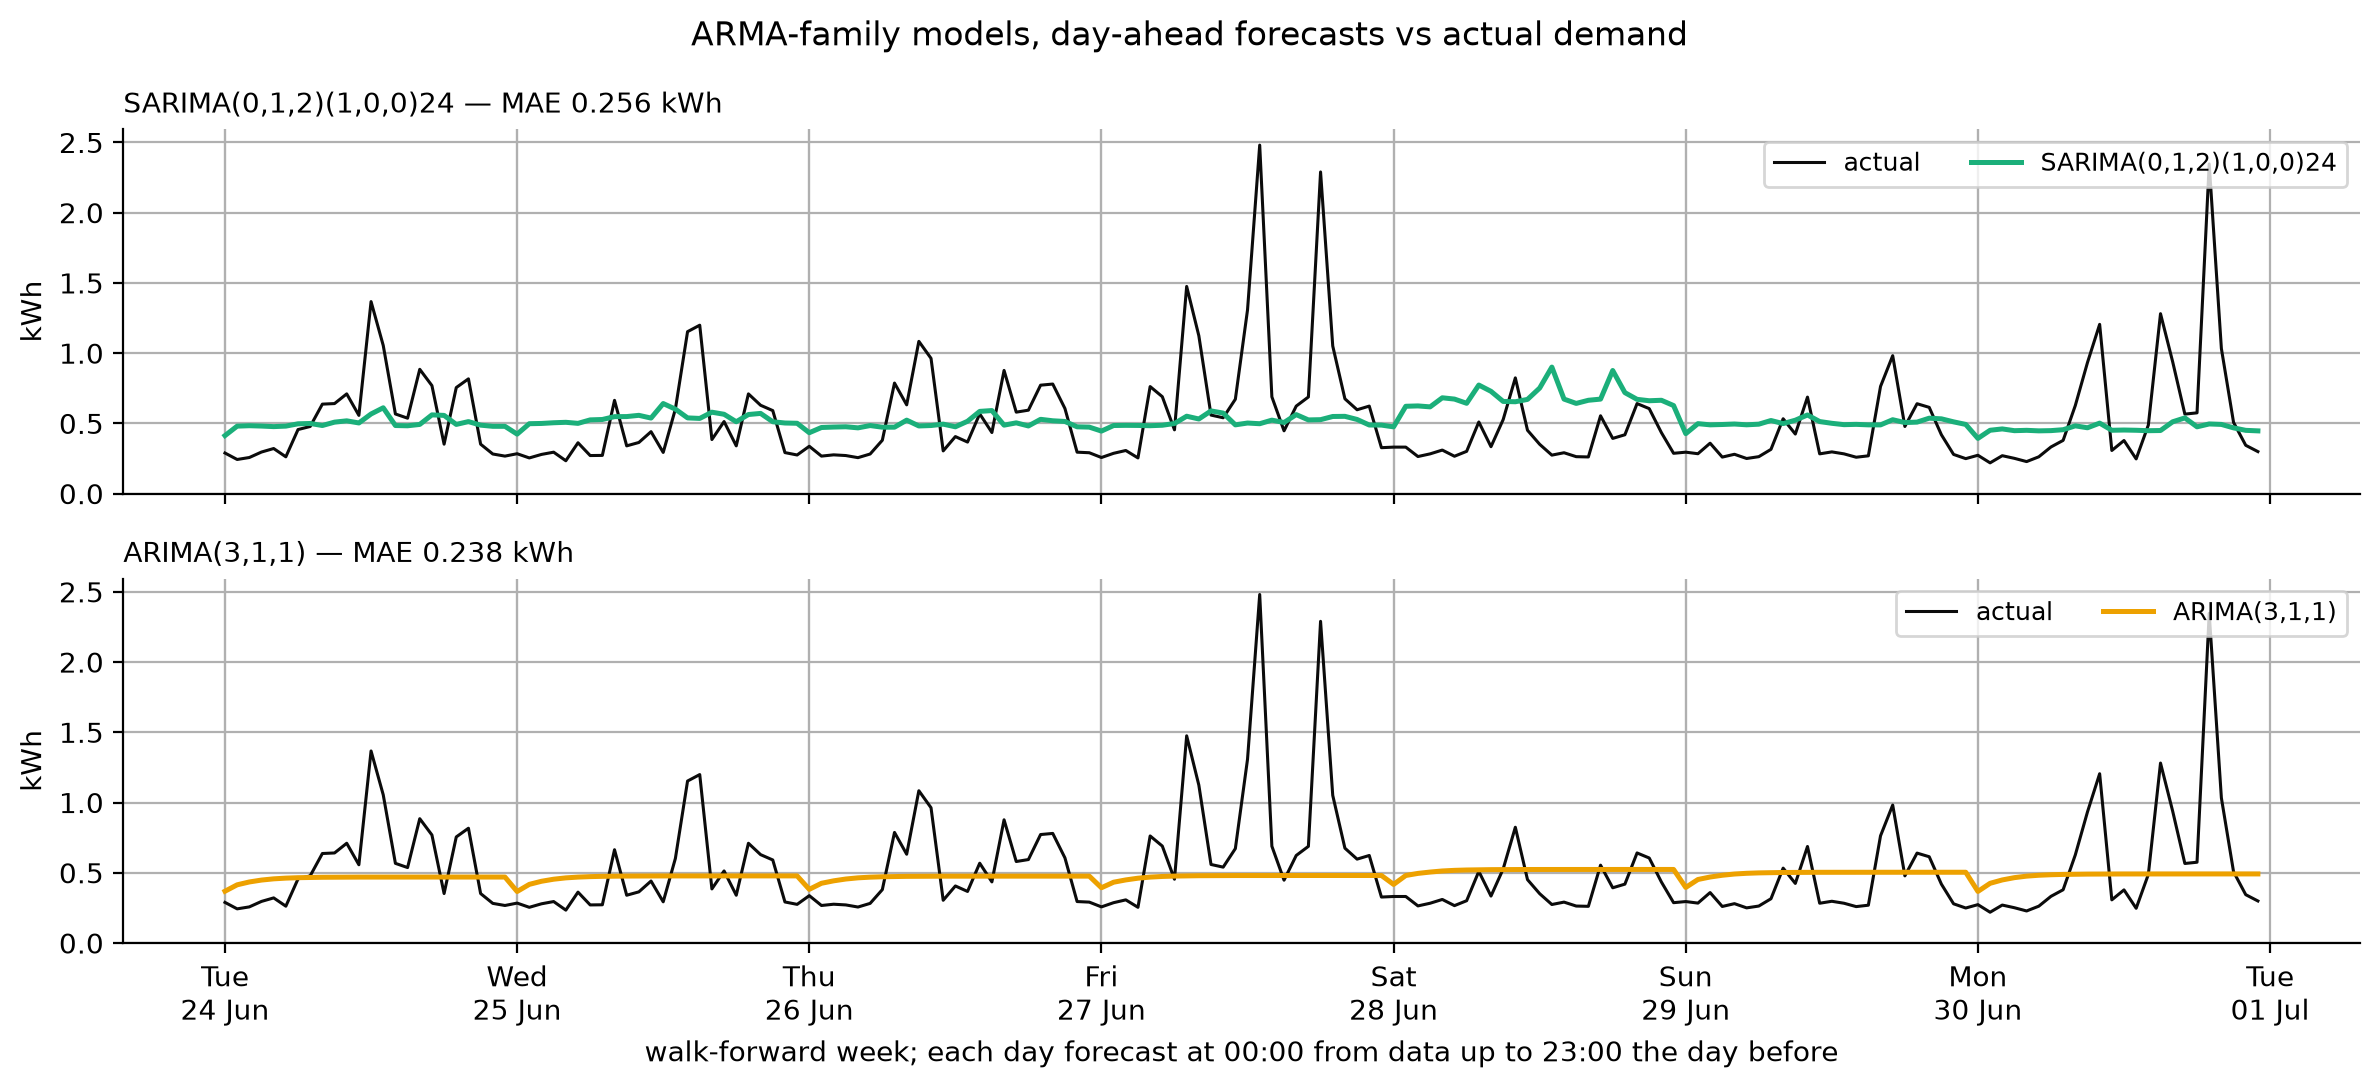

In [24]:
project.train_arima_models(df)
show(project.ARIMA_FIGURE)

In [25]:
project.compare_in_sample_walk_forward(df)

Scored SARIMA(0,1,2)(1,0,0)24


Scored ARIMA(3,1,1)
In-sample fit vs walk-forward (nRMSE = RMSE / 0.5374 kWh):
                                                          MAE_kWh                                                                                nRMSE                                                           
evaluation                              in-sample, one-step (1 h) in-sample, day-ahead (24 h) walk-forward, day-ahead (24 h) in-sample, one-step (1 h) in-sample, day-ahead (24 h) walk-forward, day-ahead (24 h)
model                  source                                                                                                                                                                                    
SARIMA(0,1,2)(1,0,0)24 ACF/PACF reading                     0.206                       0.253                          0.256                     0.602                       0.688                          0.697
ARIMA(3,1,1)           AIC search                           0.199                

,model,source,evaluation,hours,MAE_kWh,nRMSE
0,"SARIMA(0,1,2)(1,0,0)24",ACF/PACF reading,"in-sample, one-step (1 h)",6402,0.206,0.602
1,"SARIMA(0,1,2)(1,0,0)24",ACF/PACF reading,"in-sample, day-ahead (24 h)",6402,0.253,0.688
2,"SARIMA(0,1,2)(1,0,0)24",ACF/PACF reading,"walk-forward, day-ahead (24 h)",168,0.256,0.697
3,"ARIMA(3,1,1)",AIC search,"in-sample, one-step (1 h)",6402,0.199,0.593
4,"ARIMA(3,1,1)",AIC search,"in-sample, day-ahead (24 h)",6402,0.261,0.700
5,"ARIMA(3,1,1)",AIC search,"walk-forward, day-ahead (24 h)",168,0.238,0.684
6,Naive (last hour),baseline,"in-sample, day-ahead (24 h)",6378,0.301,0.888
7,Naive (last hour),baseline,"walk-forward, day-ahead (24 h)",168,0.261,0.829
8,Seasonal naive 24 h,baseline,"in-sample, day-ahead (24 h)",6401,0.269,0.863
9,Seasonal naive 24 h,baseline,"walk-forward, day-ahead (24 h)",168,0.258,0.847


Fitted SARIMAX(0,1,2)(1,0,0)24 + hour on train, AIC 2994.4


Parameters fitted on the training set:
       hour_1  hour_2  hour_3  hour_4  hour_5  hour_6  hour_7  hour_8  hour_9  hour_10  hour_11  hour_12  hour_13  hour_14  hour_15  hour_16  hour_17  hour_18  hour_19  hour_20  hour_21  hour_22  hour_23  ma.L1  ma.L2  ar.S.L24  sigma2
value  -0.059  -0.066  -0.072  -0.080  -0.058  +0.044  +0.194  +0.312  +0.266   +0.266   +0.224   +0.245   +0.222   +0.240   +0.171   +0.242   +0.344   +0.429   +0.392   +0.396   +0.294   +0.193   +0.087 -0.562 -0.384    +0.003  +0.092



Same protocol, before vs after adding hour (nRMSE = RMSE / 0.5374 kWh):
                                  MAE_kWh                         nRMSE                   
set                            validation  test walk-forward validation  test walk-forward
model                                                                                     
SARIMA(0,1,2)(1,0,0)24              0.255 0.216        0.256      0.692 0.603        0.697
SARIMAX(0,1,2)(1,0,0)24 + hour      0.229 0.190        0.205      0.652 0.566        0.641
Best baseline (per metric)          0.266 0.220        0.240      0.721 0.629        0.743

Change in MAE_kWh:
              before  after  change  change_pct
set                                            
test          +0.216 +0.190  -0.026     -12.054
validation    +0.255 +0.229  -0.027     -10.545
walk-forward  +0.256 +0.205  -0.050     -19.674

Change in nRMSE:
              before  after  change  change_pct
set                                            
test   

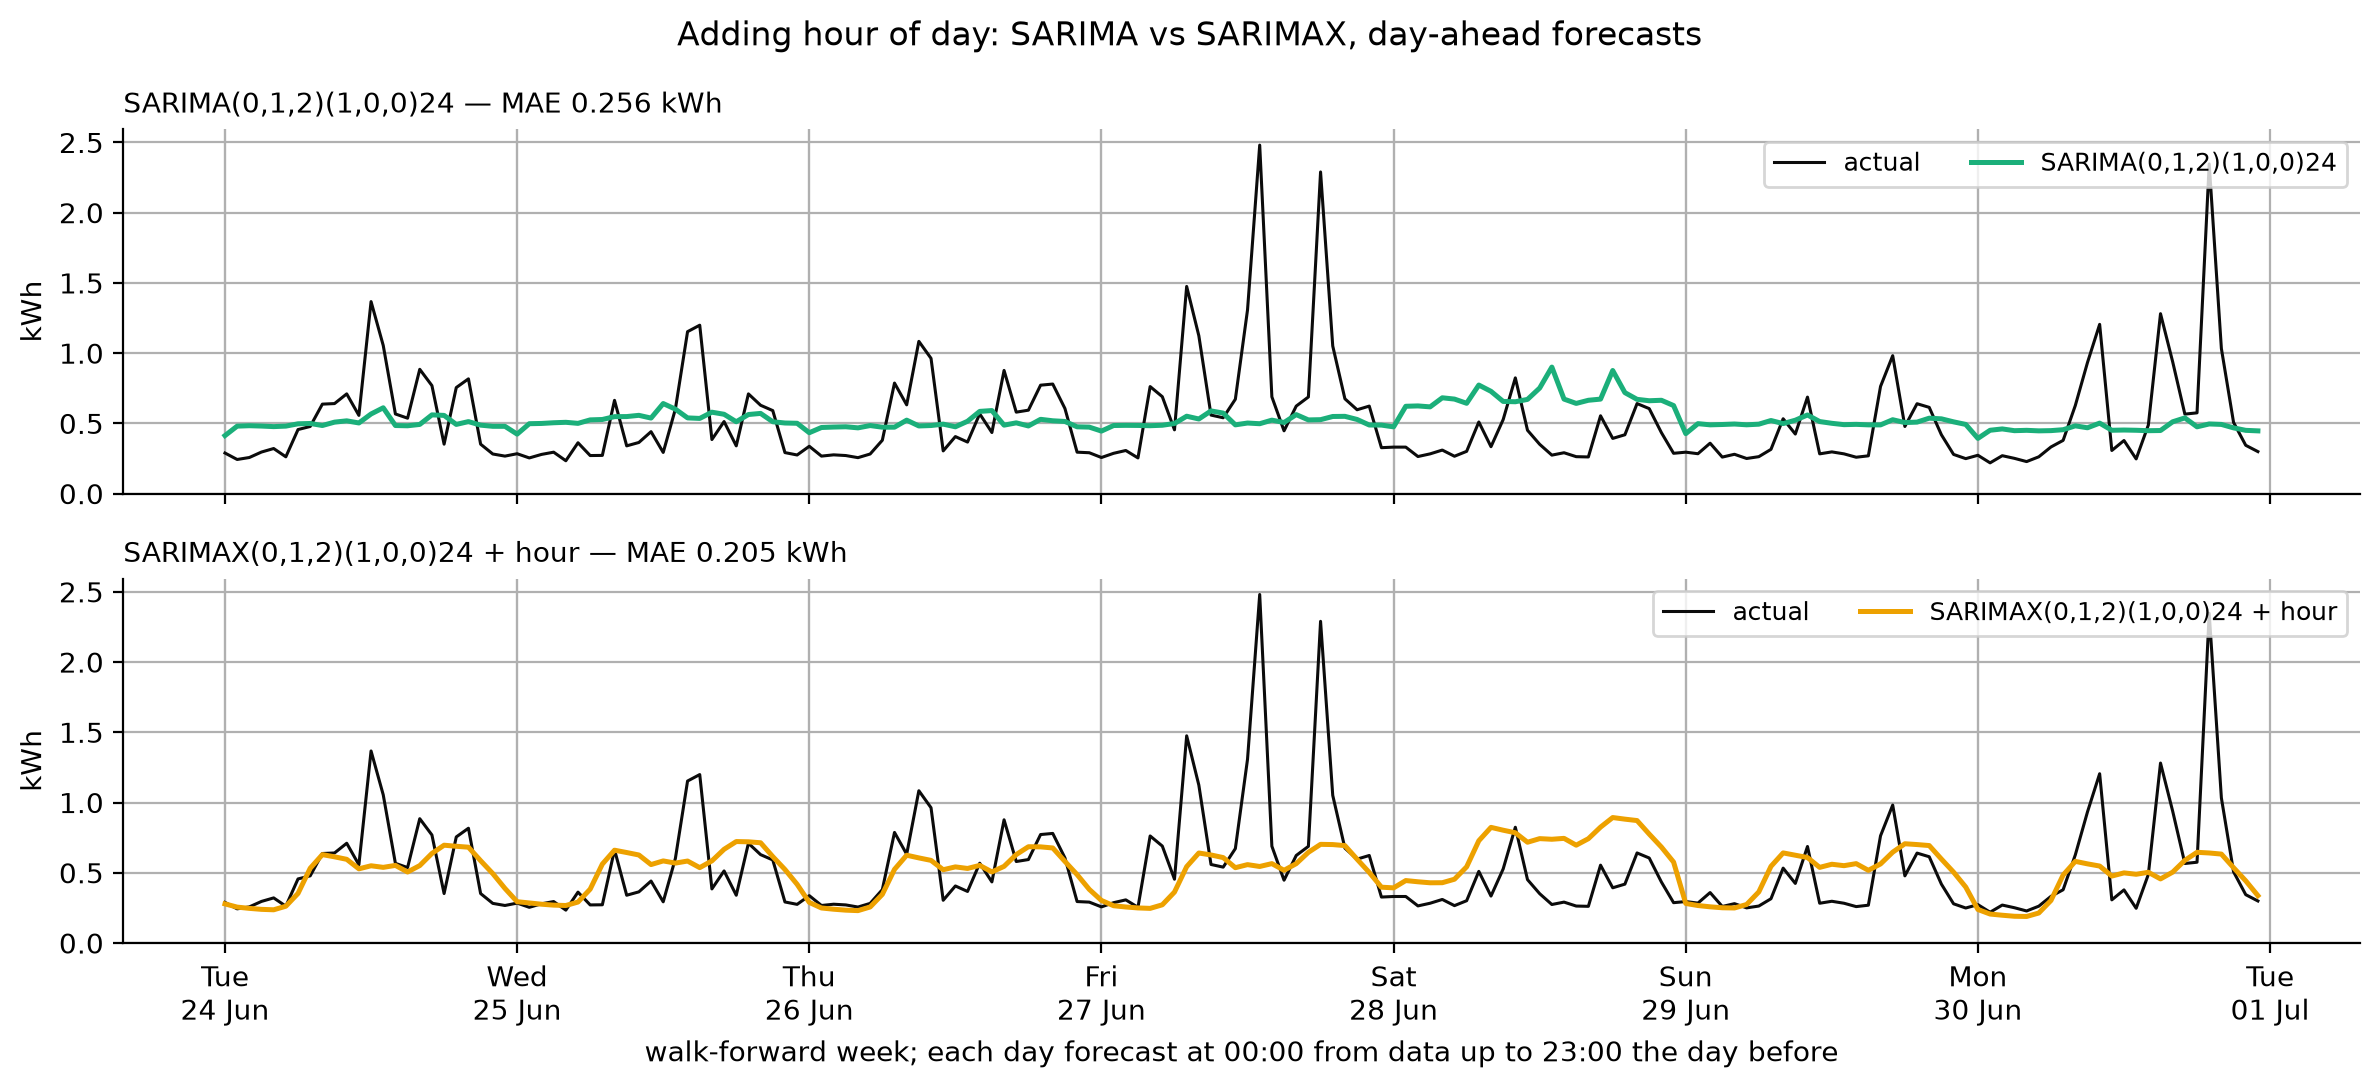

In [26]:
project.train_sarimax_hour(df)
show(project.SARIMAX_FIGURE)

# Part 7 — Out-of-sample 7-day forecast (`266083_forecast.csv`)

The reproducible pipeline in `src/pipeline.py` (also `python forecast.py`): load → clean → model → **rolling
day-by-day forecast** (24 h horizon, 0 h lead time) for 1–7 July 2014 → evaluation against the Task 7 baselines.

Two multi-step strategies are run: **recursive** (SARIMAX + hour) and **multi-output** (one ridge model predicting all
24 hours at once from yesterday's 24 values). The multi-output model is the best model: its 80 % prediction intervals
come from validation residuals per hour.

1. Load
  266083_training.csv: 8,759 rows, 2013-07-01 – 2014-06-30
  266083_forecast.csv: 168 rows, 2014-07-01 – 2014-07-07
2. Clean
source               issue                  
266083_training.csv  metering outage (0 kWh)    5
                     missing timestamp          1
  normaliser (training-split mean demand) = 0.5374 kWh
3–4. Recursive: SARIMAX(0,1,2)(1,0,0)24 + hour, rolling day-by-day forecast


  forecast Tue 01 Jul 2014 from data up to 30 Jun 23:00 (8,760 h)


  forecast Wed 02 Jul 2014 from data up to 01 Jul 23:00 (8,784 h)


  forecast Thu 03 Jul 2014 from data up to 02 Jul 23:00 (8,808 h)


  forecast Fri 04 Jul 2014 from data up to 03 Jul 23:00 (8,832 h)


  forecast Sat 05 Jul 2014 from data up to 04 Jul 23:00 (8,856 h)


  forecast Sun 06 Jul 2014 from data up to 05 Jul 23:00 (8,880 h)


  forecast Mon 07 Jul 2014 from data up to 06 Jul 23:00 (8,904 h)
3–4. Multi-output: Multi-output ridge (yesterday's 24 h), rolling day-by-day forecast
5. Evaluate
forecast        Multi-output ridge (yesterday's 24 h)  SARIMAX(0,1,2)(1,0,0)24 + hour  Naive (last hour)  Seasonal naive 24 h  Seasonal naive 168 h  Moving average 24 h
period                                                                                                                                                                  
Tue 01 Jul                                      0.237                           0.218              0.234                0.320                 0.249                0.281
Wed 02 Jul                                      0.233                           0.229              0.213                0.317                 0.181                0.236
Thu 03 Jul                                      0.186                           0.183              0.025                0.206                 0.206             

Saved ./outputs/tables/266083_interval_width_by_step.csv
Saved ./data/processed/266083_forecast_week_intervals.csv
Saved ./outputs/figures/forecast_day_prediction_interval.png
Saved ./outputs/tables/266083_forecast_week_best_vs_seasonal_naive.csv
Saved ./outputs/tables/266083_forecast_week_error_by_step.csv
Saved ./outputs/figures/forecast_week_error_by_step.png


Saved ./data/processed/266083_forecast_week_predictions.csv
Saved ./outputs/tables/266083_forecast_week_scores.csv
Saved ./outputs/tables/266083_forecast_week_cleaning_log.csv
Saved ./outputs/figures/forecast_week_rolling.png


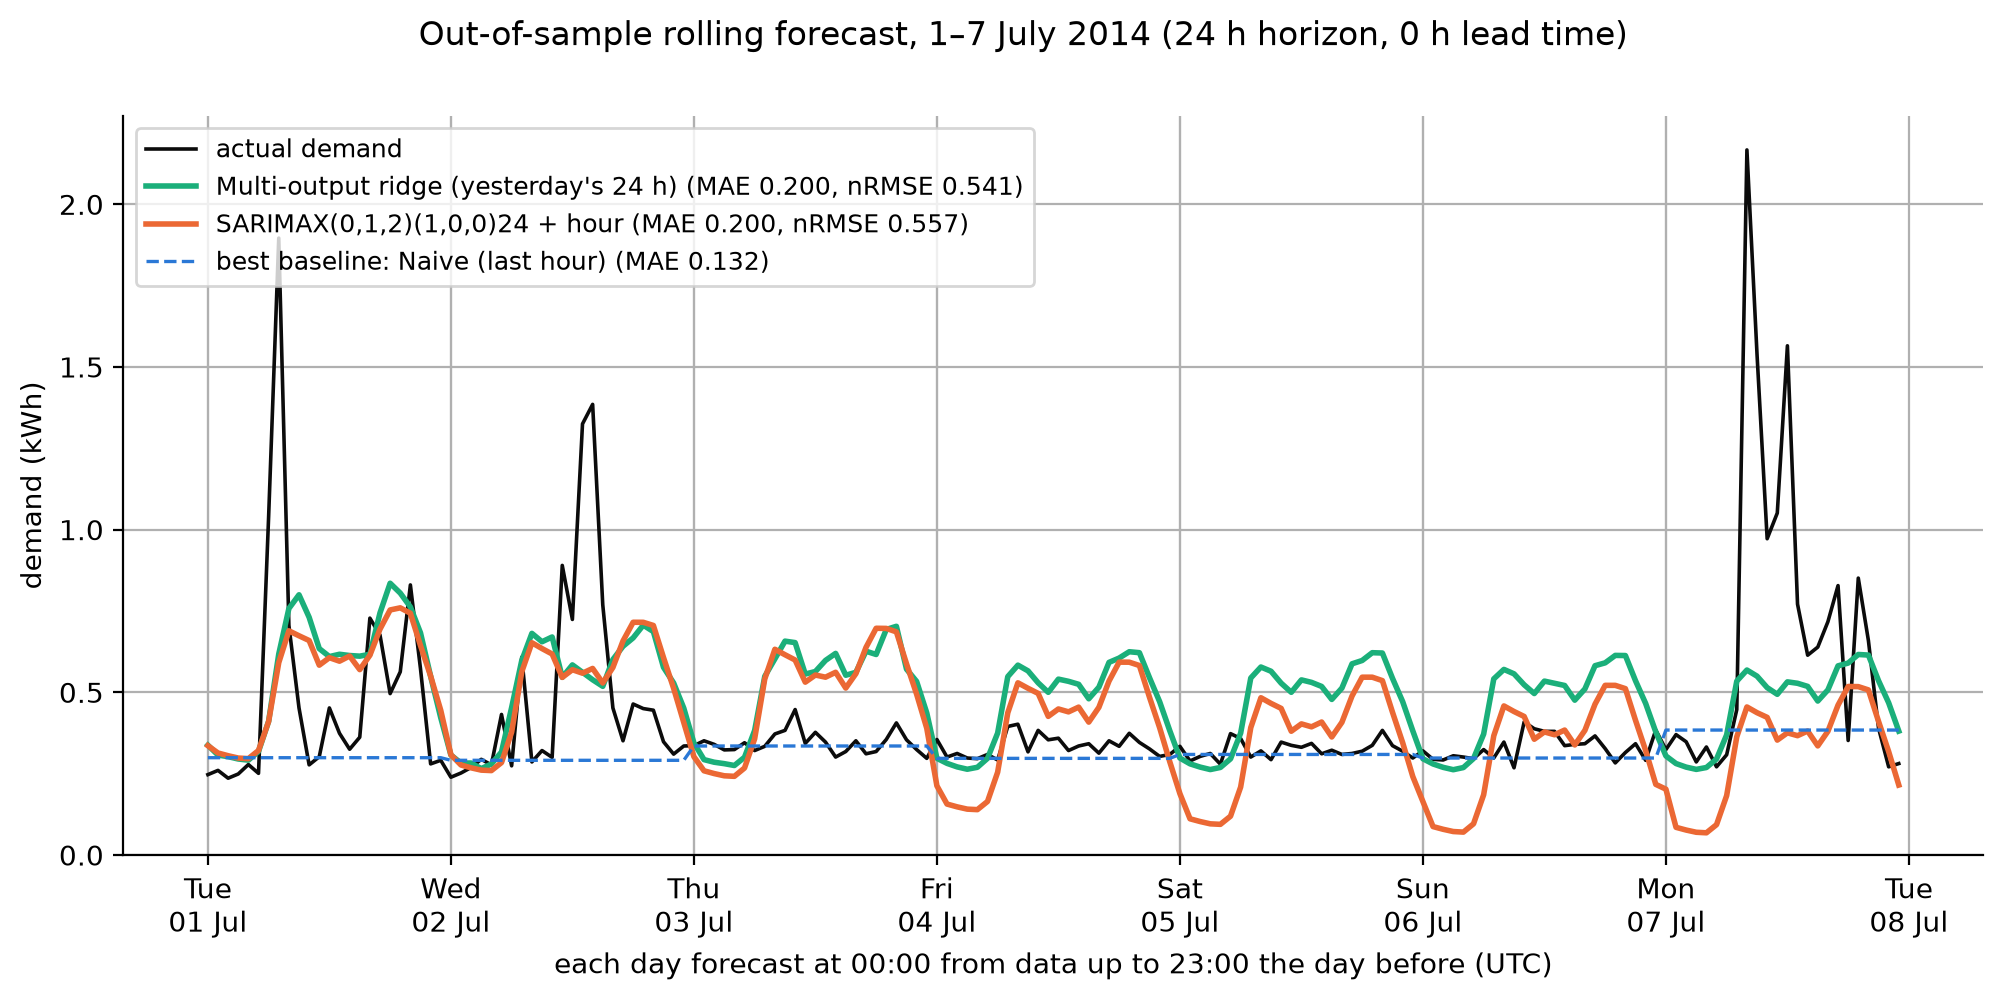

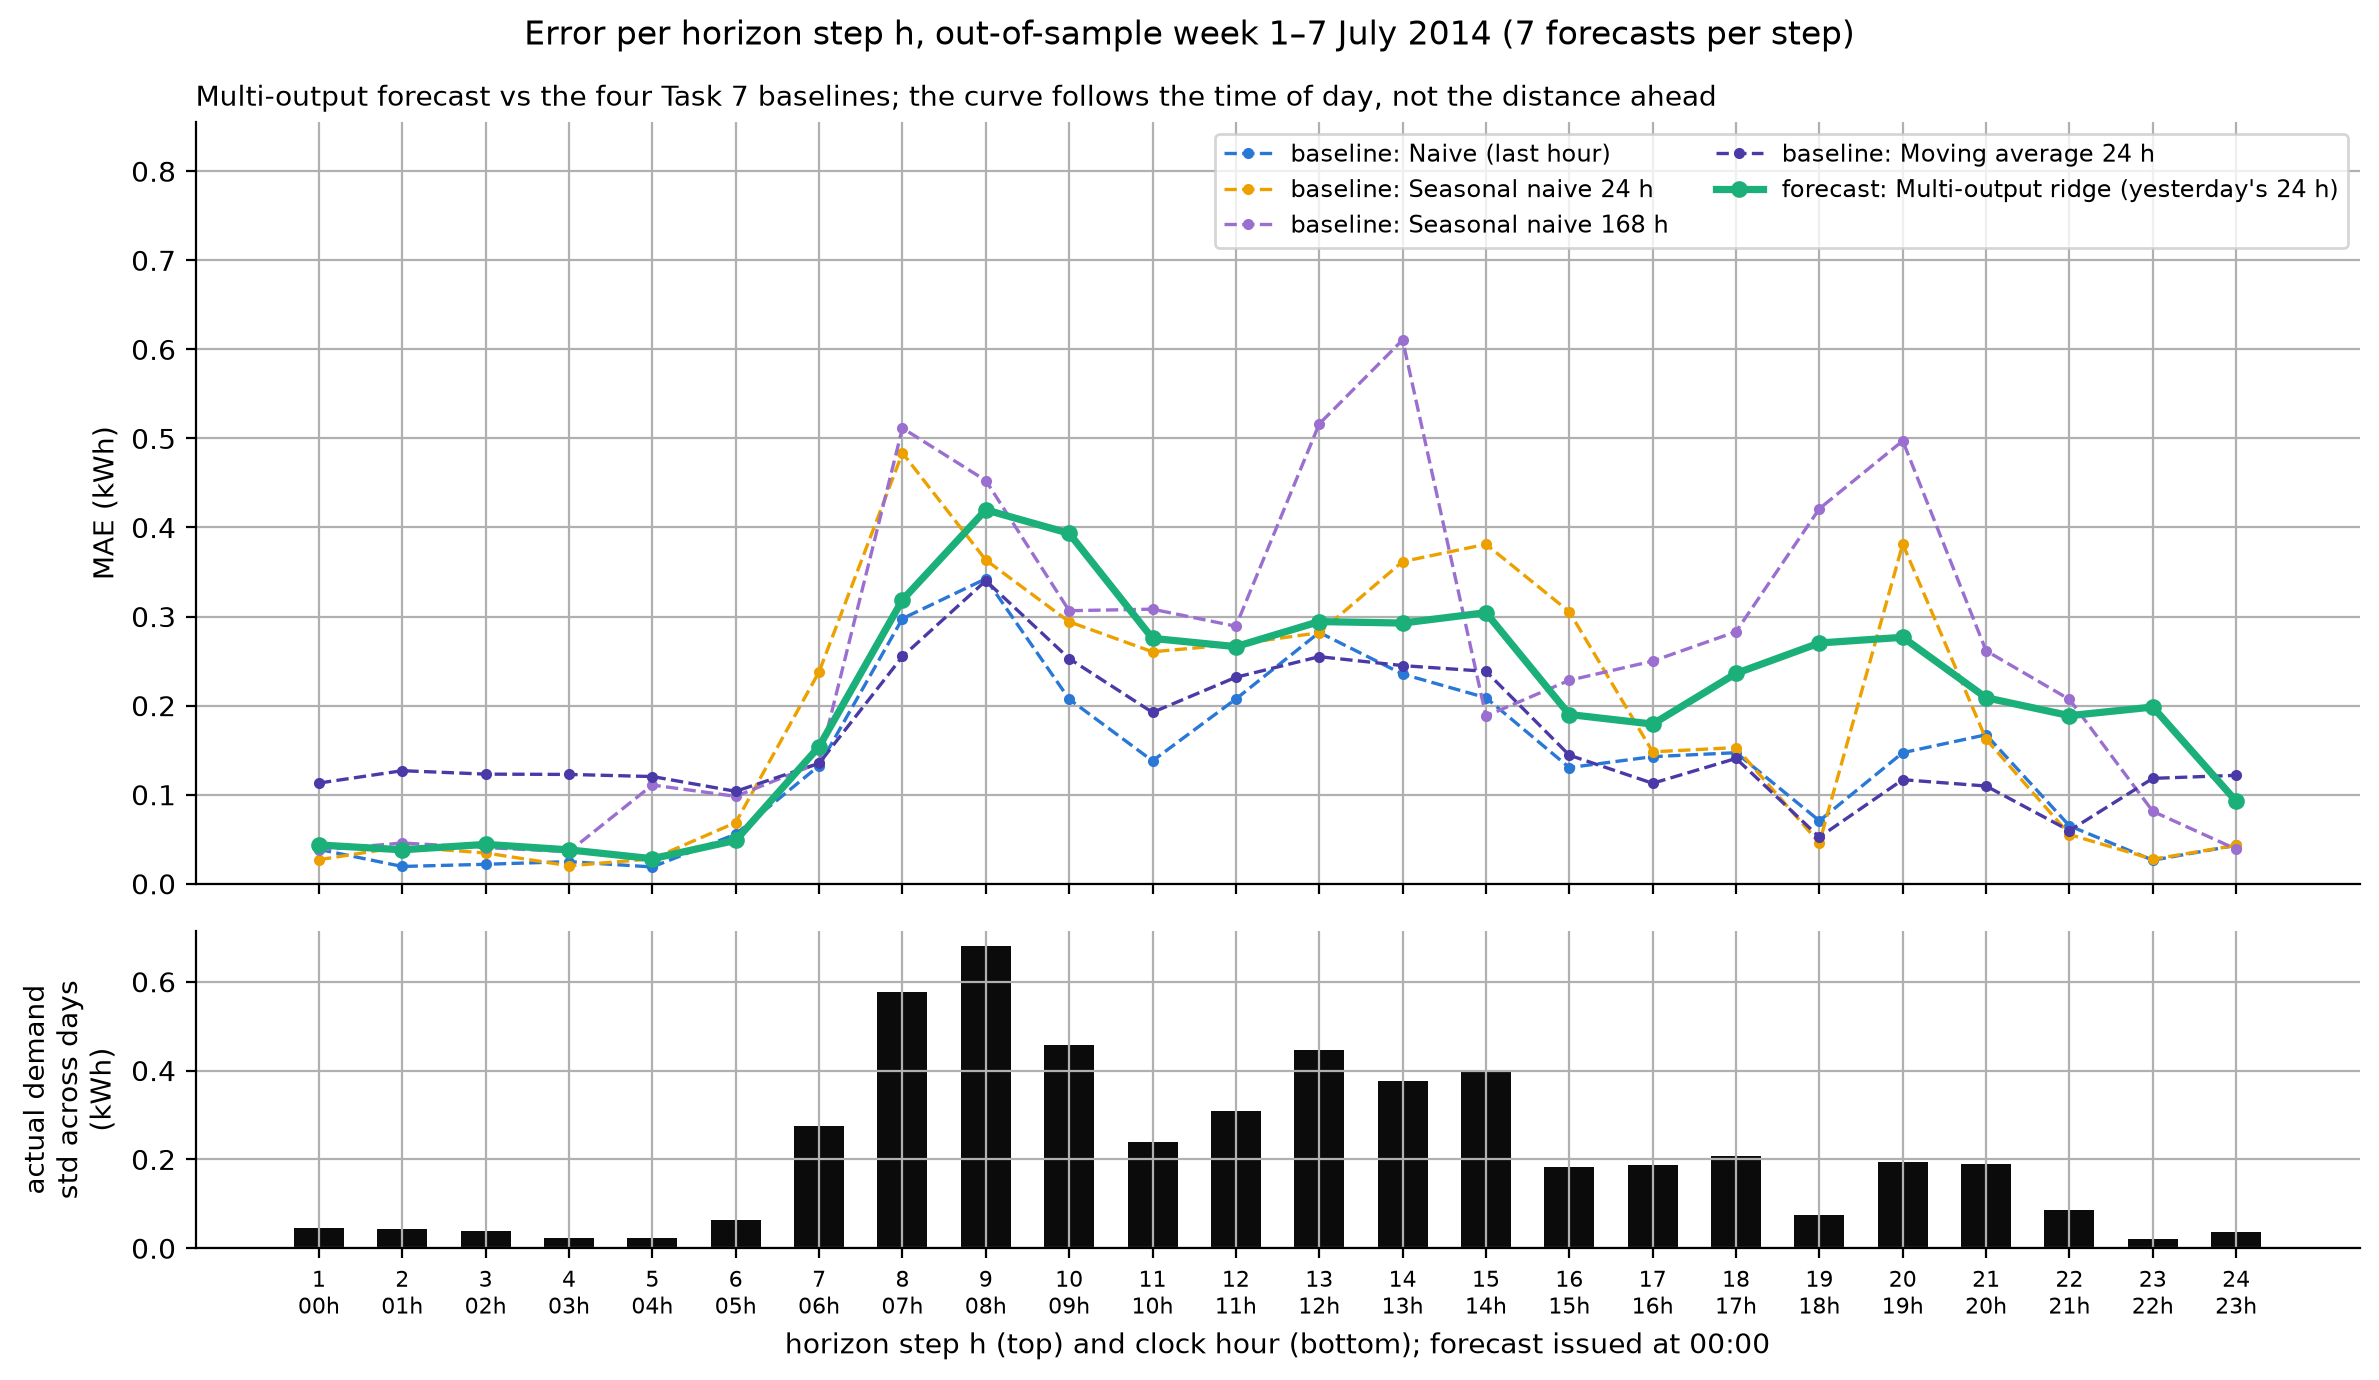

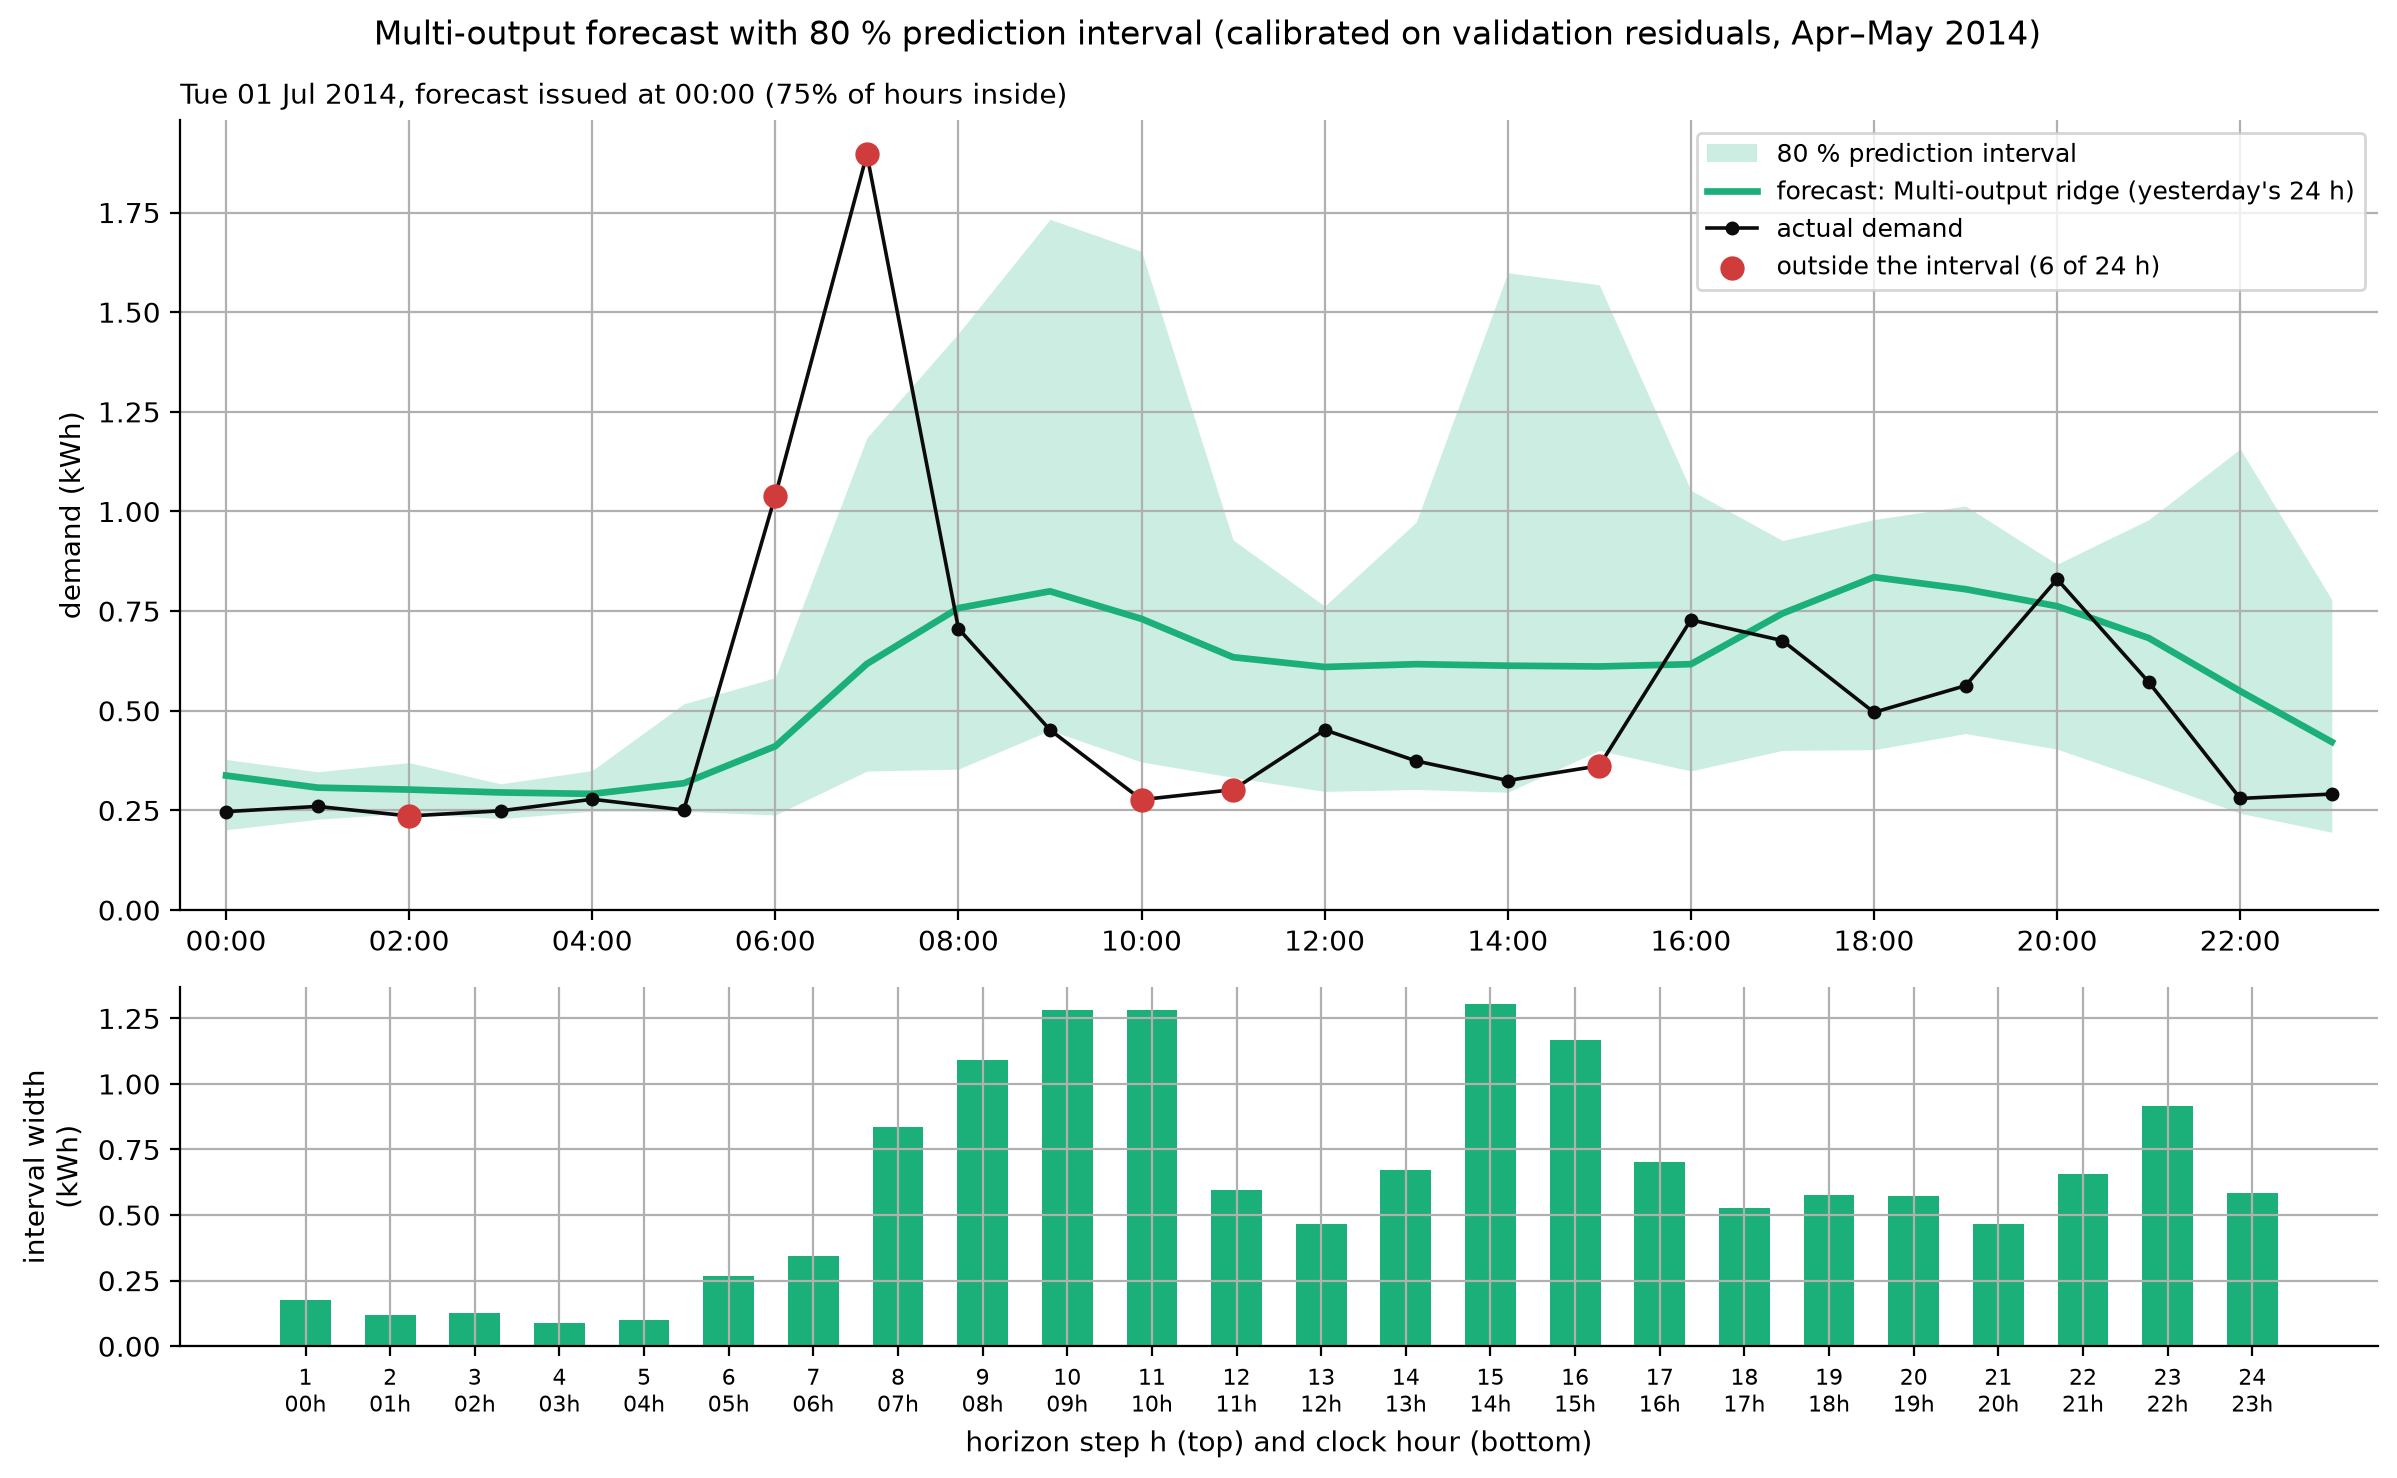

In [27]:
week_scores = project.run_forecast_pipeline()
from src import pipeline
show(pipeline.FIGURE_NAME, pipeline.STEP_FIGURE_NAME, pipeline.INTERVAL_FIGURE_NAME)

### Error by horizon and training window
Error per step on the 61 validation days for both strategies, and whether the multi-output model should train on
all earlier days or only a recent window.

Error by step, 61 validation days (step 1 = 00:00):
     multi-output                  recursive                               
       clock_hour MAE_kWh RMSE_kWh   MAE_kWh RMSE_kWh model_forecast_se_kWh
step                                                                       
1               0   0.088    0.120     0.107    0.163                 0.303
2               1   0.058    0.140     0.102    0.191                 0.330
3               2   0.041    0.048     0.090    0.116                 0.331
4               3   0.038    0.046     0.090    0.117                 0.331
5               4   0.038    0.060     0.095    0.123                 0.332
6               5   0.088    0.150     0.141    0.199                 0.332
7               6   0.138    0.211     0.159    0.233                 0.332
8               7   0.292    0.468     0.281    0.465                 0.333
9               8   0.372    0.518     0.353    0.509                 0.333
10              9   0.426    0.643  

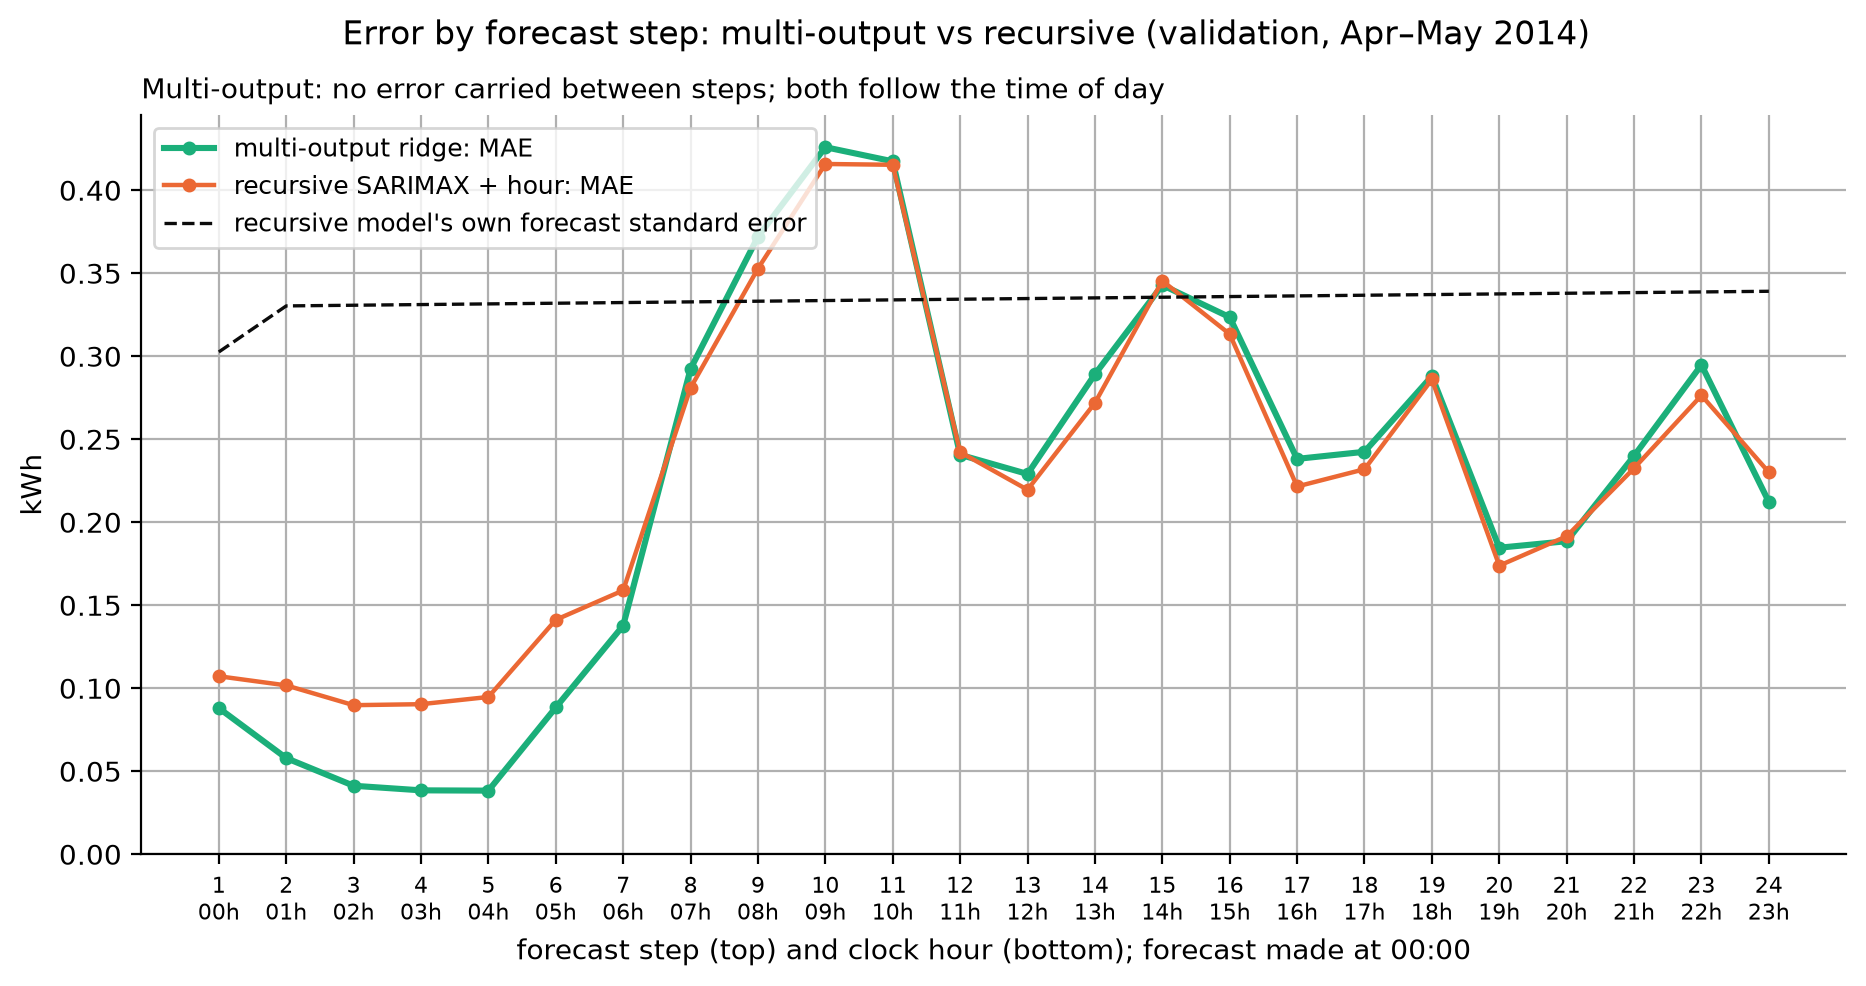

In [28]:
project.error_by_horizon(df)
show(project.HORIZON_FIGURE)

Training window × ridge strength, 61 validation days, refitted every day:
           MAE_kWh                         nRMSE                    
alpha    10.000    100.000   1,000.000 10.000    100.000   1,000.000
window                                                              
14 days      0.236     0.233     0.232     0.664     0.655     0.655
30 days      0.241     0.235     0.234     0.668     0.653     0.653
60 days      0.239     0.237     0.238     0.660     0.650     0.651
90 days      0.239     0.237     0.238     0.667     0.654     0.655
180 days     0.235     0.235     0.241     0.663     0.652     0.659
all days     0.225     0.221     0.224     0.654     0.644     0.648
At alpha = 100: lowest MAE with 'all days' (0.221); 30 days gives 0.235
Saved ./outputs/tables/266083_multi_output_training_window.csv
Saved figure to ./outputs/figures/multi_output_training_window.png


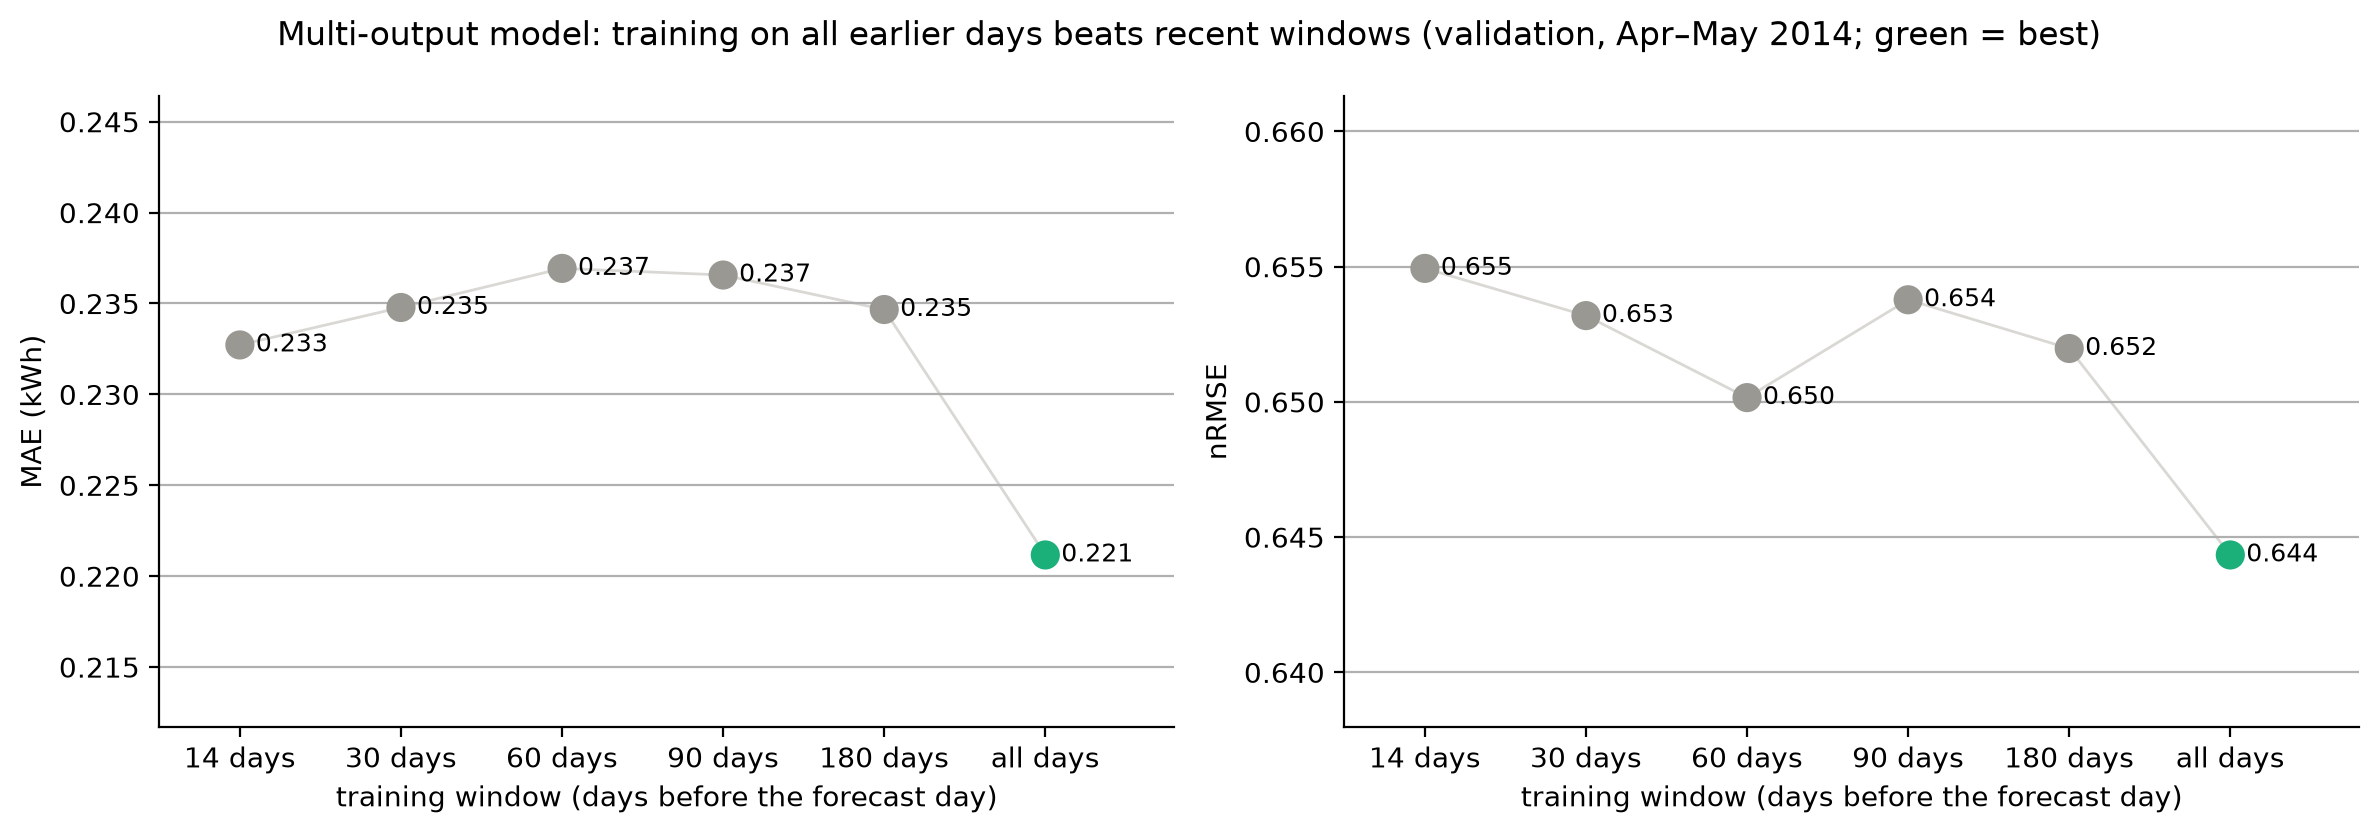

In [29]:
project.compare_training_windows(df)
show(project.WINDOW_FIGURE)

# Conclusions

- **Data:** demand is right-skewed with a base load of ~0.2 kWh, peaks on cold-season evenings, and has weak links to
  weather (strongest: daily temperature, ρ = −0.33). `pv_mod1–3` are copies of `pv` with different missingness
  mechanisms; linear interpolation is the best fill for `pv_mod1` offline, forward fill online.
- **Protocol:** time-ordered split, fixed normaliser 0.5374 kWh, the best baseline on validation sets the bar
  (MAE 0.266, nRMSE 0.721).
- **Models:** SARIMA read from the ACF/PACF beats the bar slightly; adding hour of day (SARIMAX) improves MAE by
  10–20 %. The multi-output ridge model is best overall (validation MAE 0.221, nRMSE 0.644).
- **Out-of-sample week:** the multi-output model has the lowest nRMSE (0.541) but loses on 4–6 July, when the household
  appears to have been away and "copy yesterday" was almost perfect. Error and interval width follow the time of day,
  not the distance ahead, because the multi-output strategy feeds no forecasts back in.
- **Next step:** an occupancy/absence signal, chosen on validation.